In [ ]:
import os
from google.colab import drive

drive.mount("/content/drive")

# Ajustar a la carpeta del proyecto en Drive
FIG_DIR = "/content/drive/MyDrive/Proyecto_Integrador_II/figuras"
os.makedirs(FIG_DIR, exist_ok=True)

Mounted at /content/drive


# 1. Etapa 1 - Inspección inicial y consolidación de los datos

## 1.1 OE1 - Descargar los datos y verificar integridad, formato y licencia de uso

In [ ]:
import requests

url = "https://api.github.com/repos/bolgebrygg/Force-2020-Machine-Learning-competition/contents/lithology_competition/data"
resp = requests.get(url)
resp.raise_for_status()
for item in resp.json():
    print(item["name"], item["size"], item["download_url"])

hidden_test.csv 30292497 https://raw.githubusercontent.com/bolgebrygg/Force-2020-Machine-Learning-competition/master/lithology_competition/data/hidden_test.csv
las_files_Lithostrat_data 0 None
leaderboard_test_features.csv 31688732 https://raw.githubusercontent.com/bolgebrygg/Force-2020-Machine-Learning-competition/master/lithology_competition/data/leaderboard_test_features.csv
leaderboard_test_target.csv 3694123 https://raw.githubusercontent.com/bolgebrygg/Force-2020-Machine-Learning-competition/master/lithology_competition/data/leaderboard_test_target.csv
penalty_matrix.npy 1280 https://raw.githubusercontent.com/bolgebrygg/Force-2020-Machine-Learning-competition/master/lithology_competition/data/penalty_matrix.npy
starter_notebook.ipynb 367026 https://raw.githubusercontent.com/bolgebrygg/Force-2020-Machine-Learning-competition/master/lithology_competition/data/starter_notebook.ipynb
test_code.py 1172 https://raw.githubusercontent.com/bolgebrygg/Force-2020-Machine-Learning-competition

In [ ]:
import requests, io, zipfile, hashlib, os

api_url = "https://api.github.com/repos/bolgebrygg/Force-2020-Machine-Learning-competition/contents/lithology_competition/data"
items = {i["name"]: i for i in requests.get(api_url).json() if i.get("download_url")}

def git_blob_sha1(data):
    header = f"blob {len(data)}\0".encode()
    return hashlib.sha1(header + data).hexdigest()

os.makedirs("/content/force2020", exist_ok=True)
wanted = ["train.zip", "hidden_test.csv", "leaderboard_test_features.csv",
          "leaderboard_test_target.csv", "penalty_matrix.npy"]

content = {}
for name in wanted:
    meta = items[name]
    data = requests.get(meta["download_url"]).content
    assert len(data) == meta["size"], f"{name}: tamaño no coincide"
    assert git_blob_sha1(data) == meta["sha"], f"{name}: hash no coincide"
    with open(f"/content/force2020/{name}", "wb") as f:
        f.write(data)
    content[name] = data
    print(name, "OK", len(data), "bytes")

train.zip OK 91653972 bytes
hidden_test.csv OK 30292497 bytes
leaderboard_test_features.csv OK 31688732 bytes
leaderboard_test_target.csv OK 3694123 bytes
penalty_matrix.npy OK 1280 bytes


In [ ]:
import zipfile

with zipfile.ZipFile("/content/force2020/train.zip") as z:
  print(z.namelist())
  with z.open(z.namelist()[0]) as f:
    for _ in range(2):
        print(repr(f.readline().decode()))

for name in ["hidden_test.csv", "leaderboard_test_features.csv", "leaderboard_test_target.csv"]:
    with open(f"/content/force2020/{name}", encoding="utf-8") as f:
        print(name)
        for _ in range(2):
            print(repr(f.readline()))

['train.csv']
'WELL;DEPTH_MD;X_LOC;Y_LOC;Z_LOC;GROUP;FORMATION;CALI;RSHA;RMED;RDEP;RHOB;GR;SGR;NPHI;PEF;DTC;SP;BS;ROP;DTS;DCAL;DRHO;MUDWEIGHT;RMIC;ROPA;RXO;FORCE_2020_LITHOFACIES_LITHOLOGY;FORCE_2020_LITHOFACIES_CONFIDENCE\r\n'
'15/9-13;494.528;437641.96875;6470972.5;-469.5018311;NORDLAND GP.;;19.480834961;;1.6114097834;1.7986813784;1.884185791;80.20085144;;;20.915468216;161.13117981;24.612379074;;34.63640976;;;-0.574927628;;;;;65000;1.0\r\n'
hidden_test.csv
'WELL;DEPTH_MD;X_LOC;Y_LOC;Z_LOC;GROUP;FORMATION;CALI;RSHA;RMED;RDEP;RHOB;GR;SGR;NPHI;PEF;DTC;SP;BS;ROP;DTS;DCAL;DRHO;MUDWEIGHT;RMIC;ROPA;RXO;FORCE_2020_LITHOFACIES_LITHOLOGY;FORCE_2020_LITHOFACIES_CONFIDENCE\n'
'15/9-23;1518.28;433906.75;6460000.5;-1493.241821;HORDALAND GP.;Skade Fm.;15.506232262;;;0.8786152601;;103.4515152;;0.439925462;;147.04342651;;17.5;146.52627563;326.45126343;-1.993767977;0.1097061411;;;88.968864441;;65000;3.0\n'
leaderboard_test_features.csv
'WELL;DEPTH_MD;X_LOC;Y_LOC;Z_LOC;GROUP;FORMATION;CALI;RSHA;RMED;RD

In [ ]:
import pandas as pd, zipfile

with zipfile.ZipFile("/content/force2020/train.zip") as z:
    with z.open("train.csv") as f:
        train = pd.read_csv(f, sep=";")

hidden = pd.read_csv("/content/force2020/hidden_test.csv", sep=";")
lb_feat = pd.read_csv("/content/force2020/leaderboard_test_features.csv", sep=";")
lb_target = pd.read_csv("/content/force2020/leaderboard_test_target.csv", sep=";")

for name, df in [("train", train), ("hidden_test", hidden),
                  ("leaderboard_features", lb_feat), ("leaderboard_target", lb_target)]:
    print(name, df.shape, df["WELL"].nunique(), "pozos")

check = lb_feat.merge(lb_target, on=["WELL", "DEPTH_MD"], how="left")
print("filas leaderboard sin target tras el join:", check["FORCE_2020_LITHOFACIES_LITHOLOGY"].isna().sum())

train (1170511, 29) 98 pozos
hidden_test (122397, 29) 10 pozos
leaderboard_features (136786, 27) 10 pozos
leaderboard_target (136786, 3) 10 pozos
filas leaderboard sin target tras el join: 0


## 1.2 OE2 - Levantar el inventario de pozos, señalando cuáles tienen etiqueta de litofacies y cuáles no

In [ ]:
import pandas as pd
import zipfile
import requests
from io import BytesIO

BASE_URL = "https://raw.githubusercontent.com/bolgebrygg/Force-2020-Machine-Learning-competition/master/lithology_competition/data"
LABEL_COL = "FORCE_2020_LITHOFACIES_LITHOLOGY"

def read_csv_from_github(filename, **kwargs):
    r = requests.get(f"{BASE_URL}/{filename}")
    r.raise_for_status()
    return pd.read_csv(BytesIO(r.content), sep=";", **kwargs)

r = requests.get(f"{BASE_URL}/train.zip")
r.raise_for_status()
with zipfile.ZipFile(BytesIO(r.content)) as z:
    with z.open("train.csv") as f:
        train = pd.read_csv(f, sep=";")

hidden_test = read_csv_from_github("hidden_test.csv")
lb_feat = read_csv_from_github("leaderboard_test_features.csv")
lb_target = read_csv_from_github("leaderboard_test_target.csv")
leaderboard_test = lb_feat.merge(lb_target, on=["WELL", "DEPTH_MD"], how="left")

sources = {"train": train, "hidden_test": hidden_test, "leaderboard_test": leaderboard_test}

In [ ]:
rows = []
for src, df in sources.items():
    g = df.groupby("WELL")[LABEL_COL].agg(n_filas="size", n_con_etiqueta=lambda s: s.notna().sum())
    g["archivo_origen"] = src
    rows.append(g.reset_index())

inventario = pd.concat(rows, ignore_index=True)
inventario["pct_cobertura"] = (inventario["n_con_etiqueta"] / inventario["n_filas"] * 100).round(2)

def categoria(pct):
    if pct == 100.0:
        return "completo"
    if pct == 0.0:
        return "sin_etiqueta"
    return "parcial"

inventario["categoria"] = inventario["pct_cobertura"].apply(categoria)
inventario = inventario.rename(columns={"WELL": "pozo"})[
    ["pozo", "archivo_origen", "n_filas", "n_con_etiqueta", "pct_cobertura", "categoria"]
]

print(inventario["categoria"].value_counts())
print(inventario[inventario["categoria"] != "completo"])

categoria
completo    118
Name: count, dtype: int64
Empty DataFrame
Columns: [pozo, archivo_origen, n_filas, n_con_etiqueta, pct_cobertura, categoria]
Index: []


## 1.3 OE3 - Caracterizar la estructura de la tabla

In [ ]:
import pandas as pd

base_url = "https://raw.githubusercontent.com/bolgebrygg/Force-2020-Machine-Learning-competition/master/lithology_competition/data"

train = pd.read_csv(f"{base_url}/train.zip", sep=";")
hidden_test = pd.read_csv(f"{base_url}/hidden_test.csv", sep=";")
lb_features = pd.read_csv(f"{base_url}/leaderboard_test_features.csv", sep=";")
lb_target = pd.read_csv(f"{base_url}/leaderboard_test_target.csv", sep=";")

leaderboard_test = lb_features.merge(lb_target, on=["WELL", "DEPTH_MD"], how="inner")
assert len(leaderboard_test) == len(lb_features)

train["source"] = "train"
hidden_test["source"] = "hidden_test"
leaderboard_test["source"] = "leaderboard_test"

pool = pd.concat([train, hidden_test, leaderboard_test], ignore_index=True)

print(pool.shape)
print(pool["WELL"].nunique())

(1429694, 30)
118


In [ ]:
numeric_cols = pool.select_dtypes(include="number").columns.drop(["X_LOC", "Y_LOC", "Z_LOC", "DEPTH_MD"])

summary = pool[numeric_cols].describe(percentiles=[.01, .5, .99]).T
summary["n_missing"] = pool[numeric_cols].isna().sum()
summary["pct_missing"] = (summary["n_missing"] / len(pool) * 100).round(1)

summary = summary[["count", "n_missing", "pct_missing", "min", "1%", "50%", "99%", "max"]]
print(summary.round(3))

                                       count  n_missing  pct_missing  \
CALI                               1332729.0      96965          6.8   
RSHA                                695430.0     734264         51.4   
RMED                               1380297.0      49397          3.5   
RDEP                               1418609.0      11085          0.8   
RHOB                               1241937.0     187757         13.1   
GR                                 1429694.0          0          0.0   
SGR                                  70492.0    1359202         95.1   
NPHI                                966012.0     463682         32.4   
PEF                                 885634.0     544060         38.1   
DTC                                1343902.0      85792          6.0   
SP                                  977599.0     452095         31.6   
BS                                  824110.0     605584         42.4   
ROP                                 694537.0     735157         

In [ ]:
sentinel_candidates = [-999, -999.25, -999.5, -999.9, -9999, 9999, 10000]

print("=== coincidencias con centinelas conocidos ===")
for col in numeric_cols:
    vals = pool[col].dropna().round(3)
    counts = vals.value_counts()
    hits = counts[counts.index.isin(sentinel_candidates)]
    for val, n in hits.items():
        print(f"{col}: {val} -> {n} veces ({n/len(vals)*100:.2f}% del no nulo)")

print("\n=== valor mas frecuente por curva, si cae en zona fisicamente extrema ===")
for col in numeric_cols:
    vals = pool[col].dropna().round(3)
    top_val = vals.value_counts().index[0]
    top_count = vals.value_counts().iloc[0]
    if top_count > 20 and (top_val < -100 or top_val > 5000):
        print(f"{col}: {top_val} -> {top_count} veces ({top_count/len(vals)*100:.2f}% del no nulo)")

=== coincidencias con centinelas conocidos ===
SP: -999.0 -> 402 veces (0.04% del no nulo)
RMIC: 10000.0 -> 3 veces (0.00% del no nulo)
ROPA: -999.25 -> 24 veces (0.01% del no nulo)
RXO: -999.0 -> 18172 veces (4.96% del no nulo)
RXO: -999.9 -> 16309 veces (4.45% del no nulo)

=== valor mas frecuente por curva, si cae en zona fisicamente extrema ===
RXO: -999.0 -> 18172 veces (4.96% del no nulo)
FORCE_2020_LITHOFACIES_LITHOLOGY: 65000 -> 876605 veces (61.31% del no nulo)


In [ ]:
def depth_step_stats(g):
    d = g.sort_values("DEPTH_MD")["DEPTH_MD"]
    steps = d.diff().dropna()
    return steps.min(), steps.max(), steps.mode().iloc[0], (d.diff() <= 0).any()

rows = []
for well, g in pool.groupby("WELL"):
    step_min, step_max, step_mode, non_monotonic = depth_step_stats(g)
    rows.append((well, g["source"].iloc[0], len(g), step_min, step_max, step_mode, non_monotonic))

steps_df = pd.DataFrame(rows, columns=["WELL", "source", "n_rows", "step_min", "step_max", "step_mode", "non_monotonic"])

print(steps_df["step_mode"].value_counts())
print(steps_df["non_monotonic"].value_counts())
print(steps_df.groupby("source")["step_mode"].describe())

step_mode
0.152    118
Name: count, dtype: int64
non_monotonic
False    118
Name: count, dtype: int64
                  count   mean  std    min    25%    50%    75%    max
source                                                                
hidden_test        10.0  0.152  0.0  0.152  0.152  0.152  0.152  0.152
leaderboard_test   10.0  0.152  0.0  0.152  0.152  0.152  0.152  0.152
train              98.0  0.152  0.0  0.152  0.152  0.152  0.152  0.152


In [ ]:
uniform = steps_df["step_min"] == steps_df["step_max"]
print(uniform.value_counts())

irregular = steps_df.loc[~uniform, ["WELL", "source", "n_rows", "step_min", "step_max"]]
print(irregular)

False    118
Name: count, dtype: int64
        WELL            source  n_rows  step_min  step_max
0    15/9-13             train   18270     0.152     0.760
1    15/9-14  leaderboard_test   20281     0.152     1.520
2    15/9-15             train   17717     0.152    10.944
3    15/9-17             train   17350     0.152     5.168
4    15/9-23       hidden_test   11063     0.152    10.336
..       ...               ...     ...       ...       ...
113   35/9-7       hidden_test   10677     0.152     0.152
114   35/9-8  leaderboard_test    4274     0.152    39.368
115   36/7-3             train    3628     0.152     5.928
116    7/1-1             train   16241     0.152     0.152
117  7/1-2 S             train    2040     0.152     0.152

[118 rows x 5 columns]


Nota: esta verificación usa 0.1524 m como paso nominal, valor corregido después a 0.152 m (sección 2.3). La detección de huecos no cambia: ningún paso normal supera 0.1524 m y todos los huecos son múltiplos de al menos dos pasos.

In [ ]:
import numpy as np

tol = 1e-6
rows = []
for well, g in pool.groupby("WELL"):
    d = g.sort_values("DEPTH_MD")["DEPTH_MD"].to_numpy()
    steps = np.diff(d)
    gaps = steps[steps > 0.1524 + tol]
    rows.append((well, len(gaps), gaps.max() if len(gaps) else 0.0, gaps.sum() if len(gaps) else 0.0))

gaps_df = pd.DataFrame(rows, columns=["WELL", "n_gaps", "max_gap", "total_gap"])

print((gaps_df["n_gaps"] == 0).sum(), "de 118 pozos sin ningun hueco")
print(gaps_df["n_gaps"].describe())
print(gaps_df["max_gap"].describe())

61 de 118 pozos sin ningun hueco
count    118.000000
mean       1.508475
std        2.345192
min        0.000000
25%        0.000000
50%        0.000000
75%        2.000000
max       11.000000
Name: n_gaps, dtype: float64
count    118.000000
mean       9.156068
std       29.276841
min        0.000000
25%        0.000000
50%        0.000000
75%        7.676000
max      269.344000
Name: max_gap, dtype: float64


In [ ]:
print(pool[["X_LOC", "Y_LOC", "Z_LOC", "DEPTH_MD"]].describe())
print("GROUP:", pool["GROUP"].nunique(), "categorias -", sorted(pool["GROUP"].dropna().unique())[:8])
print("FORMATION:", pool["FORMATION"].nunique(), "categorias")

              X_LOC         Y_LOC         Z_LOC      DEPTH_MD
count  1.418849e+06  1.418849e+06  1.418849e+06  1.429694e+06
mean   4.847318e+05  6.680447e+06 -2.166688e+03  2.216632e+03
std    3.522739e+04  1.315229e+05  9.590261e+02  9.929555e+02
min    4.232375e+05  6.406641e+06 -5.395563e+03  1.360860e+02
25%    4.544695e+05  6.571040e+06 -2.839056e+03  1.457365e+03
50%    4.786488e+05  6.737678e+06 -2.088677e+03  2.121598e+03
75%    5.201532e+05  6.784888e+06 -1.430059e+03  2.895131e+03
max    5.726328e+05  6.856661e+06 -1.110860e+02  5.436632e+03
GROUP: 14 categorias - ['BAAT GP.', 'BOKNFJORD GP.', 'CROMER KNOLL GP.', 'DUNLIN GP.', 'HEGRE GP.', 'HORDALAND GP.', 'NORDLAND GP.', 'ROGALAND GP.']
FORMATION: 70 categorias


## 1.4 OE4 - Cuantificar valores faltantes por curva y por pozo, y la distribución de clases de roca

In [ ]:
import numpy as np

sentinels = {"SP": [-999.0], "RMIC": [10000.0], "ROPA": [-999.25], "RXO": [-999.0, -999.9]}

pool_clean = pool.copy()
for col, vals in sentinels.items():
    pool_clean.loc[pool_clean[col].isin(vals), col] = np.nan

curves = ["CALI", "BS", "DCAL", "RHOB", "DRHO", "GR", "SGR", "NPHI", "PEF", "DTC",
          "DTS", "SP", "ROP", "RSHA", "RMED", "RDEP", "RMIC", "RXO", "MUDWEIGHT", "ROPA"]
location_cols = ["X_LOC", "Y_LOC", "Z_LOC"]

missing_pct = pool_clean.groupby("WELL")[curves + location_cols].apply(lambda g: g.isna().mean() * 100)

bins = [0, 1, 5, 10, 25, 50, 75, 90, 95, 99, 100.01]
print(pd.cut(missing_pct[curves].values.flatten(), bins).value_counts().sort_index())
print()
print(pd.cut(missing_pct[location_cols].values.flatten(), bins).value_counts().sort_index())

(0.0, 1.0]        338
(1.0, 5.0]        191
(5.0, 10.0]        38
(10.0, 25.0]       61
(25.0, 50.0]       83
(50.0, 75.0]       81
(75.0, 90.0]       82
(90.0, 95.0]        9
(95.0, 99.0]        2
(99.0, 100.01]    796
Name: count, dtype: int64

(0.0, 1.0]        36
(1.0, 5.0]        12
(5.0, 10.0]        0
(10.0, 25.0]       3
(25.0, 50.0]       3
(50.0, 75.0]       0
(75.0, 90.0]       0
(90.0, 95.0]       0
(95.0, 99.0]       0
(99.0, 100.01]     0
Name: count, dtype: int64


In [ ]:
def missing_segments(mask):
    arr = mask.to_numpy()
    ids = np.cumsum(np.r_[True, arr[1:] != arr[:-1]])
    seg = pd.Series(arr, index=ids)
    return seg[seg].groupby(level=0).size()

pool_sorted = pool_clean.sort_values(["WELL", "DEPTH_MD"])

rows = []
for well, g in pool_sorted.groupby("WELL"):
    for curve in curves:
        mask = g[curve].isna()
        pct = mask.mean() * 100
        if pct == 0 or pct == 100:
            continue
        segs = missing_segments(mask)
        n_missing = mask.sum()
        rows.append((well, curve, pct, len(segs), segs.max() / n_missing * 100,
                     bool(mask.iloc[0]), bool(mask.iloc[-1])))

runs_df = pd.DataFrame(rows, columns=[
    "well", "curve", "pct_missing", "n_segments", "max_segment_pct",
    "touches_start", "touches_end"
])

runs_df["pattern"] = np.select(
    [
        (runs_df.n_segments == 1) & (runs_df.touches_start | runs_df.touches_end),
        (runs_df.n_segments == 1) & ~(runs_df.touches_start | runs_df.touches_end),
    ],
    ["corrida_parcial_borde", "hueco_interior_unico"],
    default="disperso_multiple_tramos",
)

print(runs_df["pattern"].value_counts())
print(runs_df.groupby("pattern")["pct_missing"].describe()[["count", "mean", "min", "50%", "max"]])

pattern
disperso_multiple_tramos    420
corrida_parcial_borde       370
hueco_interior_unico         95
Name: count, dtype: int64
                          count       mean       min       50%        max
pattern                                                                  
corrida_parcial_borde     370.0  19.677808  0.004088  2.275151  88.857366
disperso_multiple_tramos  420.0  25.515357  0.026492  3.971583  98.535354
hueco_interior_unico       95.0   2.904159  0.007958  0.563426  67.829970


In [ ]:
bins = [0, 1, 5, 10, 25, 50, 75, 90, 100]
print(pd.crosstab(pd.cut(runs_df.pct_missing, bins), runs_df.pattern))

pattern      corrida_parcial_borde  disperso_multiple_tramos  \
pct_missing                                                    
(0, 1]                         148                       124   
(1, 5]                          73                        99   
(5, 10]                         14                        20   
(10, 25]                        26                        32   
(25, 50]                        42                        39   
(50, 75]                        40                        40   
(75, 90]                        27                        55   
(90, 100]                        0                        11   

pattern      hueco_interior_unico  
pct_missing                        
(0, 1]                         66  
(1, 5]                         19  
(5, 10]                         4  
(10, 25]                        3  
(25, 50]                        2  
(50, 75]                        1  
(75, 90]                        0  
(90, 100]                       0  

In [ ]:
exact_full = (missing_pct[curves] == 0).sum().sum()
exact_absent = (missing_pct[curves] == 100).sum().sum()
fractional = ((missing_pct[curves] > 0) & (missing_pct[curves] < 100)).sum().sum()
print(exact_full, exact_absent, fractional)

no_corrida = missing_pct[curves] == 100

curve_summary = pd.DataFrame({
    "pct_missing_global": pool_clean[curves].isna().mean().mul(100).round(2),
    "pozos_no_corrida": no_corrida.sum(),
})
curve_summary["pozos_corrida"] = 118 - curve_summary["pozos_no_corrida"]
curve_summary["pct_pozos_no_corrida"] = (curve_summary["pozos_no_corrida"] / 118 * 100).round(1)
curve_summary = curve_summary.sort_values("pct_pozos_no_corrida", ascending=False)
print(curve_summary)

runs_df["nota"] = np.select(
    [
        (runs_df.pattern == "corrida_parcial_borde") & (runs_df.pct_missing > 10),
        (runs_df.pattern == "disperso_multiple_tramos") & (runs_df.pct_missing > 75),
    ],
    ["posible_corrida_en_subtramo", "corrida_pero_casi_ausente"],
    default="faltante_puntual_ordinario",
)
print(runs_df["nota"].value_counts())
print(runs_df.groupby("curve")["nota"].value_counts().unstack(fill_value=0))

borderline = runs_df[runs_df.pct_missing >= 90].sort_values("pct_missing", ascending=False)
print(borderline[["well", "curve", "pct_missing", "pattern"]].to_string(index=False))

well_summary = no_corrida.sum(axis=1).rename("curvas_no_corridas").to_frame()
notas_pozo = runs_df.pivot_table(index="well", columns="nota", values="curve", aggfunc="count", fill_value=0)
well_summary = well_summary.join(notas_pozo, how="left").fillna(0).astype(int)
print(well_summary.sort_values("curvas_no_corridas", ascending=False).head(15))

loc_missing = pool_clean[location_cols].isna().mean().mul(100).round(3)
print(loc_missing)

missing_pct.round(2).to_csv("/content/faltantes_pozo_curva.csv")

679 796 885
           pct_missing_global  pozos_no_corrida  pozos_corrida  \
SGR                     95.07               104             14   
DCAL                    75.14                90             28   
MUDWEIGHT               76.47                89             29   
RMIC                    85.83                85             33   
ROPA                    78.15                81             37   
RXO                     75.66                75             43   
DTS                     79.67                72             46   
ROP                     51.42                51             67   
SP                      31.65                42             76   
RSHA                    51.36                36             82   
BS                      42.36                35             83   
PEF                     38.05                30             88   
DRHO                    15.25                 4            114   
CALI                     6.78                 1            117  

In [ ]:
lithology_keys = {
    30000: "Sandstone", 65030: "Sandstone/Shale", 65000: "Shale", 80000: "Marl",
    74000: "Dolomite", 70000: "Limestone", 70032: "Chalk", 88000: "Halite",
    86000: "Anhydrite", 99000: "Tuff", 90000: "Coal", 93000: "Basement",
}

codes = pool_clean["FORCE_2020_LITHOFACIES_LITHOLOGY"]
sin_mapeo = set(codes.unique()) - set(lithology_keys)
print("codigos sin mapeo:", sin_mapeo)

clase = codes.map(lithology_keys)
class_dist = clase.value_counts()
class_pct = (class_dist / len(codes) * 100).round(2)
print(pd.DataFrame({"n": class_dist, "pct": class_pct}))

wells_por_clase = pool_clean.assign(clase=clase).groupby("clase")["WELL"].nunique().sort_values()
print(wells_por_clase)

codigos sin mapeo: set()
                                       n    pct
FORCE_2020_LITHOFACIES_LITHOLOGY               
Shale                             876605  61.31
Sandstone                         207030  14.48
Sandstone/Shale                   180296  12.61
Limestone                          69492   4.86
Marl                               41031   2.87
Tuff                               17431   1.22
Halite                             14711   1.03
Chalk                              14043   0.98
Coal                                4754   0.33
Dolomite                            2391   0.17
Anhydrite                           1807   0.13
Basement                             103   0.01
clase
Basement             1
Halite               4
Anhydrite           10
Chalk               15
Dolomite            47
Coal                63
Tuff                67
Marl                92
Limestone          114
Sandstone/Shale    117
Sandstone          118
Shale              118
Name: WELL, dtype: in

Nota: las cifras de faltantes de las celdas anteriores se calcularon con el filtro de centinelas por igualdad exacta (`isin`), que no capturó una variante de -999.9 en `RXO` ni los -999.25 de `ROPA`. El filtro se corrigió en la sección 2.2. La celda siguiente recalcula las cifras de esta sección con tolerancia y guarda en Drive el inventario de pozos y la matriz de faltantes por pozo y curva.

In [ ]:
DATA_DIR = os.path.dirname(FIG_DIR)

# mismo filtro con tolerancia que aplica la seccion 2.2; en SP y RMIC no cambia nada (verificado alli)
pool_fixed = pool.copy()
for col, vals in sentinels.items():
    for v in vals:
        pool_fixed.loc[np.isclose(pool_fixed[col], v, atol=0.01), col] = np.nan

missing_fixed = pool_fixed.groupby("WELL")[curves + location_cols].apply(lambda g: g.isna().mean() * 100)
m_old, m_new = missing_pct[curves], missing_fixed[curves]
print((m_new == 0).sum().sum(), (m_new == 100).sum().sum(), ((m_new > 0) & (m_new < 100)).sum().sum())

changed = (m_old != m_new).stack()
print(pd.DataFrame({"antes": m_old.stack()[changed], "despues": m_new.stack()[changed]}).round(3))

pct_global = pd.DataFrame({"antes": pool_clean[curves].isna().mean().mul(100),
                           "despues": pool_fixed[curves].isna().mean().mul(100)}).round(2)
print(pct_global[pct_global["antes"] != pct_global["despues"]])

fixed_rows = []
for well, g in pool_fixed.sort_values(["WELL", "DEPTH_MD"]).groupby("WELL"):
    for curve in curves:
        mask = g[curve].isna()
        pct = mask.mean() * 100
        if pct == 0 or pct == 100:
            continue
        segs = missing_segments(mask)
        fixed_rows.append((well, curve, pct, len(segs), bool(mask.iloc[0]), bool(mask.iloc[-1])))

runs_fixed = pd.DataFrame(fixed_rows, columns=["well", "curve", "pct_missing", "n_segments",
                                               "touches_start", "touches_end"])
edge = runs_fixed.touches_start | runs_fixed.touches_end
runs_fixed["pattern"] = np.select(
    [(runs_fixed.n_segments == 1) & edge, (runs_fixed.n_segments == 1) & ~edge],
    ["corrida_parcial_borde", "hueco_interior_unico"], default="disperso_multiple_tramos")
runs_fixed["nota"] = np.select(
    [(runs_fixed.pattern == "corrida_parcial_borde") & (runs_fixed.pct_missing > 10),
     (runs_fixed.pattern == "disperso_multiple_tramos") & (runs_fixed.pct_missing > 75)],
    ["posible_corrida_en_subtramo", "corrida_pero_casi_ausente"], default="faltante_puntual_ordinario")
print(runs_fixed["nota"].value_counts())
print(runs_fixed[runs_fixed["pct_missing"] >= 90].sort_values("pct_missing", ascending=False)
      [["well", "curve", "pct_missing", "pattern"]].round(2).to_string(index=False))

inventario.to_csv(f"{DATA_DIR}/etapa1_inventario_pozos.csv", index=False)
missing_fixed.round(2).to_csv(f"{DATA_DIR}/etapa1_faltantes_pozo_curva.csv")
print(os.path.exists(f"{DATA_DIR}/etapa1_inventario_pozos.csv"),
      os.path.exists(f"{DATA_DIR}/etapa1_faltantes_pozo_curva.csv"))
del pool_fixed


676 796 888
               antes  despues
WELL                         
15/9-15  RXO     0.0   25.868
25/5-4   RXO     0.0   90.221
35/11-11 ROPA    0.0    0.187
      antes  despues
RXO   75.66    76.80
ROPA  78.15    78.16
nota
faltante_puntual_ordinario     686
posible_corrida_en_subtramo    135
corrida_pero_casi_ausente       67
Name: count, dtype: int64
    well curve  pct_missing                  pattern
 25/2-14   ROP        98.54 disperso_multiple_tramos
  36/7-3  CALI        98.24 disperso_multiple_tramos
34/10-35  RSHA        94.83 disperso_multiple_tramos
  16/4-1   PEF        94.16 disperso_multiple_tramos
  25/2-7   RXO        92.50 disperso_multiple_tramos
  31/3-2  RMIC        92.35 disperso_multiple_tramos
  25/5-3  RSHA        92.34 disperso_multiple_tramos
  25/5-3   RXO        92.18 disperso_multiple_tramos
  32/2-1   DTS        92.10 disperso_multiple_tramos
 15/9-13  RSHA        91.12 disperso_multiple_tramos
 15/9-13   RXO        91.09 disperso_multiple_tramos
  2

# 2. Etapa 2 - Curación y control de calidad


## 2.1 OE1 - Definir el tratamiento de valores faltantes por curva

In [ ]:
# Verificacion de si los 135 casos de "posible_corrida_en_subtramo" estan
# anclados al techo del pozo o si hay mezcla con el fondo, y si eso varia
# por curva.

subtramo = runs_df[runs_df.nota == "posible_corrida_en_subtramo"]

print(subtramo[["touches_start", "touches_end"]].value_counts())
print()
print(subtramo.groupby("curve")[["touches_start", "touches_end"]].sum())

touches_start  touches_end
True           False          117
False          True            18
Name: count, dtype: int64

           touches_start  touches_end
curve                                
BS                     4            0
CALI                   8            0
DRHO                  11            1
DTC                    4            2
DTS                    1            1
MUDWEIGHT              2            1
NPHI                  35            0
PEF                    6            1
RDEP                   1            1
RHOB                  10            0
RMED                   2            2
RMIC                   5            0
ROP                    0            1
RSHA                   9            2
RXO                   10            1
SGR                    7            0
SP                     2            5


In [ ]:
# Verificacion de si los 66 casos de "corrida_pero_casi_ausente" esconden
# un segmmento dominante que los acerca mas al patron de borde que al
# disperso genuino

casi_ausente = runs_df[runs_df.nota == "corrida_pero_casi_ausente"]

print(casi_ausente[["well", "curve", "pct_missing", "n_segments", "max_segment_pct"]]
      .sort_values("max_segment_pct", ascending=False)
      .to_string(index=False))

       well curve  pct_missing  n_segments  max_segment_pct
   34/10-35  NPHI    82.642223           2        99.976526
    15/9-14  RSHA    80.267245           5        99.938571
   31/5-4 S  DRHO    78.637087           2        99.898842
   31/5-4 S  RHOB    78.637087           2        99.898842
   31/5-4 S  NPHI    78.504508           2        99.898671
     25/9-1   PEF    76.592771           2        99.883895
     25/9-1  RHOB    76.592771           2        99.883895
     29/6-1  NPHI    81.805919           2        99.875081
     29/6-1  RHOB    81.805919           2        99.875081
     29/6-1  DRHO    81.805919           2        99.875081
    25/2-14  NPHI    75.265152           2        99.874182
   31/5-4 S  RSHA    79.777267           8        99.833813
     31/2-7   PEF    86.444278           4        99.783206
    31/2-10  RSHA    75.965903           2        99.766832
     25/9-1  NPHI    76.776980           2        99.644246
     29/3-1   PEF    75.385124          

In [ ]:
# tamaño de tramo continuo con datos disponibles

well_groups = {w: g for w, g in pool_sorted.groupby("WELL")}

rows = []
for _, r in casi_ausente.iterrows():
    mask = well_groups[r.well][r.curve].isna()
    avail_segs = missing_segments(~mask)
    rows.append(avail_segs.max() / len(mask) * 100)

casi_ausente = casi_ausente.assign(max_available_run_pct=rows)
print(casi_ausente[["well", "curve", "pct_missing", "max_segment_pct", "max_available_run_pct"]]
      .sort_values("max_available_run_pct", ascending=False)
      .to_string(index=False))

       well curve  pct_missing  max_segment_pct  max_available_run_pct
    25/2-14  NPHI    75.265152        99.874182              24.734848
16/11-1 ST3  NPHI    75.612532        65.772466              24.387468
    31/2-10  RSHA    75.965903        99.766832              24.034097
16/11-1 ST3  RHOB    76.081135        65.059393              23.918865
16/11-1 ST3  DRHO    76.355603        65.255129              23.644397
     25/9-1   PEF    76.592771        99.883895              23.407229
     25/9-1  RHOB    76.592771        99.883895              23.407229
16/11-1 ST3  RSHA    76.757263        64.111286              23.242737
     25/9-1  NPHI    76.776980        99.644246              23.223020
  34/11-2 S   RXO    77.957958        66.283293              22.042042
  34/11-2 S  RSHA    77.966538        66.281501              22.033462
     34/8-1  RSHA    78.491917        68.080103              21.508083
     34/8-1   RXO    78.491917        68.072976              21.508083
   31/

In [ ]:
# Regla de borde a nivel de fila

def edge_run_length(mask):
    n = len(mask)
    edge = np.zeros(n, dtype=bool)
    i = 0
    while i < n and mask[i]:
        edge[i] = True
        i += 1
    i = n - 1
    while i >= 0 and mask[i]:
        edge[i] = True
        i -= 1
    return edge

def build_status(df, by="WELL"):
    labels = ["dato_real", "borde_no_imputable", "interior_pendiente_Gmax"]
    groups = df.groupby(by, sort=False).indices.values()
    status = {}
    for curve in curves:
        isna = df[curve].isna().to_numpy()
        code = np.zeros(len(df), dtype=np.int8)
        for idx in groups:
            mask = isna[idx]
            code[idx] = np.where(~mask, 0, np.where(edge_run_length(mask), 1, 2))
        status[curve] = pd.Categorical.from_codes(code, labels)
    return pd.DataFrame(status, index=df.index)

status = build_status(pool_sorted)
print(pd.DataFrame({c: status[c].value_counts() for c in curves}).T)

           dato_real  borde_no_imputable  interior_pendiente_Gmax
CALI         1332729               91045                     5920
BS            824110              605266                      318
DCAL          355452             1072230                     2012
RHOB         1241937              173735                    14022
DRHO         1211680              211037                     6977
GR           1429694                   0                        0
SGR            70492             1356009                     3193
NPHI          966012              450031                    13651
PEF           885634              514371                    29689
DTC          1343902               77769                     8023
DTS           290704             1121059                    17931
SP            977197              434444                    18053
ROP           694537              727238                     7919
RSHA          695430              706221                    28043
RMED      

## 2.2 OE2 - Detectar y marcar valores fuera de rango físico o con comportamiento anómalo

In [ ]:
# Exploracion de los datos en la columna "MUDWEIGHT" de la cual no hay
# registro de en que unidad de medida esta

mw = pool_clean[pool_clean["MUDWEIGHT"].notna()][["WELL", "MUDWEIGHT"]]

mw_by_well = mw.groupby("WELL")["MUDWEIGHT"].agg(
    n="count", min="min", p1=lambda s: s.quantile(0.01),
    median="median", p99=lambda s: s.quantile(0.99), max="max"
).round(3)

print(mw_by_well.sort_values("median"))

                 n      min       p1   median      p99      max
WELL                                                           
25/2-7       10395    0.126    0.126    0.132    0.147    0.147
15/9-13      17464    0.129    0.129    0.137    0.157    0.157
25/5-1       18185    0.127    0.127    0.137    0.149    0.149
25/11-15      2284    0.135    0.138    0.138    0.139    0.139
15/9-15      17716    0.131    0.131    0.140    0.192    0.192
15/9-17      17350    0.126    0.126    0.141    0.162    0.162
15/9-14      20269    0.129    0.129    0.144  423.230  426.921
25/6-2        2925    0.144    0.144    0.144    0.162    0.162
16/7-4       10010    0.134    0.134    0.149    1.126    1.126
25/6-1        6209    0.132    0.132    0.150    0.156    0.156
16/4-1       14082    0.140    0.140    0.150    0.156    0.156
25/9-1        9704    0.129    0.129    0.152    0.152    0.152
25/8-7        8593    0.151    0.151    0.152    0.156    0.156
25/6-3        8054    0.153    0.153    

In [ ]:
# Definicion de factor de correccion

mw_median = pool_clean.groupby("WELL")["MUDWEIGHT"].median().dropna()

exponent = np.floor(np.log10(mw_median))
factor = 10 ** (-exponent)

mw_check = pd.DataFrame({"median": mw_median, "exponent": exponent, "factor": factor})
print(mw_check.sort_values("median"))

                 median  exponent  factor
WELL                                     
25/2-7         0.131809      -1.0   10.00
15/9-13        0.136602      -1.0   10.00
25/5-1         0.136602      -1.0   10.00
25/11-15       0.137800      -1.0   10.00
15/9-15        0.140197      -1.0   10.00
15/9-17        0.141395      -1.0   10.00
15/9-14        0.143792      -1.0   10.00
25/6-2         0.143792      -1.0   10.00
16/7-4         0.148585      -1.0   10.00
25/6-1         0.149783      -1.0   10.00
16/4-1         0.149783      -1.0   10.00
25/9-1         0.152180      -1.0   10.00
25/8-7         0.152180      -1.0   10.00
25/6-3         0.153378      -1.0   10.00
26/4-1         0.155774      -1.0   10.00
16/10-1        0.155774      -1.0   10.00
25/11-19 S     0.161766      -1.0   10.00
16/10-3        0.167757      -1.0   10.00
16/1-6 A       0.173748      -1.0   10.00
16/1-2         1.078438       0.0    1.00
16/7-5         1.138351       0.0    1.00
25/11-5        1.198264       0.0 

In [ ]:
# Aplicacion de factor de correccion a "MUDWEIGHT"

pool_clean["MUDWEIGHT"] = pool_clean["MUDWEIGHT"] * pool_clean["WELL"].map(factor)

print(pool_clean.groupby("WELL")["MUDWEIGHT"].median().dropna().sort_values())

WELL
16/1-2         1.078438
16/7-5         1.138351
17/11-1        1.198264
25/11-5        1.198264
25/2-7         1.318090
25/8-5 S       1.318090
16/8-1         1.342056
15/9-13        1.366021
25/5-1         1.366021
25/11-15       1.378004
16/11-1 ST3    1.401969
15/9-15        1.401969
15/9-17        1.413952
15/9-14        1.437917
25/6-2         1.437917
7/1-1          1.473865
16/7-4         1.485847
16/4-1         1.497830
25/6-1         1.497830
25/9-1         1.521795
25/8-7         1.521795
25/6-3         1.533778
26/4-1         1.557743
16/10-1        1.557743
16/10-2        1.557743
25/11-19 S     1.617656
16/10-3        1.677570
16/1-6 A       1.737483
25/3-1         1.797396
Name: MUDWEIGHT, dtype: float64


In [ ]:
# Revision de valores fuera de rango fisico

physical_bounds = {
    "CALI": (0, 40), "BS": (2, 36), "DCAL": (-15, 30),
    "RHOB": (1.0, 3.6), "DRHO": (-1.0, 1.0),
    "GR": (0, np.inf), "SGR": (0, np.inf),
    "NPHI": (-0.05, 1.0), "DTC": (40, 240), "DTS": (70, 700),
    "SP": (-500, 500), "ROP": (0, 500), "ROPA": (0, 500),
    "RSHA": (0, np.inf), "RMED": (0, np.inf), "RDEP": (0, np.inf),
    "RMIC": (0, np.inf), "RXO": (0, np.inf), "MUDWEIGHT": (0.8, 3.0),
}

range_hits = {}
for curve, (lo, hi) in physical_bounds.items():
    mask = (pool_clean[curve] < lo) | (pool_clean[curve] > hi)
    range_hits[curve] = mask.sum()

print(pd.Series(range_hits).sort_values(ascending=False))

RXO          16440
DRHO          9021
ROP           5985
SP            3678
MUDWEIGHT     3400
DTC            232
ROPA            51
SGR             39
DCAL            10
RHOB             9
RMED             7
DTS              1
CALI             0
BS               0
GR               0
NPHI             0
RSHA             0
RMIC             0
RDEP             0
dtype: int64


In [ ]:
for curve in ["RXO", "DRHO", "ROP", "SP"]:
    lo, hi = physical_bounds[curve]
    out = pool_clean.loc[(pool_clean[curve] < lo) | (pool_clean[curve] > hi), curve]
    print(curve, "n_below:", (out < lo).sum(), "n_above:", (out > hi).sum())
    print(out.describe())
    print()

mw_out = pool_clean[(pool_clean["MUDWEIGHT"] < 0.8) | (pool_clean["MUDWEIGHT"] > 3.0)]
print(mw_out["WELL"].value_counts())

RXO n_below: 16440 n_above: 0
count    16440.000000
mean      -992.287449
std         86.291438
min       -999.900024
25%       -999.900024
50%       -999.900024
75%       -999.900024
max         -0.006053
Name: RXO, dtype: float64

DRHO n_below: 3085 n_above: 5936
count    9021.000000
mean        0.321587
std        78.253788
min     -7429.338867
25%        -1.105454
50%         2.353695
75%         2.528825
max         2.836938
Name: DRHO, dtype: float64

ROP n_below: 52 n_above: 5933
count     5985.000000
mean      9778.564417
std      10848.827832
min         -0.117977
25%        885.700745
50%       2748.637695
75%      17618.849609
max      47015.125000
Name: ROP, dtype: float64

SP n_below: 2 n_above: 3676
count    3678.000000
mean      508.605675
std        25.301668
min      -608.786804
25%       506.940544
50%       509.010208
75%       511.087265
max       526.547302
Name: SP, dtype: float64

WELL
25/3-1     2238
16/7-4      880
15/9-14     282
Name: count, dtype: int64


In [ ]:
for curve, sentinel in [("SP", -999.0), ("RMIC", 10000.0), ("ROPA", -999.25)]:
    near = pool_clean[np.isclose(pool_clean[curve], sentinel, atol=0.01)]
    print(curve, "valores cercanos al centinela no capturados:", len(near))
print()

for curve in ["DRHO", "SP"]:
    lo, hi = physical_bounds[curve]
    out = pool_clean[pool_clean[curve] > hi]
    print(curve, "pozos con valores por encima del limite:")
    print(out["WELL"].value_counts().head(10))
    print()

rop_out = pool_clean[pool_clean["ROP"] > 500]
print("ROP por encima de 500, por pozo:")
print(rop_out["WELL"].value_counts().head(10))
print()

mw_low = pool_clean[(pool_clean["WELL"] == "25/3-1") & (pool_clean["MUDWEIGHT"] < 0.8)].sort_values("DEPTH_MD")
print(mw_low["DEPTH_MD"].describe())
print(mw_low["DEPTH_MD"].diff().describe())

SP valores cercanos al centinela no capturados: 0
RMIC valores cercanos al centinela no capturados: 0
ROPA valores cercanos al centinela no capturados: 24

DRHO pozos con valores por encima del limite:
WELL
36/7-3      3474
31/4-10     2208
35/11-13     154
25/3-1        68
31/2-9        26
31/3-1         3
31/3-4         3
Name: count, dtype: int64

SP pozos con valores por encima del limite:
WELL
16/10-3    3676
Name: count, dtype: int64

ROP por encima de 500, por pozo:
WELL
25/6-2     2925
30/6-5     2273
17/11-1     536
32/2-1       72
15/9-17      42
16/1-2       33
15/9-13      13
15/9-15      12
25/11-5       9
15/9-23       8
Name: count, dtype: int64

count    2238.000000
mean     1874.173791
std      1186.785590
min       728.952000
25%       813.958000
50%       898.964000
75%      2691.994000
max      3914.112000
Name: DEPTH_MD, dtype: float64
count    2237.000000
mean        1.423853
std        40.741877
min         0.152000
25%         0.152000
50%         0.152000
75%  

In [ ]:
rop_median = pool_clean.groupby("WELL")["ROP"].median().dropna()
rop_exponent = np.floor(np.log10(rop_median))
print(pd.DataFrame({"median": rop_median, "exponent": rop_exponent}).sort_values("median"))

for well in ["36/7-3", "31/4-10"]:
    print(well, "DRHO:")
    print(pool_clean.loc[pool_clean["WELL"] == well, "DRHO"].describe())
    print()

print("16/10-3 SP:")
print(pool_clean.loc[pool_clean["WELL"] == "16/10-3", "SP"].describe())

               median  exponent
WELL                           
7/1-1        0.616294      -1.0
16/7-5       1.793800       0.0
25/2-7       2.062284       0.0
16/4-1       2.500000       0.0
16/7-4       2.959494       0.0
...               ...       ...
25/11-5    100.386017       2.0
32/2-1     101.489639       2.0
16/1-2     149.654366       2.0
30/6-5     365.188965       2.0
25/6-2   17777.976563       4.0

[67 rows x 2 columns]
36/7-3 DRHO:
count    3474.000000
mean        2.537172
std         0.110026
min         2.196385
25%         2.488799
50%         2.565359
75%         2.615402
max         2.836938
Name: DRHO, dtype: float64

31/4-10 DRHO:
count    2208.000000
mean        2.349415
std         0.136914
min         1.467912
25%         2.308263
50%         2.377347
75%         2.424478
max         2.682305
Name: DRHO, dtype: float64

16/10-3 SP:
count    11038.000000
mean       267.217991
std        203.194455
min         53.475624
25%         87.574776
50%         89.43997

In [ ]:
for well in ["36/7-3", "31/4-10"]:
    print(well, "RHOB:")
    print(pool_clean.loc[pool_clean["WELL"] == well, "RHOB"].describe())
    print()

print("30/6-5 ROP:")
print(pool_clean.loc[pool_clean["WELL"] == "30/6-5", "ROP"].describe())

36/7-3 RHOB:
count    3474.000000
mean        2.537172
std         0.110026
min         2.196385
25%         2.488799
50%         2.565359
75%         2.615402
max         2.836938
Name: RHOB, dtype: float64

31/4-10 RHOB:
count    8679.000000
mean        2.128880
std         0.161029
min         1.885338
25%         2.011081
50%         2.073416
75%         2.226582
max         2.681241
Name: RHOB, dtype: float64

30/6-5 ROP:
count    5428.000000
mean      626.793661
std       652.197972
min        14.740163
25%       148.326778
50%       365.188965
75%       943.401611
max      4837.952148
Name: ROP, dtype: float64


In [ ]:
was_missing_before = pool_clean[curves].isna()

for sentinel in [-999.0, -999.9]:
    near = np.isclose(pool_clean["RXO"], sentinel, atol=0.01)
    pool_clean.loc[near, "RXO"] = np.nan

near_ropa = np.isclose(pool_clean["ROPA"], -999.25, atol=0.01)
pool_clean.loc[near_ropa, "ROPA"] = np.nan

pool_clean.loc[pool_clean["WELL"].isin(["36/7-3", "31/4-10"]), "DRHO"] = np.nan
pool_clean.loc[pool_clean["WELL"] == "25/6-2", "ROP"] = np.nan

bounds_to_apply = {c: b for c, b in physical_bounds.items() if c != "SP"}
for curve, (lo, hi) in bounds_to_apply.items():
    out_of_range = (pool_clean[curve] < lo) | (pool_clean[curve] > hi)
    pool_clean.loc[out_of_range, curve] = np.nan

newly_masked = pool_clean[curves].isna() & ~was_missing_before
print(newly_masked.sum().sort_values(ascending=False))

RXO          16440
DRHO          9021
ROP           5985
MUDWEIGHT     3400
DTC            232
ROPA            51
SGR             39
DCAL            10
RHOB             9
RMED             7
DTS              1
BS               0
CALI             0
PEF              0
GR               0
NPHI             0
SP               0
RSHA             0
RDEP             0
RMIC             0
dtype: int64


In [ ]:
print(pool_clean.loc[pool_clean["WELL"].isin(["36/7-3", "31/4-10"]), "DRHO"].notna().sum())
print(pool_clean.loc[pool_clean["WELL"] == "25/6-2", "ROP"].notna().sum())
print(np.isclose(pool_clean["RXO"], -999.9, atol=0.01).sum())
print(np.isclose(pool_clean["ROPA"], -999.25, atol=0.01).sum())

0
0
0
0


In [ ]:
pef_threshold = 10
pool_clean["pef_posible_contaminacion"] = pool_clean["PEF"] > pef_threshold

print(pool_clean["pef_posible_contaminacion"].sum())
print(pool_clean.loc[pool_clean["pef_posible_contaminacion"], "PEF"].describe())

75106
count    75106.000000
mean        24.351843
std         29.771960
min         10.000067
25%         11.753330
50%         14.757000
75%         24.002242
max        383.129974
Name: PEF, dtype: float64


In [ ]:
before_pct = (was_missing_before.mean() * 100).round(2)
after_pct = (pool_clean[curves].isna().mean() * 100).round(2)

report = pd.DataFrame({"pct_missing_antes": before_pct, "pct_missing_despues": after_pct})
report["delta_pp"] = (report["pct_missing_despues"] - report["pct_missing_antes"]).round(2)
print(report.sort_values("delta_pp", ascending=False))

           pct_missing_antes  pct_missing_despues  delta_pp
RXO                    75.66                76.81      1.15
DRHO                   15.25                15.88      0.63
ROP                    51.42                51.84      0.42
MUDWEIGHT              76.47                76.71      0.24
DTC                     6.00                 6.02      0.02
ROPA                   78.15                78.16      0.01
BS                     42.36                42.36      0.00
CALI                    6.78                 6.78      0.00
RHOB                   13.13                13.13      0.00
DCAL                   75.14                75.14      0.00
SGR                    95.07                95.07      0.00
GR                      0.00                 0.00      0.00
SP                     31.65                31.65      0.00
DTS                    79.67                79.67      0.00
PEF                    38.05                38.05      0.00
NPHI                   32.43            

In [ ]:
def find_casing_shoe(well, window=15, std_threshold=0.3, persist=100, frac=0.5, max_depth_from_start=150):
    wdf = pool_clean[pool_clean["WELL"] == well].sort_values("DEPTH_MD")
    start = wdf["DEPTH_MD"].min()
    wdf = wdf[wdf["DEPTH_MD"] < start + max_depth_from_start]
    depth = wdf["DEPTH_MD"].to_numpy()
    cali = wdf["CALI"].to_numpy()

    roll_std = pd.Series(cali).rolling(window).std().to_numpy()
    exceeds = roll_std > std_threshold
    for i in range(len(exceeds) - persist):
        if exceeds[i] and np.nanmean(exceeds[i:i+persist]) >= frac:
            return depth[i]
    return None

casing_wells = ["30/3-3", "31/2-7", "31/2-9"]
casing_shoe = {well: find_casing_shoe(well) for well in casing_wells}
print(casing_shoe)

{'30/3-3': np.float64(280.862), '31/2-7': np.float64(464.72093164), '31/2-9': np.float64(462.69708423)}


In [ ]:
for well, shoe_depth in casing_shoe.items():
    mask = (pool_clean["WELL"] == well) & (pool_clean["DEPTH_MD"] < shoe_depth)
    pool_clean.loc[mask, curves] = np.nan

for well, shoe_depth in casing_shoe.items():
    n_masked = ((pool_clean["WELL"] == well) & (pool_clean["DEPTH_MD"] < shoe_depth)).sum()
    print(well, "filas enmascaradas:", n_masked)

30/3-3 filas enmascaradas: 525
31/2-7 filas enmascaradas: 165
31/2-9 filas enmascaradas: 125


In [ ]:
degenerate_segments = [
    ("25/8-5 S", 2280.104400, 2288.470400),
    ("34/10-35", 1053.903000, 1066.367000),
    ("34/7-21", 1782.038000, 1802.366000),
    ("35/12-1", 2177.486815, 2186.454815),
]

for well, d_start, d_end in degenerate_segments:
    mask = (pool_clean["WELL"] == well) & (pool_clean["DEPTH_MD"].between(d_start, d_end))
    pool_clean.loc[mask, "SP"] = np.nan
    print(well, mask.sum())

plateau_mask = (pool_clean["WELL"] == "16/10-3") & (pool_clean["DEPTH_MD"].between(1000.0, 1130.0))
pool_clean.loc[plateau_mask, "SP"] = np.nan
print("16/10-3 plateau", plateau_mask.sum())

25/8-5 S 56
34/10-35 83
34/7-21 134
35/12-1 59
16/10-3 plateau 856


In [ ]:
rsha_artifact_mask = (pool_clean["WELL"] == "31/3-1") & np.isclose(pool_clean["RSHA"], 0.0001)
pool_clean.loc[rsha_artifact_mask, "RSHA"] = np.nan
print(rsha_artifact_mask.sum())

17


In [ ]:
cali_artifact_mask = (pool_clean["WELL"] == "36/7-3") & np.isclose(pool_clean["CALI"], 7.59950018)
pool_clean.loc[cali_artifact_mask, "CALI"] = np.nan
print(cali_artifact_mask.sum())

64


In [ ]:
# Rachas de valores identicos consecutivos (canal congelado, piso o techo de herramienta)

def identical_runs(df, curve):
    ordered = df.sort_values(["WELL", "DEPTH_MD"])
    x = ordered[curve]
    contiguous = (ordered["WELL"] == ordered["WELL"].shift()) & (ordered["DEPTH_MD"].diff() <= 0.152 + 1e-4)
    run_id = (~(contiguous & (x == x.shift()))).cumsum()
    runs = pd.DataFrame({"run": run_id, "n": run_id.map(run_id.value_counts())})
    return runs[x.notna()]

frozen_check = ["GR", "RDEP", "RMED", "RSHA", "RXO", "RMIC", "NPHI", "RHOB", "DRHO", "PEF",
                "DTC", "DTS", "SGR", "SP", "CALI", "DCAL", "ROP", "ROPA"]
run_bins = [2, 5, 10, 20, 50, np.inf]
dist, long_runs = {}, []
for curve in frozen_check:
    r = identical_runs(pool_clean, curve)
    dist[curve] = pd.cut(r.drop_duplicates("run")["n"], run_bins, right=False).value_counts().sort_index().to_numpy()
    long = r[r["n"] >= 20].join(pool_clean[["WELL", "DEPTH_MD", curve]])
    long_runs.append(long.groupby("run").agg(well=("WELL", "first"), top=("DEPTH_MD", "min"),
                                             base=("DEPTH_MD", "max"), value=(curve, "first"),
                                             n=("n", "first")).assign(curve=curve))

print(pd.DataFrame(dist, index=["2-4", "5-9", "10-19", "20-49", ">=50"]).T)
long_runs = pd.concat(long_runs)
print(long_runs.groupby("curve").agg(runs=("n", "size"), rows=("n", "sum"), wells=("well", "nunique"), max_n=("n", "max")))
print(long_runs.sort_values("n", ascending=False).head(15).to_string(index=False))

        2-4    5-9  10-19  20-49  >=50
GR        5      0      1      0     1
RDEP   1143     64      9      2     0
RMED    903     66      9      4     7
RSHA    611    104     29     18    16
RXO     170     34     16     11    14
RMIC     57     13      4      3     1
NPHI   1955    113     11      2     1
RHOB    947     45      8     10     2
DRHO   2591     53      2      2     5
PEF     118     16      1      3     3
DTC     182     12      3      1     2
DTS     160     10      2      0     0
SGR      40      0      1      3     0
SP     3723     58      8      1     4
CALI  14328   4222   1907    888   254
DCAL   2033    934    522    301    77
ROP    6885  10601    717    166    32
ROPA     86    387     94     46    20
       runs   rows  wells  max_n
curve                           
CALI   1142  49576     62    813
DCAL    378  15729     16    813
DRHO      7   4209      7   3759
DTC       3    530      2    414
GR        1     92      1     92
NPHI      3    276      2   

In [ ]:
# Umbral de 20 filas (3 m): muy por encima de la escala de vinculo directo de las herramientas (~1 m).
# CALI y DCAL (estado del pozo) y ROP/ROPA (operativas) quedan fuera: repiten valores de forma natural.
frozen_curves = ["GR", "RDEP", "RMED", "RSHA", "RXO", "RMIC", "NPHI", "RHOB", "DRHO", "PEF",
                 "DTC", "DTS", "SGR", "SP"]
frozen_masked = {}
for curve in frozen_curves:
    r = identical_runs(pool_clean, curve)
    idx = r.index[r["n"] >= 20]
    pool_clean.loc[idx, curve] = np.nan
    frozen_masked[curve] = len(idx)

frozen_masked = pd.Series(frozen_masked)
print(frozen_masked[frozen_masked > 0])
print(frozen_masked.sum())

GR        92
RDEP      54
RMED    1454
RSHA    1861
RXO     1491
RMIC     186
NPHI     276
RHOB     585
DRHO    4209
PEF      515
DTC      530
SGR       76
SP      2540
dtype: int64
13869


## 2.3 OE3 - Homogeneizar el paso de muestreo en profundidad entre pozos

Primera verificación con el paso heredado de la Etapa 1 (0.1524 m). Su resultado llevó a medir el paso real en las celdas siguientes: 0.152 m.

In [ ]:
# Verificacion del paso nominal

nominal_step = 0.1524
tol = 1e-6

rows = []
for well, g in pool_clean.sort_values("DEPTH_MD").groupby("WELL"):
    d = g["DEPTH_MD"].to_numpy()
    steps = np.diff(d)
    below = steps < nominal_step - tol
    gaps = steps[steps > nominal_step + tol]
    ratio = gaps / nominal_step
    non_integer = np.abs(ratio - np.round(ratio)) > 1e-3
    rows.append((well, below.sum(), len(gaps), non_integer.sum()))

check_df = pd.DataFrame(rows, columns=["WELL", "n_steps_below_nominal", "n_gaps", "n_gaps_non_integer_multiple"])
print(check_df["n_steps_below_nominal"].sum())
print(check_df["n_gaps_non_integer_multiple"].sum())
print(check_df[check_df["n_gaps_non_integer_multiple"] > 0])

1429398
178
           WELL  n_steps_below_nominal  n_gaps  n_gaps_non_integer_multiple
0       15/9-13                  18268       1                            1
1       15/9-14                  20279       1                            1
2       15/9-15                  17711       5                            5
3       15/9-17                  17348       1                            1
4       15/9-23                  11058       4                            4
15       16/2-7                  11681       1                            1
17       16/5-3                   3019       1                            1
19       16/7-5                  15588       1                            1
20       16/7-6                  10218       3                            3
22      17/11-1                  20093       5                            5
23       17/4-1                  17259      11                           11
31      25/2-14                  15837       2                            2


In [ ]:
# Calculo del paso nominal

all_steps = []
for well, g in pool_clean.sort_values("DEPTH_MD").groupby("WELL"):
    d = g["DEPTH_MD"].to_numpy()
    all_steps.append(np.diff(d))
all_steps = np.concatenate(all_steps)

print(all_steps.min())
print(np.quantile(all_steps, [0, 0.001, 0.01, 0.5, 0.99, 0.999, 1]))
print(pd.Series(all_steps).round(6).value_counts().head(10))

0.15199996000001192
[1.5199996e-01 1.5200000e-01 1.5200000e-01 1.5200000e-01 1.5200000e-01
 1.5200000e-01 2.6934400e+02]
0.152    1429398
0.760         10
0.912         10
0.456         10
1.064          9
2.128          8
0.608          7
1.520          7
1.672          7
1.216          6
Name: count, dtype: int64


In [ ]:
# Verificacion del paso nominal desde los 71 LAS originales

api_url = "https://api.github.com/repos/bolgebrygg/Force-2020-Machine-Learning-competition/contents/lithology_competition/data/las_files_Lithostrat_data"
files = requests.get(api_url).json()
print(len(files), files[0]["name"])

las_text = requests.get(files[0]["download_url"]).text

for line in las_text.splitlines():
    if line.strip().upper().startswith("STEP"):
        print(line)

data_start = las_text.index("~A")
data_lines = las_text[data_start:].splitlines()[1:11]
depths = [float(line.split()[0]) for line in data_lines]
print(depths)
print(np.diff(depths))

119 15_9-13.las
STEP .m     0.15200000 :
[25.0, 25.152, 25.304, 25.456, 25.608, 25.76, 25.912, 26.064, 26.216, 26.368]
[0.152 0.152 0.152 0.152 0.152 0.152 0.152 0.152 0.152]


In [ ]:
nominal_step = 0.152
tol = 1e-4

rows = []
for well, g in pool_clean.sort_values("DEPTH_MD").groupby("WELL"):
    d = g["DEPTH_MD"].to_numpy()
    steps = np.diff(d)
    below = steps < nominal_step - tol
    gaps = steps[steps > nominal_step + tol]
    ratio = gaps / nominal_step
    non_integer = np.abs(ratio - np.round(ratio)) > 1e-3
    rows.append((well, below.sum(), len(gaps), non_integer.sum()))

check_df = pd.DataFrame(rows, columns=["WELL", "n_steps_below_nominal", "n_gaps", "n_gaps_non_integer_multiple"])
print(check_df["n_steps_below_nominal"].sum())
print(check_df["n_gaps_non_integer_multiple"].sum())
print(check_df[check_df["n_gaps_non_integer_multiple"] > 0])

0
0
Empty DataFrame
Columns: [WELL, n_steps_below_nominal, n_gaps, n_gaps_non_integer_multiple]
Index: []


In [ ]:
nominal_step = 0.152
tol = 1e-4

pool_sorted = pool_clean.sort_values(["WELL", "DEPTH_MD"]).reset_index(drop=True)

segment_id = np.empty(len(pool_sorted), dtype=int)
rows = []
seg_counter = 0

for well, g in pool_sorted.groupby("WELL", sort=False):
    d = g["DEPTH_MD"].to_numpy()
    idx = g.index.to_numpy()
    steps = np.diff(d)
    breaks = np.where(steps > nominal_step + tol)[0] + 1
    boundaries = np.r_[0, breaks, len(d)]
    for local_id, (seg_start, seg_end) in enumerate(zip(boundaries[:-1], boundaries[1:])):
        segment_id[idx[seg_start:seg_end]] = seg_counter
        rows.append((well, local_id, seg_counter, d[seg_start], d[seg_end - 1], seg_end - seg_start))
        seg_counter += 1

pool_sorted["depth_segment"] = segment_id
segments = pd.DataFrame(rows, columns=["WELL", "segment_in_well", "segment_id", "start_depth", "end_depth", "n_rows"])

print(segments.groupby("WELL").size().value_counts())
print(segments["n_rows"].describe())
print(segments.sort_values("n_rows").head(10))

1     61
2     19
3     12
4      9
6      8
7      3
8      2
12     2
5      1
11     1
Name: count, dtype: int64
count      296.000000
mean      4830.047297
std       5597.442831
min          3.000000
25%        624.000000
50%       2626.000000
75%       7241.250000
max      25131.000000
Name: n_rows, dtype: float64
         WELL  segment_in_well  segment_id  start_depth    end_depth  n_rows
240    34/8-3                2         240  1768.888434  1769.192434       3
186    34/2-4                3         186  1359.881436  1360.185436       3
52     17/4-1                6          52  2859.526793  2859.982793       4
50     17/4-1                4          50  2855.574793  2856.334793       6
239    34/8-3                1         239  1765.544434  1766.456434       7
54     17/4-1                8          54  2873.206793  2874.270793       8
133    31/3-4                2         133  1916.977638  1918.041638       8
53     17/4-1                7          53  2871.230793  2872.2

In [ ]:
thresholds = [10, 20, 50, 100]
for t in thresholds:
    n = (segments["n_rows"] < t).sum()
    rows_in_tiny = segments.loc[segments["n_rows"] < t, "n_rows"].sum()
    print(t, n, rows_in_tiny, round(rows_in_tiny / len(pool_sorted) * 100, 4))

print(segments[segments["n_rows"] < 20].sort_values(["WELL", "segment_in_well"]))
print(segments.groupby("WELL")["n_rows"].min().sort_values().head(15))

10 9 56 0.0039
20 15 143 0.01
50 20 283 0.0198
100 29 934 0.0653
         WELL  segment_in_well  segment_id  start_depth    end_depth  n_rows
41    17/11-1                1          41  3212.321016  3214.601016      16
42    17/11-1                2          42  3218.249016  3219.921016      12
44    17/11-1                4          44  3230.105016  3232.385016      16
45    17/11-1                5          45  3235.881016  3238.465016      18
50     17/4-1                4          50  2855.574793  2856.334793       6
51     17/4-1                5          51  2857.246793  2858.462793       9
52     17/4-1                6          52  2859.526793  2859.982793       4
53     17/4-1                7          53  2871.230793  2872.294793       8
54     17/4-1                8          54  2873.206793  2874.270793       8
55     17/4-1                9          55  2876.094793  2877.918793      13
133    31/3-4                2         133  1916.977638  1918.041638       8
186    34/2

In [ ]:
assert segments["n_rows"].sum() == len(pool_sorted)

def assign_depth_segments(df, well_col="WELL", depth_col="DEPTH_MD", nominal_step=0.152, tol=1e-4):
    df = df.sort_values([well_col, depth_col]).reset_index(drop=True)
    segment_id = np.empty(len(df), dtype=int)
    seg_counter = 0
    for well, g in df.groupby(well_col, sort=False):
        d = g[depth_col].to_numpy()
        idx = g.index.to_numpy()
        steps = np.diff(d)
        breaks = np.where(steps > nominal_step + tol)[0] + 1
        boundaries = np.r_[0, breaks, len(d)]
        for seg_start, seg_end in zip(boundaries[:-1], boundaries[1:]):
            segment_id[idx[seg_start:seg_end]] = seg_counter
            seg_counter += 1
    df["depth_segment"] = segment_id
    return df

pool_sorted = assign_depth_segments(pool_clean)
print(pool_sorted["depth_segment"].nunique())

296


## 2.4 OE4 - Decidir y justificar el esquema de normalización, en particular si se hace global o por pozo

In [ ]:
skew_kurt = pd.DataFrame({
    "skew": pool_clean[curves].skew(),
    "kurtosis": pool_clean[curves].kurt(),
}).sort_values("skew", ascending=False)

print(skew_kurt.round(2))

             skew  kurtosis
RXO        106.45  18712.02
RMIC        88.83  11449.52
RMED        49.45   3228.20
RSHA        16.67    301.21
RDEP        15.98    272.72
PEF         14.39    302.60
ROP          5.12     35.51
ROPA         4.14     30.06
MUDWEIGHT    1.66      6.81
GR           1.65     13.42
DTS          1.37      1.49
SGR          1.15     21.87
BS           0.81      0.57
DCAL         0.68     10.66
CALI         0.49     -0.45
NPHI         0.30      0.59
SP           0.27      9.06
DTC          0.17     -1.08
RHOB        -0.56      0.18
DRHO        -3.64     93.42


In [ ]:
resistivity_curves = ["RSHA", "RMED", "RDEP", "RMIC", "RXO"]

zero_counts = (pool_clean[resistivity_curves] == 0).sum()
print(zero_counts)

log_res = np.log10(pool_clean[resistivity_curves].where(pool_clean[resistivity_curves] > 0))
print(pd.DataFrame({"skew": log_res.skew(), "kurtosis": log_res.kurt()}).round(2))

RSHA    0
RMED    0
RDEP    0
RMIC    0
RXO     0
dtype: int64
      skew  kurtosis
RSHA  1.64      5.46
RMED  1.26      2.58
RDEP  2.30      9.60
RMIC  0.46      0.32
RXO   1.21      3.65


In [ ]:
resistivity_curves = ["RSHA", "RMED", "RDEP", "RMIC", "RXO"]

for curve in resistivity_curves:
    pool_sorted[f"{curve}_log10"] = np.log10(pool_sorted[curve])

In [ ]:
resistivity_log_curves = [f"{c}_log10" for c in resistivity_curves]
pool_sorted[resistivity_log_curves].describe()

,RSHA_log10,RMED_log10,RDEP_log10,RMIC_log10,RXO_log10
count,693029.000000,1.378027e+06,1.417740e+06,202468.000000,329541.000000
mean,0.257337,2.450614e-01,2.497139e-01,0.327054,0.296017
std,0.489751,3.988463e-01,4.549845e-01,0.535228,0.524640
min,-2.288920,-1.398986e+00,-1.498933e+00,-1.247294,-2.638722
25%,-0.069653,-4.028405e-02,-4.259377e-02,-0.062190,-0.055605
50%,0.145933,1.629629e-01,1.623985e-01,0.276334,0.194772
75%,0.488815,4.298663e-01,4.165686e-01,0.682570,0.589527
max,3.341218,3.298551e+00,3.301005e+00,3.996721,4.555465


In [ ]:
resistivity_curves = ["RSHA", "RMED", "RDEP", "RMIC", "RXO"]
for curve in resistivity_curves:
    floor_mask = np.isclose(pool_sorted[curve], 0.0001)
    print(curve, floor_mask.sum())
    if floor_mask.sum() > 0:
        print(pool_sorted.loc[floor_mask, "WELL"].value_counts())

RSHA 0
RMED 0
RDEP 0
RMIC 0
RXO 0


In [ ]:
def well_dispersion(curve):
    stats = pool_clean.groupby("WELL")[curve].agg(
        median="median", q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75)
    )
    stats["iqr"] = stats["q75"] - stats["q25"]
    return stats.dropna()

candidates = ["GR", "SGR", "RHOB", "NPHI", "DTC"]
rows = {}
for curve in candidates:
    stats = well_dispersion(curve)
    between = stats["median"].std()
    within = stats["iqr"].median()
    rows[curve] = {"between_well_std": between, "within_well_iqr_tipico": within, "ratio": between / within}

print(pd.DataFrame(rows).T.round(3))

      between_well_std  within_well_iqr_tipico  ratio
GR              23.678                  28.083  0.843
SGR             31.171                  23.593  1.321
RHOB             0.163                   0.232  0.703
NPHI             0.079                   0.128  0.618
DTC             21.496                  34.721  0.619


In [ ]:
threshold = 1.0
for curve, r in rows.items():
    scheme = "por_pozo" if r["ratio"] >= threshold else "global"
    print(curve, round(r["ratio"], 3), "->", scheme)

GR 0.843 -> global
SGR 1.321 -> por_pozo
RHOB 0.703 -> global
NPHI 0.618 -> global
DTC 0.619 -> global


In [ ]:
sgr_stats = pool_clean.groupby("WELL")["SGR"].agg(
    n="count",
    p5=lambda s: s.quantile(0.05),
    p95=lambda s: s.quantile(0.95),
)
sgr_stats["span"] = sgr_stats["p95"] - sgr_stats["p5"]
sgr_stats["mode_share"] = pool_clean.groupby("WELL")["SGR"].apply(
    lambda s: s.value_counts(normalize=True).iloc[0] if s.notna().any() else np.nan
)

degenerate = sgr_stats[sgr_stats["mode_share"] > 0.5]
print(degenerate[["n", "mode_share"]].sort_values("mode_share", ascending=False))

Empty DataFrame
Columns: [n, mode_share]
Index: []


In [ ]:
grp = pool_sorted.groupby("WELL")["SGR"]
sgr_median = grp.transform("median")
sgr_mad = grp.transform(lambda s: (s - s.median()).abs().median())

pool_sorted["SGR_scaled"] = (pool_sorted["SGR"] - sgr_median) / (1.4826 * sgr_mad)

mask_has_sgr = pool_sorted["SGR"].notna()
non_finite = mask_has_sgr & ~np.isfinite(pool_sorted["SGR_scaled"])
print("filas con SGR real pero SGR_scaled no finito:", non_finite.sum())
print(pool_sorted.loc[non_finite, "WELL"].value_counts())

filas con SGR real pero SGR_scaled no finito: 0
Series([], Name: count, dtype: int64)


In [ ]:
remaining_curves = ["PEF", "ROP", "ROPA", "MUDWEIGHT", "DTS", "BS", "DCAL", "CALI"]

remaining_skew_kurt = pd.DataFrame({
    "skew": pool_clean[remaining_curves].skew(),
    "kurtosis": pool_clean[remaining_curves].kurt(),
}).sort_values("skew", ascending=False)

print(remaining_skew_kurt.round(2))

            skew  kurtosis
PEF        14.39    302.60
ROP         5.12     35.51
ROPA        4.14     30.06
MUDWEIGHT   1.66      6.81
DTS         1.37      1.49
BS          0.81      0.57
DCAL        0.68     10.66
CALI        0.49     -0.45


In [ ]:
high_skew_curves = ["PEF", "ROP", "ROPA"]

zero_or_neg_counts = (pool_clean[high_skew_curves] <= 0).sum()
print(zero_or_neg_counts)

log_check = np.log10(pool_clean[high_skew_curves].where(pool_clean[high_skew_curves] > 0))
print(pd.DataFrame({"skew": log_check.skew(), "kurtosis": log_check.kurt()}).round(2))

PEF      0
ROP     48
ROPA     0
dtype: int64
      skew  kurtosis
PEF   1.64      6.09
ROP  -0.61      0.71
ROPA -2.02      9.27


In [ ]:
print(pool_clean.loc[pool_clean["ROP"] <= 0, "ROP"].value_counts())
print()
print(pool_clean["ROPA"].quantile([0, 0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999, 1]).round(4))

ROP
0.0    48
Name: count, dtype: int64

0.000      0.0123
0.001      0.0471
0.010      0.1477
0.050      3.8204
0.250     12.3936
0.500     20.8604
0.750     32.2059
0.950     61.0543
0.990    128.2149
0.999    251.8721
1.000    472.7863
Name: ROPA, dtype: float64


In [ ]:
log_transform_curves = ["PEF", "ROP", "ROPA"]

for curve in log_transform_curves:
    pool_sorted[f"{curve}_log10"] = np.log10(pool_sorted[curve].where(pool_sorted[curve] > 0))

In [ ]:
log_new_curves = [f"{c}_log10" for c in log_transform_curves]
pool_sorted[log_new_curves].describe()

,PEF_log10,ROP_log10,ROPA_log10
count,884837.000000,688504.000000,312285.000000
mean,0.681186,1.180307,1.264370
std,0.249202,0.542261,0.426037
min,-1.001227,-4.720958,-1.909654
25%,0.533765,0.864039,1.093199
50%,0.640135,1.280512,1.319323
75%,0.778577,1.536901,1.507935
max,2.583346,2.698782,2.674665


In [ ]:
print(pool_clean["ROP"].quantile([0, 0.0001, 0.001, 0.01, 0.05]).round(6))
print()
print(pool_clean["PEF"].quantile([0, 0.0001, 0.001, 0.01, 0.05]).round(4))

0.0000    0.000000
0.0001    0.014852
0.0010    0.159104
0.0100    0.493115
0.0500    1.507229
Name: ROP, dtype: float64

0.0000    0.0997
0.0001    0.4673
0.0010    0.9446
0.0100    1.6540
0.0500    2.3629
Name: PEF, dtype: float64


In [ ]:
pef_min = pool_clean["PEF"].min()
print(pef_min)
mask = np.isclose(pool_clean["PEF"], pef_min)
print(mask.sum())
print(pool_clean.loc[mask, "WELL"].value_counts())

0.0997178704
1
WELL
25/2-14    1
Name: count, dtype: int64


In [ ]:
log_curves_to_check = ["RSHA_log10", "RMED_log10", "RDEP_log10", "RMIC_log10", "RXO_log10", "PEF_log10", "ROP_log10", "ROPA_log10"]

rows_log = {}
for curve in log_curves_to_check:
    stats = pool_sorted.groupby("WELL")[curve].agg(
        median="median", q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75)
    ).dropna()
    stats["iqr"] = stats["q75"] - stats["q25"]
    between = stats["median"].std()
    within = stats["iqr"].median()
    rows_log[curve] = {"between_well_std": between, "within_well_iqr_tipico": within, "ratio": between / within}

print(pd.DataFrame(rows_log).T.round(3))

            between_well_std  within_well_iqr_tipico  ratio
RSHA_log10             0.299                   0.435  0.687
RMED_log10             0.267                   0.361  0.738
RDEP_log10             0.267                   0.366  0.730
RMIC_log10             0.342                   0.497  0.689
RXO_log10              0.306                   0.535  0.572
PEF_log10              0.121                   0.162  0.743
ROP_log10              0.438                   0.355  1.235
ROPA_log10             0.424                   0.298  1.421


In [ ]:
per_well_log_curves = ["ROP_log10", "ROPA_log10"]

for curve in per_well_log_curves:
    stats = pool_sorted.groupby("WELL")[curve].agg(n="count")
    stats["mode_share"] = pool_sorted.groupby("WELL")[curve].apply(
        lambda s: s.value_counts(normalize=True).iloc[0] if s.notna().any() else np.nan
    )
    degenerate = stats[stats["mode_share"] > 0.5]
    print(curve)
    print(degenerate.sort_values("mode_share", ascending=False))

ROP_log10
Empty DataFrame
Columns: [n, mode_share]
Index: []
ROPA_log10
Empty DataFrame
Columns: [n, mode_share]
Index: []


In [ ]:
for curve in per_well_log_curves:
    grp = pool_sorted.groupby("WELL")[curve]
    med = grp.transform("median")
    mad = grp.transform(lambda s: (s - s.median()).abs().median())
    pool_sorted[f"{curve}_scaled"] = (pool_sorted[curve] - med) / (1.4826 * mad)

    mask_has = pool_sorted[curve].notna()
    non_finite = mask_has & ~np.isfinite(pool_sorted[f"{curve}_scaled"])
    print(curve, "no finitos:", non_finite.sum())
    print(pool_sorted.loc[non_finite, "WELL"].value_counts())

ROP_log10 no finitos: 0
Series([], Name: count, dtype: int64)
ROPA_log10 no finitos: 0
Series([], Name: count, dtype: int64)


In [ ]:
remaining_no_transform = ["MUDWEIGHT", "DTS", "BS", "DCAL", "CALI"]

for curve in remaining_no_transform:
    stats = pool_clean.groupby("WELL")[curve].agg(n="count")
    stats["mode_share"] = pool_clean.groupby("WELL")[curve].apply(
        lambda s: s.value_counts(normalize=True).iloc[0] if s.notna().any() else np.nan
    )
    degenerate = stats[stats["mode_share"] > 0.5]
    if len(degenerate) > 0:
        print(curve)
        print(degenerate.sort_values("mode_share", ascending=False))

MUDWEIGHT
               n  mode_share
WELL                        
25/9-1      9704    0.921991
16/1-6 A    3623    0.906983
16/10-2     1275    0.840784
25/11-19 S  6872    0.726135
25/6-3      8054    0.724981
25/8-7      8593    0.678343
16/1-2      1734    0.603806
25/6-1      6209    0.600419
16/7-4      9130    0.573494
25/11-15    2284    0.544221
25/6-2      2925    0.530598
25/11-5     5060    0.511067
BS
                 n  mode_share
WELL                          
16/1-2        1734    1.000000
16/11-1 ST3  14891    1.000000
35/11-10      6206    1.000000
31/3-2        3749    1.000000
31/3-3        3736    1.000000
...            ...         ...
33/9-1        5374    0.529215
25/2-7       25131    0.527396
31/3-1        7082    0.511014
25/8-5 S     14596    0.509729
34/7-13       3893    0.506293

[70 rows x 2 columns]


In [ ]:
w = pool_clean[pool_clean["WELL"] == "36/7-3"].sort_values("DEPTH_MD")
print(len(w), w["CALI"].notna().sum())
print(w.loc[w["CALI"].notna(), "CALI"].unique())
print(w.loc[w["CALI"].notna(), "DEPTH_MD"].agg(["min", "max"]))

3628 0
[]
min   NaN
max   NaN
Name: DEPTH_MD, dtype: float64


In [ ]:
last_candidates = ["MUDWEIGHT", "DTS", "BS", "DCAL", "CALI"]
rows_last = {}
for curve in last_candidates:
    stats = well_dispersion(curve)
    between = stats["median"].std()
    within = stats["iqr"].median()
    ratio = between / within if within > 0 else np.nan
    rows_last[curve] = {"between_well_std": between, "within_well_iqr_tipico": within, "ratio": ratio}

print(pd.DataFrame(rows_last).T.round(3))

           between_well_std  within_well_iqr_tipico  ratio
MUDWEIGHT             0.166                   0.096  1.734
DTS                  52.556                  37.996  1.383
BS                    2.385                   0.000    NaN
DCAL                  0.339                   0.834  0.407
CALI                  2.773                   3.410  0.813


In [ ]:
per_well_curves_final = ["MUDWEIGHT", "DTS"]

for curve in per_well_curves_final:
    grp = pool_sorted.groupby("WELL")[curve]
    med = grp.transform("median")
    mad = grp.transform(lambda s: (s - s.median()).abs().median())
    pool_sorted[f"{curve}_scaled"] = (pool_sorted[curve] - med) / (1.4826 * mad)

    mask_has = pool_sorted[curve].notna()
    non_finite = mask_has & ~np.isfinite(pool_sorted[f"{curve}_scaled"])
    print(curve, "no finitos:", non_finite.sum())
    print(pool_sorted.loc[non_finite, "WELL"].value_counts())

MUDWEIGHT no finitos: 65463
WELL
25/9-1        9704
16/7-4        9130
25/8-7        8593
25/6-3        8054
25/11-19 S    6872
25/6-1        6209
25/11-5       5060
16/1-6 A      3623
25/6-2        2925
25/11-15      2284
16/1-2        1734
16/10-2       1275
Name: count, dtype: int64
DTS no finitos: 0
Series([], Name: count, dtype: int64)


In [ ]:
mudweight_flat_wells = pool_sorted.loc[
    pool_sorted["MUDWEIGHT"].notna() & ~np.isfinite(pool_sorted["MUDWEIGHT_scaled"]), "WELL"
].unique()
print(len(mudweight_flat_wells))

pool_sorted.loc[pool_sorted["WELL"].isin(mudweight_flat_wells), "MUDWEIGHT_scaled"] = np.nan

mask_has = pool_sorted["MUDWEIGHT"].notna()
print((~np.isfinite(pool_sorted.loc[mask_has, "MUDWEIGHT_scaled"])).sum())
print(pool_sorted.loc[mask_has, "MUDWEIGHT_scaled"].describe())

12
65463
count    267557.000000
mean         -0.107249
std           2.597123
min         -16.187811
25%          -0.674491
50%           0.000000
75%           0.674491
max          10.791819
Name: MUDWEIGHT_scaled, dtype: float64


In [ ]:
print(pool_clean["DRHO"].agg(["min", "max"]))
print((pool_clean["DRHO"] < 0).sum(), (pool_clean["DRHO"] == 0).sum(), (pool_clean["DRHO"] > 0).sum())

min   -0.999988
max    0.999723
Name: DRHO, dtype: float64
516815 742 680459


In [ ]:
near_ceiling = pool_clean[np.abs(pool_clean["DRHO"]) > 0.9]
print(len(near_ceiling))
print(near_ceiling["WELL"].value_counts().head(15))
print((near_ceiling["DRHO"] < 0).sum(), (near_ceiling["DRHO"] > 0).sum())

459
WELL
35/11-7       143
30/3-5 S       96
16/10-3        71
35/11-6        31
25/3-1         31
16/10-2        24
34/8-3         16
30/6-5         15
35/11-5        10
34/10-35        6
33/9-17         5
25/9-1          3
25/2-14         2
34/10-16 R      2
34/8-1          2
Name: count, dtype: int64
423 36


In [ ]:
drho_slog = np.sign(pool_clean["DRHO"]) * np.log10(1 + np.abs(pool_clean["DRHO"]))
print(pd.DataFrame({"skew": [drho_slog.skew()], "kurtosis": [drho_slog.kurt()]}).round(2))

   skew  kurtosis
0 -1.99     50.55


In [ ]:
stats_drho = well_dispersion("DRHO")
between = stats_drho["median"].std()
within = stats_drho["iqr"].median()
ratio_drho = between / within
print("DRHO", round(ratio_drho, 3), "->", "por_pozo" if ratio_drho >= threshold else "global")

DRHO 0.996 -> global


In [ ]:
sp_stats = pool_clean.groupby("WELL")["SP"].agg(
    n="count",
    p5=lambda s: s.quantile(0.05),
    p95=lambda s: s.quantile(0.95),
)
sp_stats["span"] = sp_stats["p95"] - sp_stats["p5"]
sp_stats["mode_share"] = pool_clean.groupby("WELL")["SP"].apply(
    lambda s: s.value_counts(normalize=True).iloc[0] if s.notna().any() else np.nan
)

degenerate = sp_stats[sp_stats["mode_share"] > 0.5]
print(degenerate[["n", "mode_share"]].sort_values("mode_share", ascending=False))

Empty DataFrame
Columns: [n, mode_share]
Index: []


In [ ]:
def find_exact_pivot(depth, sp, approx_depth, search_window=40):
    idx_approx = np.searchsorted(depth, approx_depth)
    lo = max(0, idx_approx - search_window)
    hi = min(len(sp), idx_approx + search_window)
    local_diff = np.abs(np.diff(sp[lo:hi]))
    return lo + np.nanargmax(local_diff) + 1

def correct_sp_baseline(depth, sp, approx_breakpoints, buffer=20):
    sp = sp.copy()
    for approx_depth in approx_breakpoints:
        pivot = find_exact_pivot(depth, sp, approx_depth)
        before = np.nanmedian(sp[max(0, pivot-buffer):pivot])
        after = np.nanmedian(sp[pivot:pivot+buffer])
        sp[pivot:] += (before - after)
    return sp

In [ ]:
sp_jump_events = {
    "16/10-3": [1199.885599],
    "31/3-1": [1969.597000],
    "31/4-10": [1982.956393],
    "35/12-1": [2200.590815],
}

pool_sorted["SP_corrected"] = pool_sorted["SP"]

for well, breakpoints in sp_jump_events.items():
    mask = (pool_sorted["WELL"] == well) & pool_sorted["SP"].notna()
    wdf = pool_sorted.loc[mask].sort_values("DEPTH_MD")
    idx_order = wdf.index.to_numpy()
    depth = wdf["DEPTH_MD"].to_numpy()
    sp = wdf["SP"].to_numpy()

    sp_corr = correct_sp_baseline(depth, sp, breakpoints)
    pool_sorted.loc[idx_order, "SP_corrected"] = sp_corr

for well in sp_jump_events:
    wdf = pool_sorted[(pool_sorted["WELL"] == well) & pool_sorted["SP"].notna()]
    print(well)
    print("  original :  min=%.1f  max=%.1f  median=%.1f" % (wdf["SP"].min(), wdf["SP"].max(), wdf["SP"].median()))
    print("  corregido:  min=%.1f  max=%.1f  median=%.1f" % (wdf["SP_corrected"].min(), wdf["SP_corrected"].max(), wdf["SP_corrected"].median()))

16/10-3
  original :  min=53.5  max=526.5  median=89.1
  corregido:  min=128.8  max=538.3  median=531.7
31/3-1
  original :  min=-364.0  max=180.0  median=66.1
  corregido:  min=-364.0  max=180.0  median=97.6
31/4-10
  original :  min=-91.8  max=188.9  median=162.6
  corregido:  min=136.3  max=188.9  median=167.8
35/12-1
  original :  min=-178.2  max=254.7  median=178.7
  corregido:  min=154.6  max=286.6  median=183.9


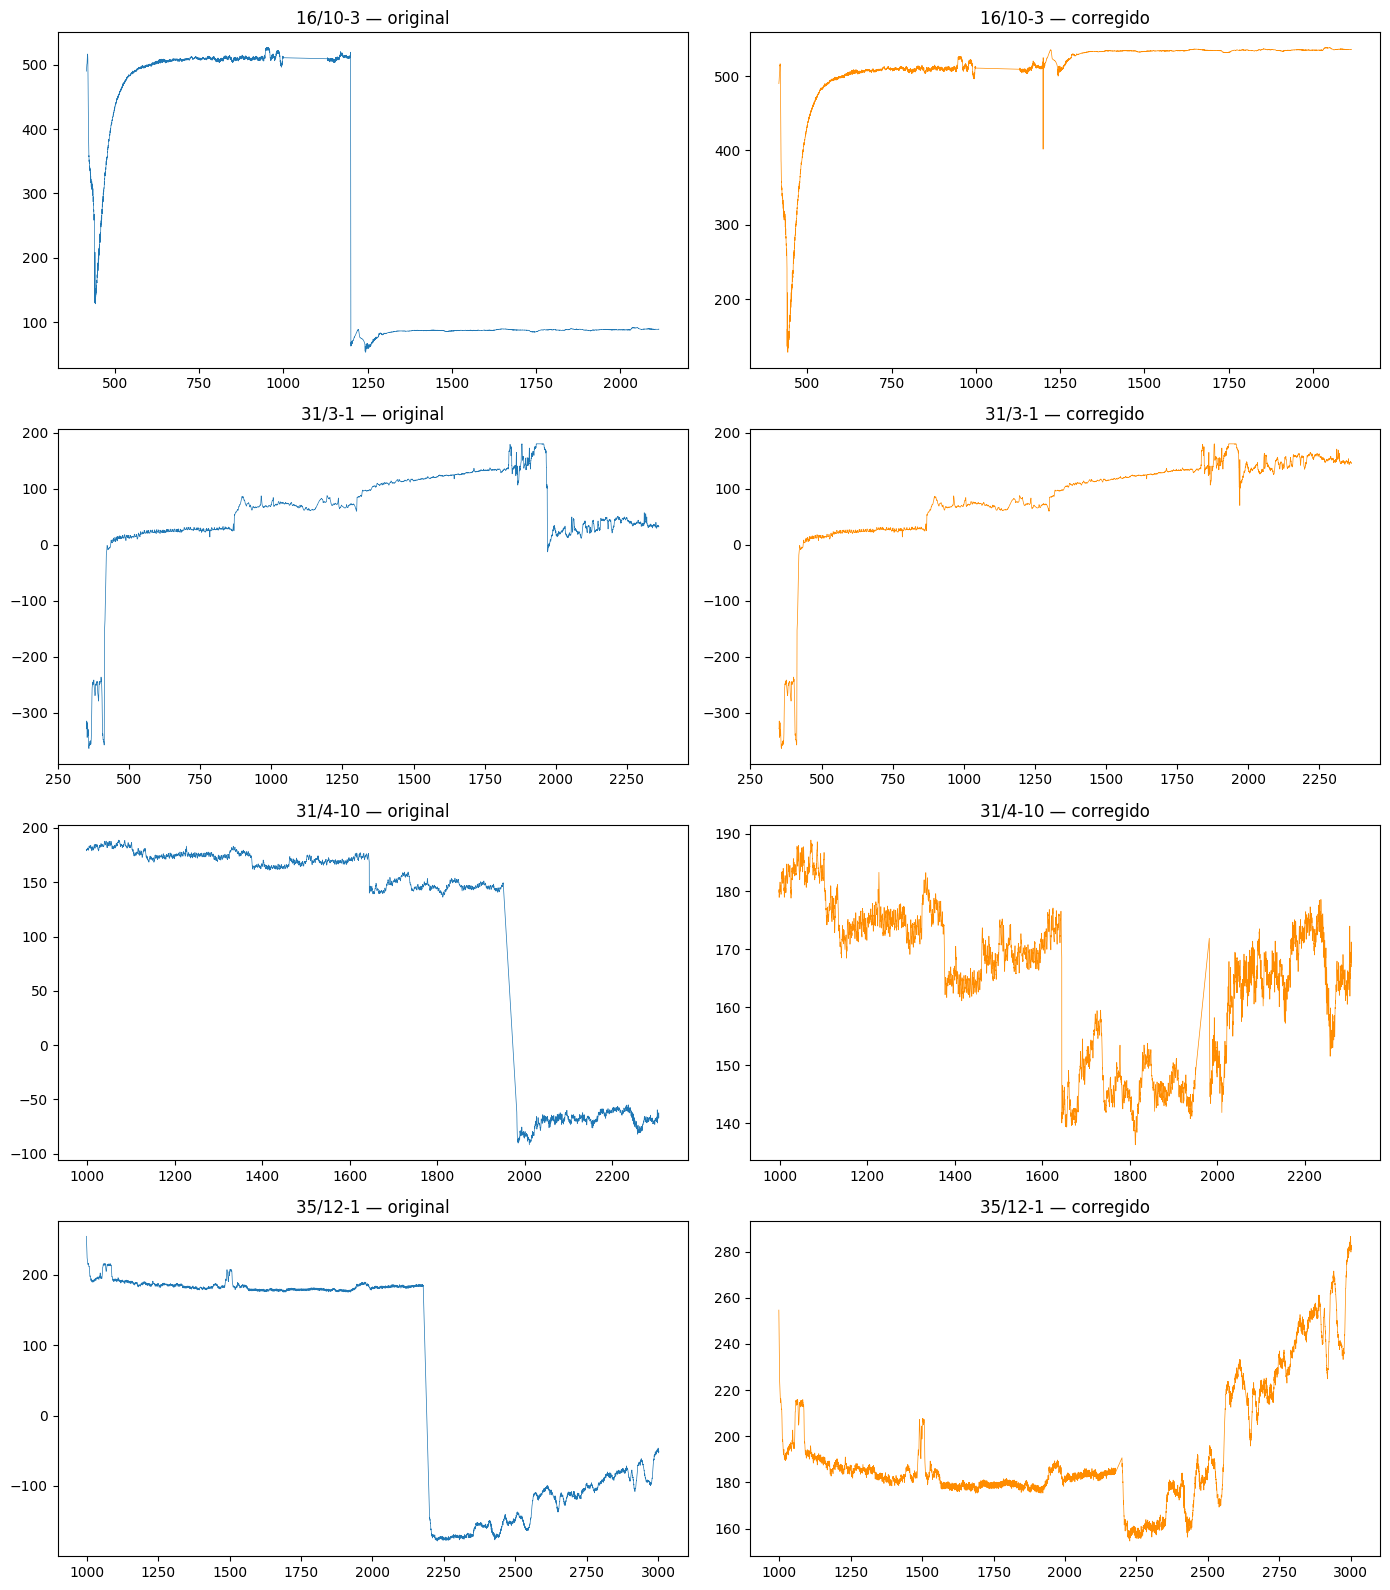

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
for row, well in enumerate(sp_jump_events):
    wdf = pool_sorted[(pool_sorted["WELL"] == well) & pool_sorted["SP"].notna()].sort_values("DEPTH_MD")
    axes[row, 0].plot(wdf["DEPTH_MD"], wdf["SP"], linewidth=0.5)
    axes[row, 0].set_title(f"{well} — original")
    axes[row, 1].plot(wdf["DEPTH_MD"], wdf["SP_corrected"], linewidth=0.5, color="darkorange")
    axes[row, 1].set_title(f"{well} — corregido")
plt.tight_layout()
plt.show()

In [ ]:
grp = pool_sorted.groupby("WELL")["SP_corrected"]
sp_median = grp.transform("median")
sp_mad = grp.transform(lambda s: (s - s.median()).abs().median())

pool_sorted["SP_scaled"] = (pool_sorted["SP_corrected"] - sp_median) / (1.4826 * sp_mad)

print("valores no finitos:", (~np.isfinite(pool_sorted["SP_scaled"])).sum())
print(pool_sorted.loc[~np.isfinite(pool_sorted["SP_scaled"]), "WELL"].value_counts())

valores no finitos: 456898
WELL
25/4-5      23005
35/4-1      20823
35/11-12    19112
34/3-3 A    18190
34/5-1 A    14592
            ...  
34/8-1         80
31/3-2         73
25/6-1         17
26/4-1         16
34/7-20         6
Name: count, Length: 77, dtype: int64


In [ ]:
mask_has_sp = pool_sorted["SP"].notna()
non_finite = mask_has_sp & ~np.isfinite(pool_sorted["SP_scaled"])
print("filas con SP real pero SP_scaled no finito:", non_finite.sum())
print(pool_sorted.loc[non_finite, "WELL"].value_counts())

filas con SP real pero SP_scaled no finito: 0
Series([], Name: count, dtype: int64)


In [ ]:
pool_sorted.loc[pool_sorted["WELL"] == "25/6-3", "SP_scaled"] = np.nan

print(pool_sorted.loc[pool_sorted["SP"].notna(), "SP_scaled"].describe())

count    972796.000000
mean         -0.029232
std           2.118761
min         -62.696127
25%          -0.662425
50%           0.000000
75%           0.684980
max          28.739283
Name: SP_scaled, dtype: float64


In [ ]:
extremos = pool_sorted.loc[pool_sorted["SP"].notna()].nsmallest(10, "SP_scaled")[["WELL", "DEPTH_MD", "SP", "SP_scaled"]]
print(extremos.to_string(index=False))

extremos_alto = pool_sorted.loc[pool_sorted["SP"].notna()].nlargest(10, "SP_scaled")[["WELL", "DEPTH_MD", "SP", "SP_scaled"]]
print(extremos_alto.to_string(index=False))

   WELL   DEPTH_MD         SP  SP_scaled
16/10-3 441.861599 128.802811 -62.696127
16/10-3 441.709599 129.147934 -62.642428
16/10-3 441.253599 130.019012 -62.506893
16/10-3 440.493599 131.110428 -62.337075
16/10-3 442.013599 132.842728 -62.067539
16/10-3 441.405599 133.956787 -61.894197
16/10-3 441.101599 134.239944 -61.850140
16/10-3 442.469599 134.246109 -61.849180
16/10-3 441.557599 136.587036 -61.484945
16/10-3 439.733599 136.715866 -61.464900
   WELL   DEPTH_MD         SP  SP_scaled
17/11-1 164.873016 162.666061  28.739283
17/11-1 165.481016 162.368362  28.672224
17/11-1 165.025016 162.194504  28.633062
17/11-1 164.721016 161.850311  28.555531
17/11-1 165.329016 161.786346  28.541122
17/11-1 165.633016 161.494278  28.475332
17/11-1 165.177016 161.359879  28.445058
17/11-1 164.569016 160.613876  28.277017
17/11-1 164.417016 159.354950  27.993438
17/11-1 163.657016 158.909515  27.893101


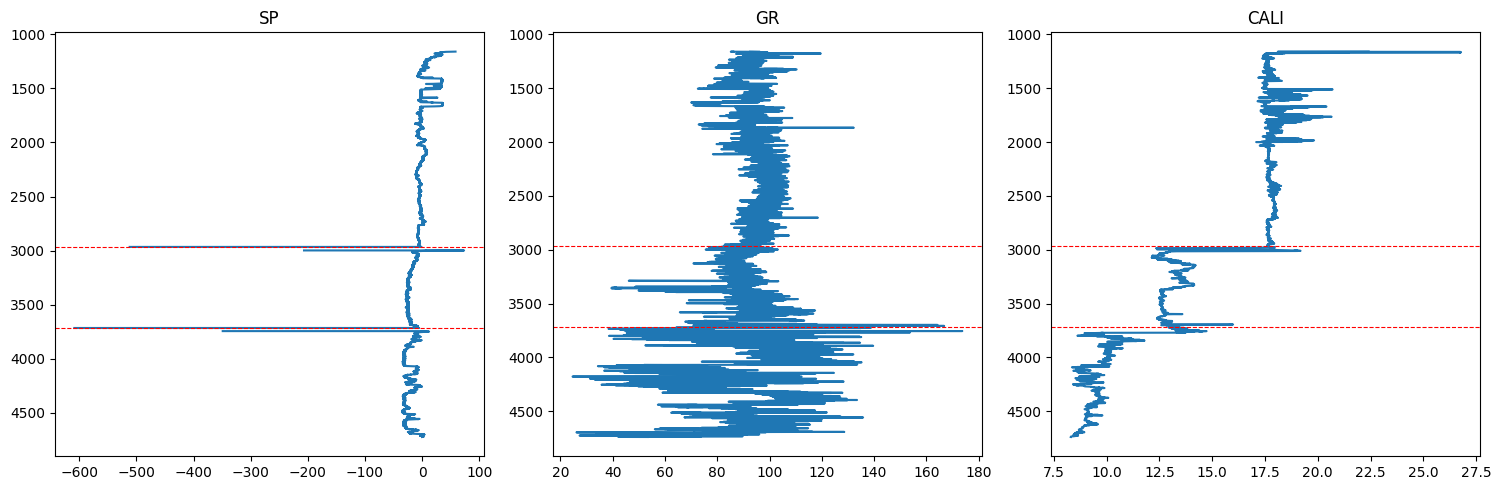

           DEPTH_MD            SP
count  23310.000000  22806.000000
mean    2942.191360     -9.532413
std     1033.814167     16.320477
min     1160.304000   -608.786804
25%     2046.046000    -23.111111
50%     2939.236000     -7.241776
75%     3826.042000     -2.086049
max     4738.992000     73.652649


In [ ]:
w = pool_sorted[pool_sorted["WELL"] == "34/11-2 S"].sort_values("DEPTH_MD")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col in zip(axes, ["SP", "GR", "CALI"]):
    if col in w.columns and w[col].notna().any():
        ax.plot(w[col], w["DEPTH_MD"])
        ax.invert_yaxis()
        ax.set_title(col)
    else:
        ax.set_title(f"{col} (sin datos)")

for d in [2966.064, 3715.576]:
    for ax in axes:
        ax.axhline(d, color="red", linestyle="--", linewidth=0.8)

plt.tight_layout()
plt.show()

print(w[["DEPTH_MD", "SP"]].describe())

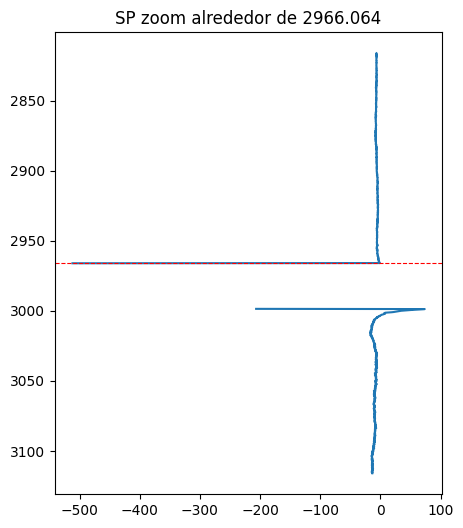

--- 2966.064 ---
 DEPTH_MD          SP
 2816.192   -6.592026
 2816.344   -6.130933
 2816.496   -5.881821
 2816.648   -6.497102
 2816.800   -6.581836
 2816.952   -6.400462
 2817.104   -6.237368
 2817.256   -6.601645
 2817.408   -7.021153
 2817.560   -6.644536
 2817.712   -6.206135
 2817.864   -6.407898
 2818.016   -6.952335
 2818.168   -6.535872
 2818.320   -6.299225
 2818.472   -6.400919
 2818.624   -6.942806
 2818.776   -6.625306
 2818.928   -6.426172
 2819.080   -6.546875
 2819.232   -6.563890
 2819.384   -6.203422
 2819.536   -6.330969
 2819.688   -6.504953
 2819.840   -6.690234
 2819.992   -6.639375
 2820.144   -6.536638
 2820.296   -6.628161
 2820.448   -6.780432
 2820.600   -6.662594
 2820.752   -6.573476
 2820.904   -6.674695
 2821.056   -6.604900
 2821.208   -6.716006
 2821.360   -6.965166
 2821.512   -6.560521
 2821.664   -6.573349
 2821.816   -6.640855
 2821.968   -6.711610
 2822.120   -6.484985
 2822.272   -6.330587
 2822.424   -6.457280
 2822.576   -6.288136
 2822.728   -6.

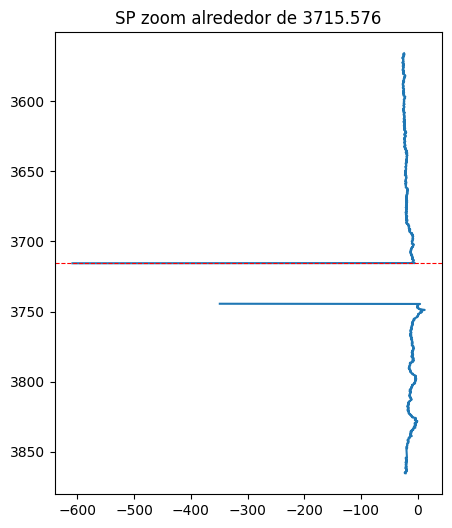

--- 3715.576 ---
 DEPTH_MD          SP
 3565.704  -24.117449
 3565.856  -24.807787
 3566.008  -25.053995
 3566.160  -25.544609
 3566.312  -24.086937
 3566.464  -23.394749
 3566.616  -24.552893
 3566.768  -24.884052
 3566.920  -24.179026
 3567.072  -23.714931
 3567.224  -24.884825
 3567.376  -25.130262
 3567.528  -25.597025
 3567.680  -25.437241
 3567.832  -24.620453
 3567.984  -24.447058
 3568.136  -26.052113
 3568.288  -25.522390
 3568.440  -25.483673
 3568.592  -25.599003
 3568.744  -27.044361
 3568.896  -25.492563
 3569.048  -25.484581
 3569.200  -25.697021
 3569.352  -26.945070
 3569.504  -25.672606
 3569.656  -26.054829
 3569.808  -25.554070
 3569.960  -25.312706
 3570.112  -25.589802
 3570.264  -25.475554
 3570.416  -25.921463
 3570.568  -25.692354
 3570.720  -25.766436
 3570.872  -25.985073
 3571.024  -25.373652
 3571.176  -25.293827
 3571.328  -25.127455
 3571.480  -25.438038
 3571.632  -25.697884
 3571.784  -25.306915
 3571.936  -25.325050
 3572.088  -26.735706
 3572.240  -26.

In [ ]:
for depth_center in [2966.064, 3715.576]:
    lo, hi = depth_center - 150, depth_center + 150
    seg = w[(w["DEPTH_MD"] >= lo) & (w["DEPTH_MD"] <= hi)]

    fig, ax = plt.subplots(figsize=(5, 6))
    ax.plot(seg["SP"], seg["DEPTH_MD"])
    ax.invert_yaxis()
    ax.axhline(depth_center, color="red", linestyle="--", linewidth=0.8)
    ax.set_title(f"SP zoom alrededor de {depth_center}")
    plt.show()

    print(f"--- {depth_center} ---")
    print(seg[["DEPTH_MD", "SP"]].to_string(index=False))

In [ ]:
def edge_anomalies(df, curve="SP"):
    rows = []
    for well, g in df.groupby("WELL"):
        s = g.sort_values("DEPTH_MD")[curve].reset_index(drop=True)
        depth = g.sort_values("DEPTH_MD")["DEPTH_MD"].reset_index(drop=True)
        isnan = s.isna()
        starts = isnan & ~isnan.shift(1, fill_value=False)
        for i in s.index[starts]:
            if i > 0 and pd.notna(s[i-1]):
                rows.append((well, depth[i-1], "before", s[i-1]))
        ends = isnan & ~isnan.shift(-1, fill_value=False)
        for i in s.index[ends]:
            j = i + 1
            if j < len(s) and pd.notna(s[j]):
                rows.append((well, depth[j], "after", s[j]))
    return pd.DataFrame(rows, columns=["WELL", "DEPTH_MD", "side", curve])

edges = edge_anomalies(pool_sorted, "SP")
print(edges.reindex(edges.SP.abs().sort_values(ascending=False).index).head(20))

         WELL     DEPTH_MD    side          SP
54  34/11-2 S  3715.576000  before -608.786804
53  34/11-2 S  2966.064000  before -511.877502
2     16/10-3   999.853599  before  510.763763
4     16/10-3  1130.117599   after  509.110596
19   25/8-5 S  2279.958400  before -400.000000
20   25/8-5 S  2290.750400  before -400.000000
21   25/8-5 S  2288.622400   after -400.000000
57  34/11-2 S  3744.456000   after -348.966492
56  34/11-2 S  2998.592000   after -206.594635
34  31/2-19 S  3096.190400   after -202.158951
32  31/2-19 S  3460.990400  before -198.917816
40     31/3-2  1490.856901  before  196.767883
35  31/2-19 S  3465.550400   after -192.637802
74    35/12-1  2177.486815  before  184.500000
51   34/10-35  4303.967000  before  184.490402
39     31/3-1  1949.685000   after  179.985031
38     31/3-1  1932.357000  before  179.983566
31  31/2-19 S  3035.846400  before  164.778381
33  31/2-19 S  4059.870400  before  164.015747
23     25/8-7  2343.815115  before  159.855072


In [ ]:
for well, center in [("35/12-1", 2200.590815), ("31/4-10", 1982.956393)]:
    w2 = pool_sorted[pool_sorted["WELL"] == well].sort_values("DEPTH_MD")
    seg = w2[(w2["DEPTH_MD"] >= center - 60) & (w2["DEPTH_MD"] <= center + 30)]
    print(f"--- {well} (pivote usado: {center}) ---")
    print(seg[["DEPTH_MD", "SP"]].to_string(index=False))
    print()

--- 35/12-1 (pivote usado: 2200.590815) ---
   DEPTH_MD          SP
2140.702815  184.012909
2140.854815  183.415878
2141.006815  182.730469
2141.158815  182.941818
2141.310815  182.970825
2141.462815  183.246750
2141.614815  184.271744
2141.766815  183.921494
2141.918815  183.571701
2142.070815  183.602295
2142.222815  183.817245
2142.374815  184.458542
2142.526815  185.070206
2142.678815  184.877777
2142.830815  184.925842
2142.982815  184.555252
2143.134815  184.280029
2143.286815  183.831192
2143.438815  183.531143
2143.590815  183.546494
2143.742815  183.260666
2143.894815  183.409241
2144.046815  184.182129
2144.198815  183.616318
2144.350815  182.779251
2144.502815  182.073273
2144.654815  181.717651
2144.806815  182.500748
2144.958815  183.198868
2145.110815  184.231644
2145.262815  184.333267
2145.414815  183.867355
2145.566815  183.985031
2145.718815  184.341171
2145.870815  184.584351
2146.022815  184.962967
2146.174815  184.899155
2146.326815  185.120605
2146.478815  184.770

In [ ]:
def classify_gaps(df, curve="SP"):
    rows = []
    for well, g in df.groupby("WELL"):
        s = g.sort_values("DEPTH_MD")[curve].reset_index(drop=True)
        depth = g.sort_values("DEPTH_MD")["DEPTH_MD"].reset_index(drop=True)
        isnan = s.isna()
        run_starts = s.index[isnan & ~isnan.shift(1, fill_value=False)]
        run_ends = s.index[isnan & ~isnan.shift(-1, fill_value=False)]
        for start, end in zip(run_starts, run_ends):
            if start == 0 or end == len(s) - 1:
                continue
            pre_edge = s[start - 1]
            post_edge = s[end + 1]
            pre_window = s.iloc[max(0, start - 31):start - 1]
            post_window = s.iloc[end + 11:end + 41]
            pre_base = pre_window.median()
            post_base = post_window.median()
            rows.append({
                "WELL": well, "gap_start_depth": depth[start], "gap_end_depth": depth[end],
                "gap_len_m": depth[end] - depth[start],
                "pre_edge": pre_edge, "pre_base": pre_base,
                "post_edge": post_edge, "post_base": post_base,
                "baseline_shift": post_base - pre_base,
                "pre_edge_dev": pre_edge - pre_base,
            })
    return pd.DataFrame(rows)

gaps = classify_gaps(pool_sorted, "SP")
gaps["clasificacion"] = np.where(gaps["baseline_shift"].abs() > 30, "posible_salto_real", "artefacto_transitorio")
print(gaps.reindex(gaps.baseline_shift.abs().sort_values(ascending=False).index).to_string(index=False))

     WELL  gap_start_depth  gap_end_depth  gap_len_m    pre_edge    pre_base   post_edge   post_base  baseline_shift  pre_edge_dev         clasificacion
31/2-19 S      3035.998400    3061.990400     25.992  164.778381  163.928474 -202.158951 -214.049294     -377.977768      0.849907    posible_salto_real
  35/12-1      2177.638815    2199.374815     21.736  184.500000  184.522461 -142.114853 -156.095238     -340.617699     -0.022461    posible_salto_real
  31/4-10      1951.188393    1981.892393     30.704  149.094467  146.889175  -61.735676  -87.135860     -234.025036      2.205292    posible_salto_real
 34/10-35      1053.903000    1066.367000     12.464  -14.800000  -14.800000  -14.800000   47.379616       62.179616      0.000000    posible_salto_real
 25/8-5 S      2280.110400    2288.470400      8.360 -400.000000 -339.737793 -400.000000 -400.000000      -60.262207    -60.262207    posible_salto_real
  34/7-21      1782.150000    1802.366000     20.216    0.000000   52.632217    0.

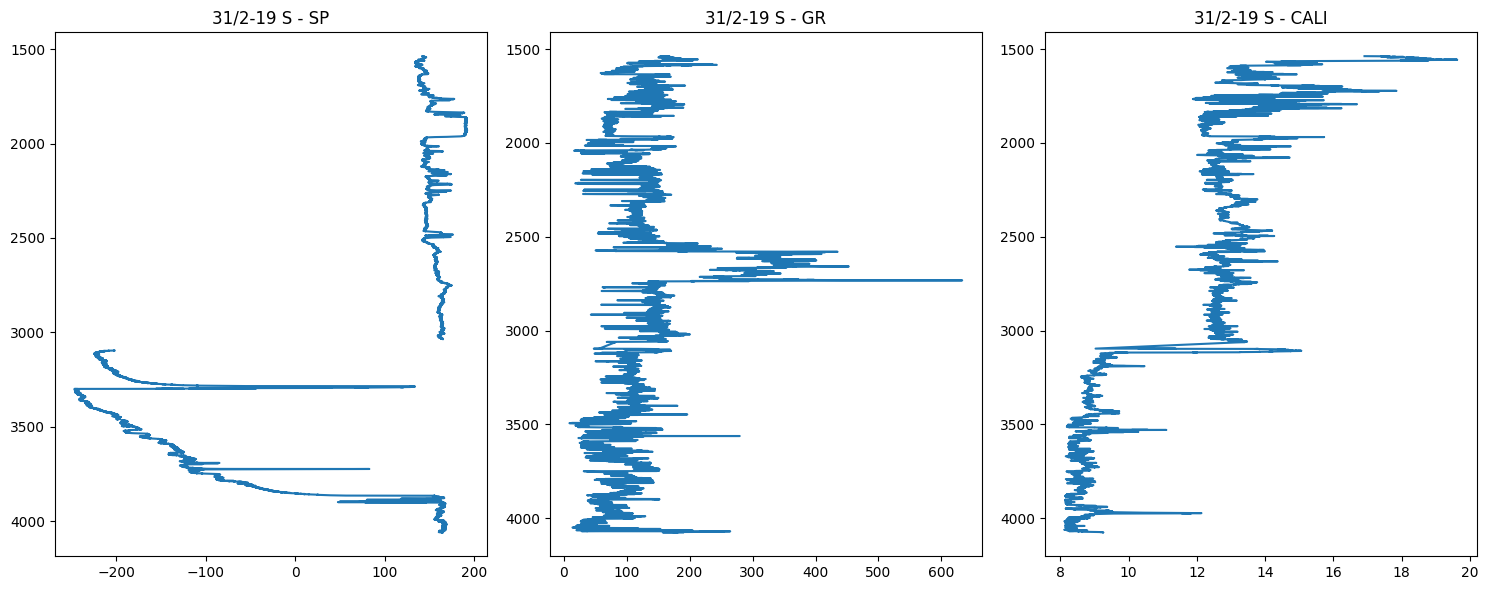

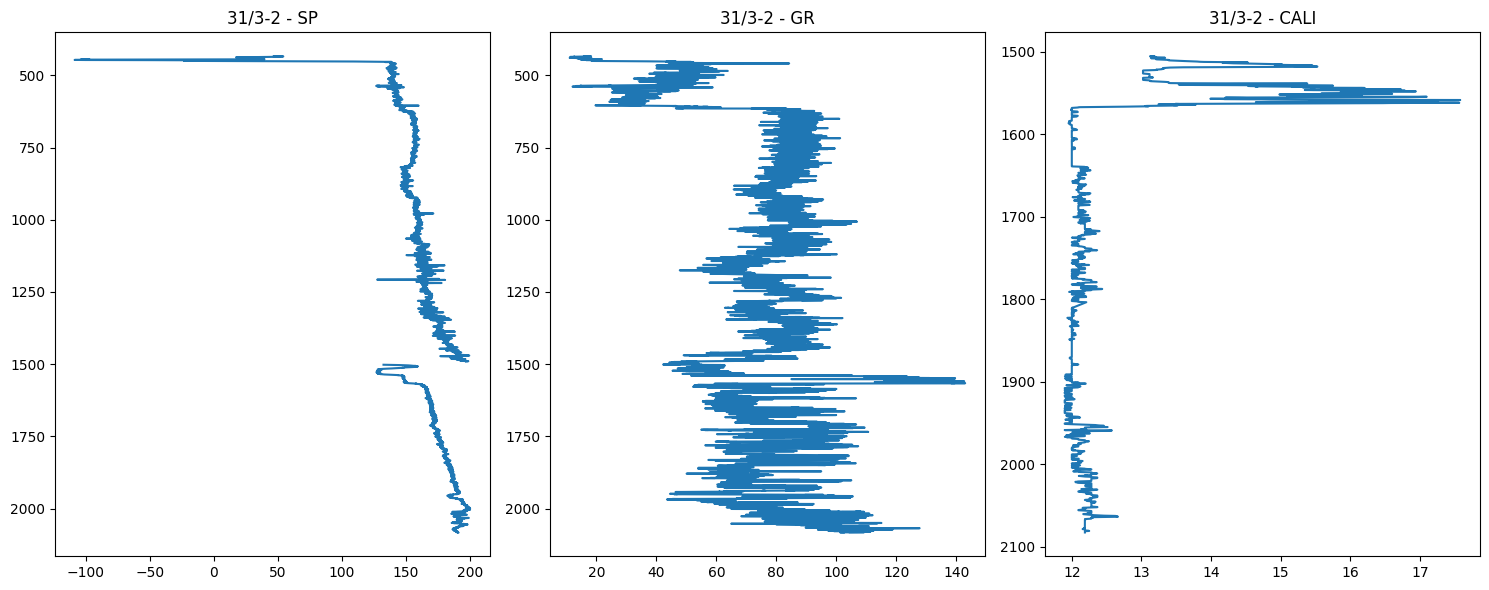

In [ ]:
for well in ["31/2-19 S", "31/3-2"]:
    w = pool_sorted[pool_sorted["WELL"] == well].sort_values("DEPTH_MD")
    fig, axes = plt.subplots(1, 3, figsize=(15, 6))
    for ax, col in zip(axes, ["SP", "GR", "CALI"]):
        if col in w.columns and w[col].notna().any():
            ax.plot(w[col], w["DEPTH_MD"])
            ax.invert_yaxis()
            ax.set_title(f"{well} - {col}")
        else:
            ax.set_title(f"{col} (sin datos)")
    plt.tight_layout()
    plt.show()

In [ ]:
final_columns = [
    "SP_corrected", "SP_scaled", "SGR_scaled",
    "RSHA_log10", "RMED_log10", "RDEP_log10", "RMIC_log10", "RXO_log10",
    "PEF_log10", "ROP_log10", "ROPA_log10",
    "ROP_log10_scaled", "ROPA_log10_scaled",
    "MUDWEIGHT_scaled", "DTS_scaled",
]

for col in final_columns:
    n_inf = np.isinf(pool_sorted[col]).sum()
    print(col, "inf:", n_inf)

SP_corrected inf: 0
SP_scaled inf: 0
SGR_scaled inf: 0
RSHA_log10 inf: 0
RMED_log10 inf: 0
RDEP_log10 inf: 0
RMIC_log10 inf: 0
RXO_log10 inf: 0
PEF_log10 inf: 0
ROP_log10 inf: 0
ROPA_log10 inf: 0
ROP_log10_scaled inf: 0
ROPA_log10_scaled inf: 0
MUDWEIGHT_scaled inf: 0
DTS_scaled inf: 0


In [ ]:
# Cierre de Etapa 2: status por sub-tramo sobre pool_sorted final y verificacion de rachas congeladas

status = build_status(pool_sorted, "depth_segment")
print(pd.DataFrame({c: status[c].value_counts() for c in curves}).T)
print(all((status[c] == "dato_real").sum() == pool_sorted[c].notna().sum() for c in curves))
print(sum((identical_runs(pool_sorted, c)["n"] >= 20).sum() for c in frozen_curves))
print((status == "interior_pendiente_Gmax").sum().sum())

           dato_real  borde_no_imputable  interior_pendiente_Gmax
CALI         1331850               91924                     5920
BS            824110              605266                      318
DCAL          355442             1072240                     2012
RHOB         1240889              175908                    12897
DRHO         1198016              219671                    12007
GR           1428787                 907                        0
SGR            70377             1356103                     3214
NPHI          965447              450569                    13678
PEF           884837              522020                    22837
DTC          1342950               78016                     8728
DTS           290703             1123665                    15326
SP            972796              437704                    19194
ROP           688552              730559                    10583
RSHA          693029              708119                    28546
RMED      

### Productos persistentes de las Etapas 1 y 2

Dataset consolidado (`pool`, tal como se reunió en la sección 1.3) y dataset curado final (`pool_sorted`), guardados en Drive en formato parquet, con un manifiesto que registra filas, columnas, huella sha256 de cada archivo y huella git de los archivos fuente. Son el punto de partida de la Etapa 4.

In [ ]:
import hashlib, json, datetime

def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def same_frame(a, b):
    if list(a.columns) != list(b.columns) or len(a) != len(b):
        return False
    for c in a.columns:
        x, y = a[c].reset_index(drop=True), b[c].reset_index(drop=True)
        # parquet devuelve None donde habia NaN en columnas de texto: se comparan nulos y valores por separado
        if not x.isna().equals(y.isna()) or not x.dropna().equals(y.dropna()):
            return False
    return True

datasets = {"etapa1_pool_consolidado.parquet": pool, "etapa2_pool_curado.parquet": pool_sorted}

# se conserva lo que ya tenga el manifiesto (particion y prueba de la Etapa 4)
manifest_path = f"{DATA_DIR}/manifiesto_datos.json"
manifest = {}
if os.path.exists(manifest_path):
    with open(manifest_path) as f:
        manifest = json.load(f)
manifest.update({"fecha": datetime.date.today().isoformat(),
                 "fuente": "github.com/bolgebrygg/Force-2020-Machine-Learning-competition/lithology_competition/data",
                 "fuente_git_sha1": {n: items[n]["sha"] for n in wanted}})
manifest.setdefault("archivos", {})

for name, df in datasets.items():
    path = f"{DATA_DIR}/{name}"
    # solo se reescribe si los datos cambiaron: reescribir datos iguales puede cambiar la huella
    if not (os.path.exists(path) and same_frame(pd.read_parquet(path), df)):
        df.to_parquet(path, index=False)
    manifest["archivos"][name] = {"filas": len(df), "columnas": df.shape[1], "pozos": int(df["WELL"].nunique()),
                                  "mb": round(os.path.getsize(path) / 1e6, 1), "sha256": file_sha256(path),
                                  "igual_al_releer": same_frame(pd.read_parquet(path), df)}

with open(manifest_path, "w") as f:
    json.dump(manifest, f, indent=2, ensure_ascii=False)

print(json.dumps(manifest["archivos"], indent=2))
print(list(pool_sorted.columns))


{
  "etapa1_pool_consolidado.parquet": {
    "filas": 1429694,
    "columnas": 30,
    "pozos": 118,
    "mb": 138.6,
    "sha256": "bbb4ea2e4f61fe22877e1092a3a9c40dcc92b52a3c5f6bf762be585e570908bb",
    "igual_al_releer": true
  },
  "etapa2_pool_curado.parquet": {
    "filas": 1429694,
    "columnas": 47,
    "pozos": 118,
    "mb": 216.6,
    "sha256": "82f590e8ba367d1a5d70de55835c86c0ebece911bdbf61eec7bd47eb6232b2fd",
    "igual_al_releer": true
  }
}
['WELL', 'DEPTH_MD', 'X_LOC', 'Y_LOC', 'Z_LOC', 'GROUP', 'FORMATION', 'CALI', 'RSHA', 'RMED', 'RDEP', 'RHOB', 'GR', 'SGR', 'NPHI', 'PEF', 'DTC', 'SP', 'BS', 'ROP', 'DTS', 'DCAL', 'DRHO', 'MUDWEIGHT', 'RMIC', 'ROPA', 'RXO', 'FORCE_2020_LITHOFACIES_LITHOLOGY', 'FORCE_2020_LITHOFACIES_CONFIDENCE', 'source', 'pef_posible_contaminacion', 'depth_segment', 'RSHA_log10', 'RMED_log10', 'RDEP_log10', 'RMIC_log10', 'RXO_log10', 'SGR_scaled', 'PEF_log10', 'ROP_log10', 'ROPA_log10', 'ROP_log10_scaled', 'ROPA_log10_scaled', 'MUDWEIGHT_scaled', 'DTS

# 3. Etapa 3 - Análisis exploratorio de las secuencias

## 3.1 OE1 - Ejecutar el análisis univariado de cada curva (estacionariedad, ACF, PACF y contenido espectral), agregado sobre todos los pozos.

In [ ]:
def valid_runs(df, curve):
    ok = df[curve].notna().to_numpy()
    seg = df["depth_segment"].to_numpy()
    starts_run = ok & (np.r_[True, ~ok[:-1]] | np.r_[True, seg[1:] != seg[:-1]])
    run_id = np.cumsum(starts_run)
    return (df[ok].assign(run=run_id[ok], pos=np.flatnonzero(ok)).groupby("run")
            .agg(well=("WELL", "first"), segment=("depth_segment", "first"),
                 top=("DEPTH_MD", "min"), base=("DEPTH_MD", "max"),
                 start=("pos", "min"), n=("DEPTH_MD", "size")))

def pooled_acf(df, curve, min_len, max_lag):
    x = df[curve].to_numpy()
    mu = df.groupby("WELL")[curve].mean()
    runs = valid_runs(df, curve)
    runs = runs[runs["n"] >= min_len]
    prod = np.zeros(max_lag + 1)
    pairs = np.zeros(max_lag + 1)
    for r in runs.itertuples():
        d = x[r.start:r.start + r.n] - mu[r.well]
        for h in range(max_lag + 1):
            prod[h] += d[h:] @ d[:r.n - h]
            pairs[h] += r.n - h
    out = pd.DataFrame({"lag": np.arange(max_lag + 1), "meters": np.arange(max_lag + 1) * 0.152,
                        "pairs": pairs.astype(int)})
    out["rho_pairs"] = (prod / pairs) / (prod[0] / pairs[0])
    out["rho_n"] = prod / prod[0]
    return out, runs

acf_a, runs_a = pooled_acf(pool_sorted, "GR", min_len=500, max_lag=125)
acf_b, runs_b = pooled_acf(pool_sorted, "GR", min_len=2000, max_lag=500)

for acf, runs, max_lag in [(acf_a, runs_a, 125), (acf_b, runs_b, 500)]:
    print(len(runs), runs["well"].nunique(), runs["n"].sum(), acf["pairs"].iloc[-1] == (runs["n"] - max_lag).sum())

print(acf_a.iloc[[0, 1, 5, 25, 50, 125]].round(3).to_string(index=False))
print(acf_b.iloc[[0, 1, 5, 25, 125, 250, 500]].round(3).to_string(index=False))

230 118 1418075 True
171 113 1351757 True
 lag  meters   pairs  rho_pairs  rho_n
   0   0.000 1418075      1.000  1.000
   1   0.152 1417845      0.991  0.990
   5   0.760 1416925      0.917  0.916
  25   3.800 1412325      0.798  0.795
  50   7.600 1406575      0.732  0.726
 125  19.000 1389325      0.623  0.611
 lag  meters   pairs  rho_pairs  rho_n
   0   0.000 1351757      1.000  1.000
   1   0.152 1351586      0.991  0.990
   5   0.760 1350902      0.919  0.918
  25   3.800 1347482      0.807  0.804
 125  19.000 1330382      0.635  0.625
 250  38.000 1309007      0.522  0.506
 500  76.000 1266257      0.374  0.351


In [ ]:
per_well = {}
for well, g in pool_sorted.groupby("WELL"):
    if (valid_runs(g, "GR")["n"] >= 2000).any():
        per_well[well], _ = pooled_acf(g, "GR", 2000, 500)

lags = [1, 25, 125, 250, 500]
table = pd.DataFrame({w: a.set_index("lag").loc[lags, "rho_pairs"] for w, a in per_well.items()}).T
rows = pd.Series({w: a["pairs"].iloc[0] for w, a in per_well.items()})

q = [0.1, 0.25, 0.5, 0.75, 0.9]
print(len(table), (rows >= 10000).sum())
print(table.quantile(q).round(3))
print(table[rows >= 10000].quantile(q).round(3))
print(acf_b.set_index("lag").loc[lags, "rho_pairs"].round(3).to_frame().T)
print((rows.nlargest(5) / rows.sum()).round(3))

113 70
lag     1      25     125    250    500
0.10  0.979  0.616  0.299  0.150 -0.027
0.25  0.986  0.702  0.397  0.304  0.118
0.50  0.991  0.791  0.587  0.452  0.321
0.75  0.994  0.860  0.721  0.608  0.519
0.90  0.997  0.915  0.801  0.698  0.620
lag     1      25     125    250    500
0.10  0.978  0.635  0.375  0.290  0.123
0.25  0.983  0.732  0.536  0.431  0.281
0.50  0.991  0.821  0.653  0.540  0.430
0.75  0.994  0.876  0.742  0.670  0.542
0.90  0.997  0.916  0.810  0.739  0.646
lag          1      25     125    250    500
rho_pairs  0.991  0.807  0.635  0.522  0.374
25/2-7        0.019
29/3-1        0.018
25/7-2        0.018
34/10-16 R    0.017
35/11-6       0.017
dtype: float64


In [ ]:
from statsmodels.tsa.stattools import adfuller

def adf_runs(df, curve, min_len, lag_rule="tseries"):
    x = df[curve].to_numpy()
    runs = valid_runs(df, curve)
    runs = runs[runs["n"] >= min_len]
    rows = []
    for r in runs.itertuples():
        if lag_rule == "tseries":
            k = int((r.n - 1) ** (1 / 3))
        else:
            k = int(12 * (r.n / 100) ** 0.25)
        stat, pval, crit, store = adfuller(x[r.start:r.start + r.n], maxlag=k, regression="ct",
                                           autolag=None, regresults=True, result_object=False)
        rows.append((r.well, r.n, k, stat, pval, store.resols.params[0]))
    return pd.DataFrame(rows, columns=["well", "n", "k", "stat", "pvalue", "gamma"])

bins = [2000, 5000, 10000, 30000]
summary = {}
for rule in ["tseries", "schwert"]:
    res = adf_runs(pool_sorted, "GR", 2000, rule)
    res["reject"] = res["pvalue"] < 0.05
    res["n_bin"] = pd.cut(res["n"], bins, right=False)
    summary[rule] = res.groupby("n_bin", observed=True).agg(
        k_median=("k", "median"), reject=("reject", "mean"), median_stat=("stat", "median"))
    print(rule, len(res), round(res["reject"].mean(), 3))

print(pd.concat(summary, axis=1).round(3))

tseries 171 0.918
schwert 171 0.836
                tseries                     schwert                   
               k_median reject median_stat k_median reject median_stat
n_bin                                                                 
[2000, 5000)       14.0  0.868      -4.687     27.0  0.691      -3.918
[5000, 10000)      19.0  0.909      -6.604     34.0  0.873      -5.478
[10000, 30000)     24.0  1.000      -6.753     41.0  1.000      -5.784


In [ ]:
def durbin_levinson(rho):
    max_lag = len(rho) - 1
    pacf = np.ones(max_lag + 1)
    phi = np.zeros(max_lag + 1)
    for n in range(1, max_lag + 1):
        phi_nn = (rho[n] - phi[1:n] @ rho[n - 1:0:-1]) / (1 - phi[1:n] @ rho[1:n])
        phi[1:n] = phi[1:n] - phi_nn * phi[n - 1:0:-1]
        phi[n] = phi_nn
        pacf[n] = phi_nn
    return pacf

acf_b["pacf"] = durbin_levinson(acf_b["rho_n"].to_numpy())

print(acf_b.iloc[[1, 2, 3, 4, 5, 6, 8, 10, 15, 25, 50, 125, 250, 500]][["lag", "meters", "rho_n", "pacf"]]
      .round(3).to_string(index=False))
print(acf_b["pacf"].iloc[1:].abs().max() < 1)

 lag  meters  rho_n   pacf
   1   0.152  0.990  0.990
   2   0.304  0.971 -0.525
   3   0.456  0.950  0.231
   4   0.608  0.932  0.166
   5   0.760  0.918 -0.052
   6   0.912  0.907  0.069
   8   1.216  0.889  0.021
  10   1.520  0.875  0.036
  15   2.280  0.847  0.012
  25   3.800  0.804  0.013
  50   7.600  0.740  0.004
 125  19.000  0.625  0.002
 250  38.000  0.506  0.001
 500  76.000  0.351  0.001
True


In [ ]:
p = acf_b["pacf"].to_numpy()
tail = pd.DataFrame({"lag": acf_b["lag"], "h_pacf": acf_b["lag"] * p, "pos": p > 0}).iloc[8:]
tail["band"] = pd.cut(tail["lag"], [8, 15, 30, 60, 125, 250, 501], right=False)
print(tail.groupby("band", observed=True).agg(h_pacf=("h_pacf", "median"), pos=("pos", "mean")).round(3))

            h_pacf    pos
band                     
[8, 15)      0.262  1.000
[15, 30)     0.279  1.000
[30, 60)     0.274  1.000
[60, 125)    0.237  0.892
[125, 250)   0.159  0.704
[250, 501)   0.024  0.542


In [ ]:
from scipy.signal import detrend

def pooled_spectrum(df, curve, seg_len):
    x = df[curve].to_numpy()
    runs = valid_runs(df, curve)
    taper = np.hanning(seg_len)
    power = np.zeros(seg_len // 2 + 1)
    n_seg, wells = 0, set()
    for r in runs.itertuples():
        for s in range(r.n // seg_len):
            seg = x[r.start + s * seg_len:r.start + (s + 1) * seg_len]
            power += np.abs(np.fft.rfft(detrend(seg) * taper)) ** 2 / (taper ** 2).sum()
            n_seg += 1
            wells.add(r.well)
    k = np.arange(1, seg_len // 2 + 1)
    spec = pd.DataFrame({"k": k, "freq": k / seg_len, "wavelength_m": seg_len * 0.152 / k,
                         "power": power[1:] / n_seg})
    return spec, n_seg, len(wells)

def band_summary(spec, edges):
    spec = spec.assign(band=pd.cut(spec["wavelength_m"], edges))
    total = spec["power"].sum()
    rows = []
    for band, g in spec.groupby("band", observed=True):
        fit = g[g["k"] >= 3]
        d = np.nan
        if len(fit) >= 5:
            d = -np.polyfit(np.log(4 * np.sin(np.pi * fit["freq"]) ** 2), np.log(fit["power"]), 1)[0]
        rows.append((band, len(g), g["power"].sum() / total, d))
    return pd.DataFrame(rows, columns=["band_m", "n_freq", "var_share", "d_local"])

# 305 y 1220 dejan margen para que 304 m y 1216 m caigan dentro de su banda
band_edges = [0.3, 1.2, 4.6, 19, 76, 305, 1220]

spec_a, nseg_a, nw_a = pooled_spectrum(pool_sorted, "GR", 2000)
spec_b, nseg_b, nw_b = pooled_spectrum(pool_sorted, "GR", 8000)
print(nseg_a, nw_a, nseg_b, nw_b)
print(band_summary(spec_a, band_edges).round(3).to_string(index=False))
print(band_summary(spec_b, band_edges).round(3).to_string(index=False))

600 113 89 70
       band_m  n_freq  var_share  d_local
   (0.3, 1.2]     747      0.016    2.349
   (1.2, 4.6]     187      0.092    0.838
  (4.6, 19.0]      51      0.171    0.658
 (19.0, 76.0]      12      0.255    0.663
(76.0, 305.0]       3      0.466      NaN
         band_m  n_freq  var_share  d_local
     (0.3, 1.2]    2987      0.013    2.338
     (1.2, 4.6]     749      0.073    0.818
    (4.6, 19.0]     201      0.106    0.548
   (19.0, 76.0]      48      0.139    0.662
  (76.0, 305.0]      12      0.262    0.817
(305.0, 1220.0]       3      0.407      NaN


In [ ]:
LOG_CURVES = ["RSHA", "RMED", "RDEP", "RMIC", "RXO", "PEF", "ROP", "ROPA"]

def analysis_column(curve):
    if curve in LOG_CURVES:
        return f"{curve}_log10"
    if curve == "SP":
        return "SP_corrected"
    return curve

def univariate_summary(df, col):
    acf, runs = pooled_acf(df, col, 2000, 500)
    rho = acf["rho_pairs"].to_numpy()
    pacf = durbin_levinson(acf["rho_n"].to_numpy())
    adf_t = adf_runs(df, col, 2000, "tseries")
    adf_s = adf_runs(df, col, 2000, "schwert")
    out = {
        "wells": df.loc[df[col].notna(), "WELL"].nunique(),
        "runs_2000": len(runs),
        "wells_2000": runs["well"].nunique(),
        "rho_1": rho[1], "rho_25": rho[25], "rho_125": rho[125], "rho_500": rho[500],
        # ultimo lag con |PACF| > 0.05 dentro de los primeros 50: escala de vinculo directo
        "direct_m": (np.flatnonzero(np.abs(pacf[1:51]) > 0.05).max() + 1) * 0.152,
        "adf_reject": (adf_t["pvalue"] < 0.05).mean(),
        "adf_reject_schwert": (adf_s["pvalue"] < 0.05).mean(),
        "adf_reject_long": (adf_t.loc[adf_t["n"] >= 10000, "pvalue"] < 0.05).mean(),
        "gamma_median": adf_t["gamma"].median(),
    }
    for seg_len, los in [(2000, [4.6, 19]), (8000, [1.2, 4.6, 19, 76])]:
        spec, n_seg, n_wells = pooled_spectrum(df, col, seg_len)
        out[f"seg_{seg_len}"] = n_seg
        if n_seg == 0:
            continue
        bands = band_summary(spec, band_edges)
        bands.index = bands["band_m"].map(lambda b: b.left)
        for lo in los:
            out[f"d_{seg_len}_{lo}"] = bands["d_local"].get(lo, np.nan)
        if seg_len == 8000:
            out["share_lt_4.6"] = bands.loc[bands.index < 4.6, "var_share"].sum()
            out["share_gt_76"] = bands.loc[bands.index >= 76, "var_share"].sum()
    return out

curves_batch = ["GR", "RDEP", "NPHI", "RHOB", "DTC"]
summary = pd.DataFrame({c: univariate_summary(pool_sorted, analysis_column(c)) for c in curves_batch})
print(summary.round(3).to_string())

                         GR     RDEP     NPHI     RHOB      DTC
wells               118.000  118.000  118.000  118.000  118.000
runs_2000           171.000  173.000  154.000  183.000  176.000
wells_2000          113.000  113.000  109.000  110.000  110.000
rho_1                 0.991    0.996    0.988    0.992    0.997
rho_25                0.807    0.892    0.831    0.852    0.938
rho_125               0.635    0.784    0.730    0.772    0.891
rho_500               0.374    0.629    0.586    0.672    0.809
direct_m              1.064    1.672    1.064    1.216    1.368
adf_reject            0.918    0.908    0.961    0.989    0.920
adf_reject_schwert    0.836    0.821    0.870    0.918    0.807
adf_reject_long       1.000    0.933    1.000    1.000    0.975
gamma_median         -0.008   -0.005   -0.013   -0.011   -0.008
seg_2000            600.000  589.000  363.000  486.000  548.000
d_2000_4.6            0.658    0.573    0.509    0.472    0.499
d_2000_19             0.663    0.730    

In [ ]:
curves_batch = ["RMED", "CALI", "DRHO", "PEF", "RSHA", "SP"]
summary_mid = pd.DataFrame({c: univariate_summary(pool_sorted, analysis_column(c)) for c in curves_batch})
print(summary_mid.round(3).to_string())

                       RMED     CALI     DRHO      PEF     RSHA       SP
wells               117.000  116.000  112.000   88.000   82.000   75.000
runs_2000           189.000  163.000  178.000  123.000  101.000  118.000
wells_2000          110.000  110.000  104.000   73.000   65.000   73.000
rho_1                 0.992    0.998    0.957    0.983    0.977    0.999
rho_25                0.861    0.961    0.573    0.771    0.769    0.980
rho_125               0.752    0.907    0.367    0.620    0.634    0.926
rho_500               0.602    0.822    0.203    0.477    0.454    0.809
direct_m              0.912    0.760    0.912    1.064    1.064    0.304
adf_reject            0.825    0.755    0.978    0.976    0.921    0.525
adf_reject_schwert    0.762    0.718    0.949    0.927    0.832    0.525
adf_reject_long       0.781    0.881    1.000    1.000    1.000    0.656
gamma_median         -0.007   -0.006   -0.027   -0.016   -0.017   -0.003
seg_2000            533.000  553.000  463.000  310.

In [ ]:
curves_batch = ["ROP", "DTS", "RXO", "ROPA", "RMIC", "MUDWEIGHT", "DCAL", "SGR"]
summary_spec = pd.DataFrame({c: univariate_summary(pool_sorted, analysis_column(c)) for c in curves_batch})
print(summary_spec.round(3).to_string())

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/stattools/_stattools.py:432: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  resols = OLS(xdshort, add_trend(xdall[:, : usedlag + 1], regression)).fit()


                        ROP     DTS      RXO     ROPA    RMIC  MUDWEIGHT     DCAL     SGR
wells                66.000  46.000   43.000   37.000  33.000     29.000   28.000  14.000
runs_2000            96.000  44.000   54.000   48.000  38.000     36.000   44.000  12.000
wells_2000           57.000  34.000   33.000   32.000  29.000     27.000   27.000   9.000
rho_1                 0.988   0.996    0.964    0.996   0.968      0.999    0.989   0.986
rho_25                0.791   0.912    0.731    0.782   0.715      0.985    0.801   0.635
rho_125               0.671   0.817    0.602    0.622   0.595      0.924    0.588   0.458
rho_500               0.547   0.693    0.432    0.473   0.448      0.707    0.309   0.290
direct_m              1.672   1.064    0.912    3.344   1.064      0.152    0.456   1.064
adf_reject            0.969   0.909    0.981    0.938   0.947      0.083    0.932   0.917
adf_reject_schwert    0.927   0.795    0.926    0.875   0.895      0.028    0.932   0.750
adf_reject

In [ ]:
formation_curves = ["GR", "RDEP", "RMED", "RSHA", "RXO", "RMIC", "NPHI", "RHOB", "DTC", "DTS", "PEF", "SGR"]

def acf_band(df, col, min_len=2000, max_lag=500):
    pooled, runs = pooled_acf(df, col, min_len, max_lag)
    sub = df[df["WELL"].isin(runs["well"].unique())]
    per_well = pd.DataFrame({w: pooled_acf(g, col, min_len, max_lag)[0]["rho_pairs"]
                             for w, g in sub.groupby("WELL")})
    return pd.DataFrame({"meters": pooled["meters"], "pooled": pooled["rho_pairs"],
                         "p10": per_well.quantile(0.1, axis=1), "p50": per_well.quantile(0.5, axis=1),
                         "p90": per_well.quantile(0.9, axis=1), "wells": per_well.shape[1]})

acf_bands = {c: acf_band(pool_sorted, analysis_column(c)) for c in formation_curves}
print(pd.DataFrame({c: b.loc[500, ["wells", "p10", "p50", "pooled", "p90"]] for c, b in acf_bands.items()}).T.round(3))

      wells    p10    p50  pooled    p90
GR    113.0 -0.027  0.321   0.374  0.620
RDEP  113.0 -0.063  0.469   0.629  0.757
RMED  110.0 -0.034  0.498   0.602  0.772
RSHA   65.0  0.002  0.331   0.454  0.714
RXO    33.0 -0.009  0.185   0.432  0.658
RMIC   29.0 -0.037  0.118   0.448  0.523
NPHI  109.0 -0.076  0.344   0.586  0.734
RHOB  110.0  0.028  0.525   0.672  0.765
DTC   110.0  0.084  0.748   0.809  0.874
DTS    34.0  0.035  0.442   0.693  0.782
PEF    73.0 -0.035  0.256   0.477  0.585
SGR     9.0 -0.057 -0.014   0.290  0.698


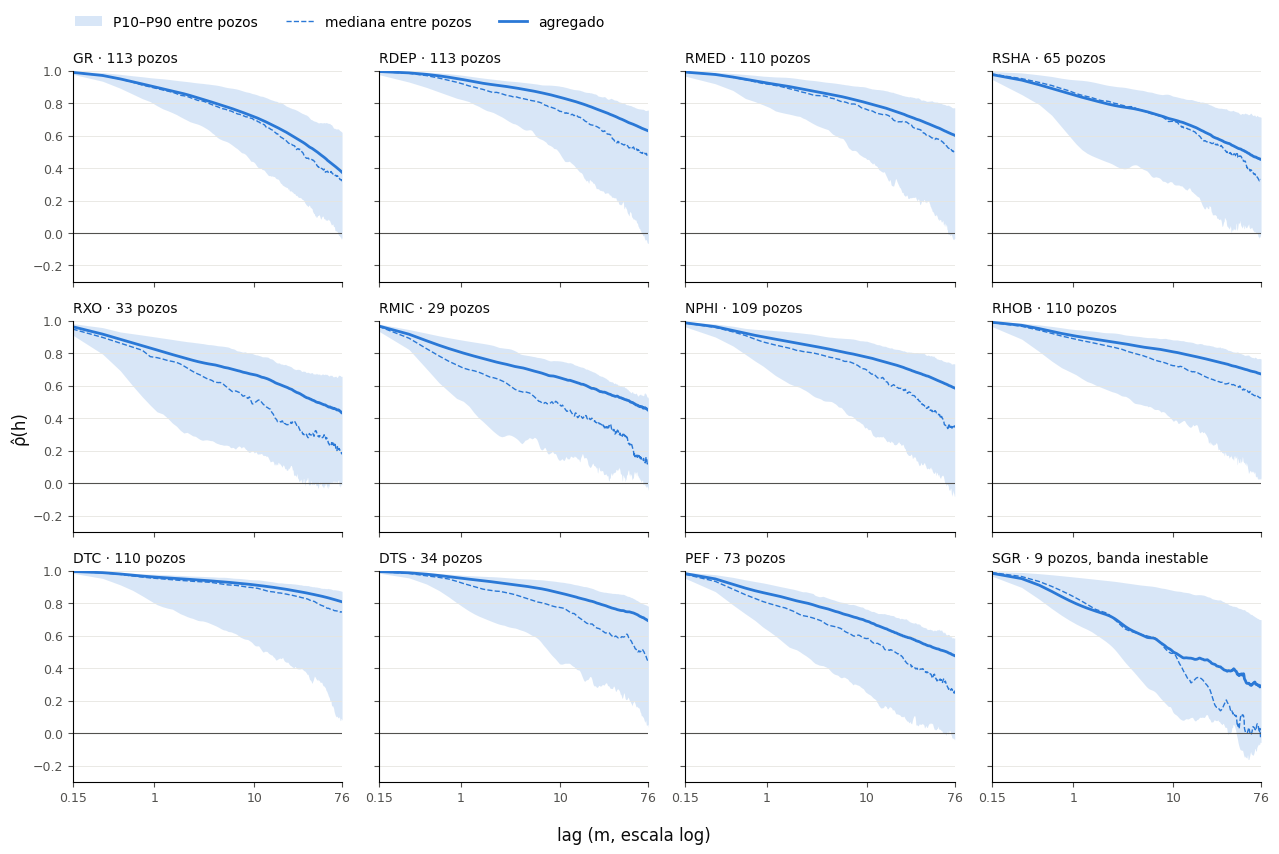

In [ ]:
from matplotlib.ticker import FixedLocator, FixedFormatter, NullLocator

blue, ink, muted, grid = "#2a78d6", "#0b0b0b", "#52514e", "#e6e5e0"

fig, axes = plt.subplots(3, 4, figsize=(13, 8.5), sharex=True, sharey=True)
for ax, curve in zip(axes.flat, formation_curves):
    b = acf_bands[curve].iloc[1:]
    wells = int(b["wells"].iloc[0])
    ax.fill_between(b["meters"], b["p10"], b["p90"], color=blue, alpha=0.18, linewidth=0, label="P10–P90 entre pozos")
    ax.plot(b["meters"], b["p50"], color=blue, lw=1, ls="--", label="mediana entre pozos")
    ax.plot(b["meters"], b["pooled"], color=blue, lw=2, label="agregado")
    ax.axhline(0, color=muted, lw=0.8)
    ax.set_title(f"{curve} · {wells} pozos" + (", banda inestable" if wells < 20 else ""),
                 loc="left", fontsize=10, color=ink)
    ax.set_xscale("log")
    ax.set_xlim(0.152, 76)
    ax.set_ylim(-0.3, 1)
    ax.xaxis.set_major_locator(FixedLocator([0.152, 1, 10, 76]))
    ax.xaxis.set_major_formatter(FixedFormatter(["0.15", "1", "10", "76"]))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.grid(axis="y", color=grid, lw=0.6)
    ax.tick_params(colors=muted, labelsize=9)
    ax.spines[["top", "right"]].set_visible(False)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper left", ncol=3, frameon=False, bbox_to_anchor=(0.06, 1.0))
fig.supxlabel("lag (m, escala log)", color=ink)
fig.supylabel("ρ̂(h)", color=ink)
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig(f"{FIG_DIR}/etapa3_acf_formacion.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
def norm_spectrum(df, col, seg_len, ref_m=4.6):
    spec, n_seg, n_wells = pooled_spectrum(df, col, seg_len)
    spec = spec[spec["k"] >= 3]
    # potencia media en ±15% alrededor de 4.6 m como referencia comun
    ref = spec.loc[spec["wavelength_m"].between(ref_m / 1.15, ref_m * 1.15), "power"].mean()
    return spec.assign(rel_power=spec["power"] / ref), n_seg, n_wells

spectra = {c: {m: norm_spectrum(pool_sorted, analysis_column(c), m) for m in (2000, 8000)}
           for c in formation_curves}

print(pd.DataFrame({c: {f"seg_{m}": s[m][1] for m in s} | {f"wells_{m}": s[m][2] for m in s}
                    for c, s in spectra.items()}).T)

      seg_2000  seg_8000  wells_2000  wells_8000
GR         600        89         113          70
RDEP       589        85         113          66
RMED       533        61         110          49
RSHA       257        28          65          23
RXO        125        11          33          10
RMIC        73         4          29           3
NPHI       363        33         109          31
RHOB       486        53         110          43
DTC        548        73         110          59
DTS         85         6          34           6
PEF        310        34          73          29
SGR         20         1           9           1


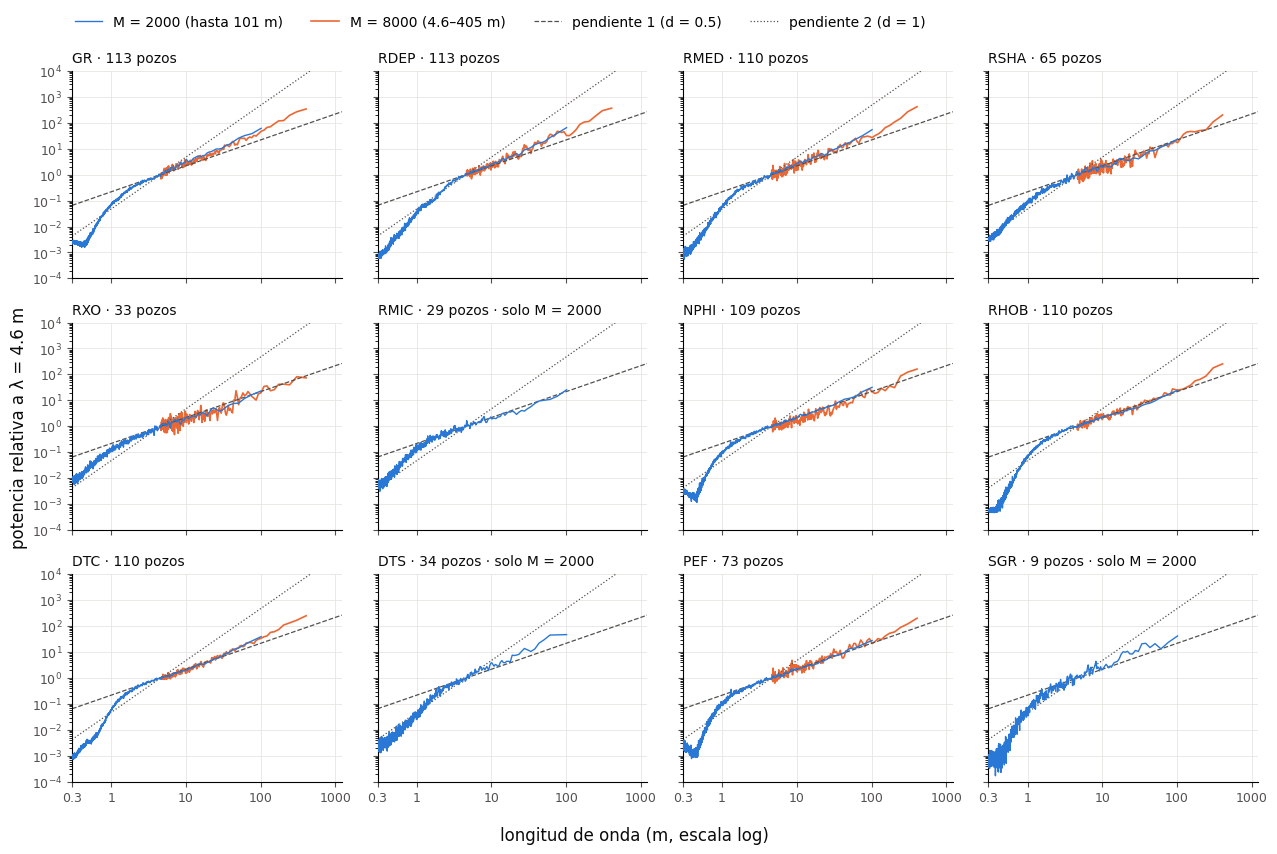

In [ ]:
blue, orange, ink, muted, grid = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e0"
ref_lam = np.array([0.3, 1220])

fig, axes = plt.subplots(3, 4, figsize=(13, 8.5), sharex=True, sharey=True)
for ax, curve in zip(axes.flat, formation_curves):
    s2, seg2, wells2 = spectra[curve][2000]
    s8, seg8, _ = spectra[curve][8000]
    ax.plot(s2["wavelength_m"], s2["rel_power"], color=blue, lw=1, zorder=3, label="M = 2000 (hasta 101 m)")
    if seg8 >= 10:
        # bajo 4.6 m M = 8000 no agrega nada y tapa a M = 2000
        long8 = s8[s8["wavelength_m"] >= 4.6]
        ax.plot(long8["wavelength_m"], long8["rel_power"], color=orange, lw=1.2, label="M = 8000 (4.6–405 m)")
    ax.plot(ref_lam, (ref_lam / 4.6) ** 1, color=muted, lw=0.9, ls="--", label="pendiente 1 (d = 0.5)")
    ax.plot(ref_lam, (ref_lam / 4.6) ** 2, color=muted, lw=0.9, ls=":", label="pendiente 2 (d = 1)")
    ax.set_title(f"{curve} · {wells2} pozos" + ("" if seg8 >= 10 else " · solo M = 2000"),
                 loc="left", fontsize=10, color=ink)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(0.3, 1220)
    ax.set_ylim(1e-4, 1e4)
    ax.xaxis.set_major_locator(FixedLocator([0.3, 1, 10, 100, 1000]))
    ax.xaxis.set_major_formatter(FixedFormatter(["0.3", "1", "10", "100", "1000"]))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.grid(color=grid, lw=0.6)
    ax.tick_params(colors=muted, labelsize=9)
    ax.spines[["top", "right"]].set_visible(False)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper left", ncol=4, frameon=False, bbox_to_anchor=(0.06, 1.0))
fig.supxlabel("longitud de onda (m, escala log)", color=ink)
fig.supylabel("potencia relativa a λ = 4.6 m", color=ink)
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig(f"{FIG_DIR}/etapa3_espectro_formacion.png", dpi=200, bbox_inches="tight")
plt.show()

## 3.2 OE2 - Ejecutar el análisis multivariado, con correlación cruzada entre curvas y detección conjunta de puntos de cambio como proxy de los contactos litológicos.

In [ ]:
from scipy.signal import lfilter

def joint_runs(df, cols):
    ok = df[cols].notna().all(axis=1).to_numpy()
    seg = df["depth_segment"].to_numpy()
    starts_run = ok & (np.r_[True, ~ok[:-1]] | np.r_[True, seg[1:] != seg[:-1]])
    run_id = np.cumsum(starts_run)
    return (df[ok].assign(run=run_id[ok], pos=np.flatnonzero(ok)).groupby("run")
            .agg(well=("WELL", "first"), segment=("depth_segment", "first"),
                 top=("DEPTH_MD", "min"), base=("DEPTH_MD", "max"),
                 start=("pos", "min"), n=("DEPTH_MD", "size")))

def pooled_ccf(df, x_col, y_col, min_len=2000, max_lag=125, ar=None):
    runs = joint_runs(df, [x_col, y_col])
    runs = runs[runs["n"] >= min_len]
    joint = df[[x_col, y_col]].notna().all(axis=1)
    mu_x = df[joint].groupby("WELL")[x_col].mean()
    mu_y = df[joint].groupby("WELL")[y_col].mean()
    x = df[x_col].to_numpy()
    y = df[y_col].to_numpy()
    lags = np.arange(-max_lag, max_lag + 1)
    sxy = np.zeros(len(lags))
    pairs = np.zeros(len(lags))
    sxx = syy = 0.0
    for r in runs.itertuples():
        a = x[r.start:r.start + r.n] - mu_x[r.well]
        b = y[r.start:r.start + r.n] - mu_y[r.well]
        if ar is not None:
            # mismo filtro a las dos series, dentro del tramo; se pierden las p primeras filas
            a = lfilter(np.r_[1, -ar], 1, a)[len(ar):]
            b = lfilter(np.r_[1, -ar], 1, b)[len(ar):]
        m = len(a)
        sxx += a @ a
        syy += b @ b
        for i, h in enumerate(lags):
            # convención del libro (1.26): cov(x_{t+h}, y_t)
            if h >= 0:
                sxy[i] += a[h:] @ b[:m - h]
            else:
                sxy[i] += a[:m + h] @ b[-h:]
            pairs[i] += m - abs(h)
    out = pd.DataFrame({"lag": lags, "meters": lags * 0.152, "pairs": pairs.astype(int),
                        "ccf": sxy / np.sqrt(sxx * syy)})
    out.attrs["sxx"], out.attrs["syy"] = sxx, syy
    return out, runs

x_col, y_col = analysis_column("GR"), analysis_column("NPHI")
ccf_raw, runs_gn = pooled_ccf(pool_sorted, x_col, y_col)
ccf_rev, _ = pooled_ccf(pool_sorted, y_col, x_col)

print(len(runs_gn), runs_gn["well"].nunique(), runs_gn["n"].sum())
print(valid_runs(pool_sorted, "GR")[["start", "n"]].reset_index(drop=True)
      .equals(joint_runs(pool_sorted, ["GR"])[["start", "n"]].reset_index(drop=True)))
print(np.allclose(ccf_raw["ccf"].to_numpy(), ccf_rev["ccf"].to_numpy()[::-1]))
print(ccf_raw["pairs"].iloc[-1] == (runs_gn["n"] - 125).sum())

show = [-125, -50, -25, -5, -1, 0, 1, 5, 25, 50, 125]
print(ccf_raw.set_index("lag").loc[show].round(3).to_string())
print(ccf_raw.loc[ccf_raw["ccf"].abs().idxmax(), ["lag", "meters", "ccf"]])

154 109 859729
True
True
True
      meters   pairs    ccf
lag                        
-125 -19.000  840479  0.228
-50   -7.600  852029  0.273
-25   -3.800  855879  0.299
-5    -0.760  858959  0.349
-1    -0.152  859575  0.370
 0     0.000  859729  0.371
 1     0.152  859575  0.369
 5     0.760  858959  0.347
 25    3.800  855879  0.299
 50    7.600  852029  0.265
 125  19.000  840479  0.212
lag       0.000000
meters    0.000000
ccf       0.371316
Name: 125, dtype: float64


In [ ]:
from scipy.linalg import solve_toeplitz

def ar_from_acf(rho, p):
    # Yule-Walker: Toeplitz con rho(0..p-1), lado derecho rho(1..p)
    return solve_toeplitz(rho[:p], rho[1:p + 1])

rho_gr = acf_b["rho_n"].to_numpy()
check, _ = pooled_ccf(pool_sorted, x_col, x_col)
print(np.isclose(check.set_index("lag").at[125, "ccf"], rho_gr[125]))

pw = {}
for p in [7, 25]:
    phi = ar_from_acf(rho_gr, p)
    resid, _ = pooled_ccf(pool_sorted, x_col, x_col, ar=phi)
    resid = resid[resid["lag"] > 0]
    worst = resid.loc[resid["ccf"].abs().idxmax()]
    print(p, np.isclose(phi[-1], acf_b["pacf"].iloc[p]), round(worst["ccf"], 3), int(worst["lag"]),
          round(resid.loc[resid["lag"].isin([1, 5, 25, 125]), "ccf"], 3).tolist())
    pw[p], _ = pooled_ccf(pool_sorted, x_col, y_col, ar=phi)

show = [-125, -25, -5, -3, -2, -1, 0, 1, 2, 3, 5, 25, 125]
table = pd.DataFrame({"raw": ccf_raw.set_index("lag")["ccf"],
                      "pw_7": pw[7].set_index("lag")["ccf"],
                      "pw_25": pw[25].set_index("lag")["ccf"]})
print(table.loc[show].round(3).to_string())

True
7 True -0.043 9 [0.02, -0.011, 0.0, 0.004]
25 True 0.021 1 [0.021, -0.0, -0.007, 0.002]
        raw   pw_7  pw_25
lag                      
-125  0.228  0.002  0.002
-25   0.299  0.001 -0.001
-5    0.349  0.002  0.005
-3    0.361  0.022  0.024
-2    0.367  0.046  0.047
-1    0.370  0.073  0.074
 0    0.371  0.078  0.080
 1    0.369  0.063  0.065
 2    0.364  0.032  0.034
 3    0.358  0.011  0.013
 5    0.347  0.001  0.004
 25   0.299  0.000 -0.002
 125  0.212  0.000 -0.000


In [ ]:
from itertools import combinations
from numpy.lib.stride_tricks import sliding_window_view

def ar_ols(df, col, p, min_len=2000):
    x = df[col].to_numpy()
    mu = df.groupby("WELL")[col].mean()
    runs = valid_runs(df, col)
    runs = runs[runs["n"] >= min_len]
    xtx = np.zeros((p, p))
    xty = np.zeros(p)
    for r in runs.itertuples():
        a = x[r.start:r.start + r.n] - mu[r.well]
        v = sliding_window_view(a, p + 1)
        # rezagos 1..p de x_t; la ultima columna de v es x_t
        lagged = v[:, :p][:, ::-1]
        xtx += lagged.T @ lagged
        xty += lagged.T @ v[:, p]
    return np.linalg.solve(xtx, xty)

def ar_order(df, col, tol=0.05, candidates=(10, 15, 20, 25, 30, 40, 50)):
    acf, _ = pooled_acf(df, col, 2000, 50)
    pacf = durbin_levinson(acf["rho_n"].to_numpy())
    # orden minimo: misma regla que direct_m del objetivo 1
    p0 = np.flatnonzero(np.abs(pacf[1:]) > 0.05).max() + 1
    # se sube p solo si la ACF de la entrada filtrada no cumple |rho| < tol en lags 1-125
    for p in [p0] + [c for c in candidates if c > p0]:
        phi = ar_ols(df, col, p)
        resid, _ = pooled_ccf(df, col, col, ar=phi)
        resid = resid[resid["lag"] > 0].set_index("lag")["ccf"]
        worst = resid.abs().idxmax()
        if abs(resid[worst]) < tol:
            break
    return p, phi, resid[worst], worst, p0

def peak_and_width(ccf):
    c = ccf.set_index("lag")["ccf"].abs()
    peak = c.idxmax()
    above = c >= c[peak] / 2
    lo = hi = peak
    while lo - 1 in c.index and above[lo - 1]:
        lo -= 1
    while hi + 1 in c.index and above[hi + 1]:
        hi += 1
    return peak, lo, hi

def ccf_summary(df, x_name, y_name, input_name, filters):
    x, y = analysis_column(x_name), analysis_column(y_name)
    # el filtro de la entrada se aplica a las dos series; la orientacion x-y no cambia
    p, phi = filters[input_name][:2]
    raw, runs = pooled_ccf(df, x, y, max_lag=0)
    pw, _ = pooled_ccf(df, x, y, max_lag=25, ar=phi)
    peak, lo, hi = peak_and_width(pw)
    sub = df[df["WELL"].isin(runs["well"].unique())]
    well_peaks = pd.Series({w: peak_and_width(pooled_ccf(g, x, y, max_lag=10, ar=phi)[0])[0]
                            for w, g in sub.groupby("WELL")})
    return {"wells": len(well_peaks), "p": p, "raw_0": raw["ccf"].iloc[0],
            "pw_0": pw.set_index("lag").at[0, "ccf"], "pw_peak": pw.set_index("lag").at[peak, "ccf"],
            "peak_lag": peak, "half_lo": lo, "half_hi": hi,
            "well_p10": well_peaks.quantile(0.1), "well_p50": well_peaks.median(),
            "well_p90": well_peaks.quantile(0.9), "well_lag0": (well_peaks == 0).mean(),
            "well_within1": (well_peaks.abs() <= 1).mean()}

core = ["GR", "RDEP", "NPHI", "RHOB", "DTC"]
pairs = list(combinations(core, 2)) + [("RDEP", "RMED"), ("PEF", "RHOB")]

filters = {}
for name in dict.fromkeys(n for pair in pairs for n in pair):
    filters[name] = ar_order(pool_sorted, analysis_column(name))
fit_ok = {n: abs(f[2]) < 0.05 for n, f in filters.items()}
for n, f in filters.items():
    print(n, f[4], f[0], round(f[2], 3), f[3], fit_ok[n])

rows, inputs = {}, {}
for a, b in pairs:
    key = f"{a}-{b}"
    inputs[key] = a if fit_ok[a] else b if fit_ok[b] else "none"
    if inputs[key] == "none":
        raw, _ = pooled_ccf(pool_sorted, analysis_column(a), analysis_column(b), max_lag=0)
        rows[key] = {"raw_0": raw["ccf"].iloc[0]}
    else:
        rows[key] = ccf_summary(pool_sorted, a, b, inputs[key], filters)

ccf_table = pd.DataFrame(rows).T.round(3)
ccf_table.insert(0, "input", pd.Series(inputs))
print(ccf_table.to_string())

GR 7 7 -0.043 9 True
RDEP 11 11 -0.037 12 True
NPHI 7 10 -0.046 12 True
RHOB 8 8 -0.042 11 True
DTC 9 9 -0.045 11 True
RMED 6 6 -0.046 8 True
PEF 7 10 -0.047 13 True
          input  wells     p  raw_0   pw_0  pw_peak  peak_lag  half_lo  half_hi  well_p10  well_p50  well_p90  well_lag0  well_within1
GR-RDEP      GR  113.0   7.0 -0.021 -0.036   -0.036       0.0     -1.0      1.0      -6.6       0.0       5.8      0.248         0.513
GR-NPHI      GR  109.0   7.0  0.371  0.075    0.075       0.0     -2.0      1.0      -2.0       0.0       1.0      0.385         0.807
GR-RHOB      GR  110.0   7.0  0.066 -0.017   -0.017       0.0      0.0      0.0      -3.1       0.0       4.1      0.209         0.500
GR-DTC       GR  110.0   7.0  0.166  0.062    0.062       0.0     -1.0      2.0      -1.0       0.0       2.0      0.455         0.809
RDEP-NPHI  RDEP  108.0  11.0 -0.492 -0.045   -0.045       0.0     -2.0      2.0      -2.0       0.0       4.0      0.194         0.500
RDEP-RHOB  RDEP  109.0  

In [ ]:
def well_peaks_detail(df, x_name, y_name, input_name, filters, lags=(0,)):
    x, y = analysis_column(x_name), analysis_column(y_name)
    phi = filters[input_name][1]
    _, runs = pooled_ccf(df, x, y, max_lag=0)
    sub = df[df["WELL"].isin(runs["well"].unique())]
    rows = {}
    for w, g in sub.groupby("WELL"):
        c, r = pooled_ccf(g, x, y, max_lag=10, ar=phi)
        sxx, syy = c.attrs["sxx"], c.attrs["syy"]
        c = c.set_index("lag")["ccf"]
        peak = c.abs().idxmax()
        rows[w] = {"rows": r["n"].sum(), "peak_lag": peak, "ccf_peak": c[peak], "ccf_0": c[0],
                   "sxx": sxx, "syy": syy} | {f"ccf_{h}": c[h] for h in lags}
    t = pd.DataFrame(rows).T
    total = np.sqrt(t["sxx"].sum() * t["syy"].sum())
    # contribucion exacta de cada pozo al agregado en el lag h
    for h in lags:
        t[f"contrib_{h}"] = t[f"ccf_{h}"] * np.sqrt(t["sxx"] * t["syy"]) / total
    return t.drop(columns=["sxx", "syy"] + [f"ccf_{h}" for h in lags if h != 0])

details = {}
for (a, b), lags in [(("RDEP", "RMED"), [0]), (("PEF", "RHOB"), [0, -4])]:
    key = f"{a}-{b}"
    t = well_peaks_detail(pool_sorted, a, b, inputs[key], filters, lags)
    details[key] = t
    print(key, len(t), {h: round(t[f"contrib_{h}"].sum(), 3) for h in lags},
          ccf_table.at[key, "pw_0"], ccf_table.at[key, "pw_peak"])
    off = t[t["peak_lag"].abs() >= 2].sort_values(f"contrib_{lags[-1]}", key=abs, ascending=False)
    print(len(off), off[[f"contrib_{h}" for h in lags]].sum().round(3).to_dict())
    print(off.head(15).round(3).to_string())

RDEP-RMED 110 {0: np.float64(0.611)} 0.611 0.611
33 {'contrib_0': 0.025}
             rows  peak_lag  ccf_peak  ccf_0  contrib_0
31/2-8    17889.0      -2.0     0.427  0.378      0.002
25/7-2    22683.0       2.0     0.338  0.309      0.002
26/4-1    17880.0      -2.0     0.149  0.084      0.002
35/11-5   18279.0       2.0     0.308  0.212      0.002
35/11-6   23002.0      -2.0     0.264  0.209      0.001
31/4-5    13301.0       2.0     0.365  0.272      0.001
25/5-1    18032.0       3.0     0.345  0.201      0.001
35/11-1   14176.0      -3.0     0.324  0.128      0.001
31/2-9     8574.0       2.0     0.311  0.240      0.001
34/10-21  22028.0      -2.0     0.367  0.240      0.001
35/9-2     9804.0       2.0     0.287  0.252      0.001
34/8-1    16718.0      -2.0     0.293  0.148      0.001
25/4-5    21282.0      -3.0     0.341  0.099      0.001
25/5-3    10723.0       3.0     0.329  0.235      0.001
29/6-1    21370.0      -2.0     0.204  0.093      0.001
PEF-RHOB 73 {0: np.float64(0.02

In [ ]:
print(pool_sorted.groupby("WELL")["pef_posible_contaminacion"].mean().agg(["median", "max"]).round(3).to_dict(),
      round(pool_sorted.loc[pool_sorted["WELL"] == "25/3-1", "pef_posible_contaminacion"].mean(), 3))

{'median': 0.002, 'max': 0.319} 0.094


In [ ]:
from scipy.stats import f as f_dist

def pooled_coherence(df, x_col, y_col, seg_len=2000):
    x = df[x_col].to_numpy()
    y = df[y_col].to_numpy()
    runs = joint_runs(df, [x_col, y_col])
    taper = np.hanning(seg_len)
    sxx = np.zeros(seg_len // 2 + 1)
    syy = np.zeros(seg_len // 2 + 1)
    sxy = np.zeros(seg_len // 2 + 1, dtype=complex)
    n_seg, wells = 0, set()
    for r in runs.itertuples():
        for s in range(r.n // seg_len):
            i = r.start + s * seg_len
            dx = np.fft.rfft(detrend(x[i:i + seg_len]) * taper)
            dy = np.fft.rfft(detrend(y[i:i + seg_len]) * taper)
            sxx += np.abs(dx) ** 2
            syy += np.abs(dy) ** 2
            sxy += dx * np.conj(dy)
            n_seg += 1
            wells.add(r.well)
    k = np.arange(seg_len // 2 + 1)
    # misma exclusion que en el espectro del objetivo 1: k >= 3
    out = pd.DataFrame({"k": k, "wavelength_m": seg_len * 0.152 / np.maximum(k, 1),
                        "coh": np.abs(sxy) ** 2 / (sxx * syy), "sign": np.sign(sxy.real)}).iloc[3:]
    return out, n_seg, len(wells)

coh_edges = [0.3, 1.2, 4.6, 19, 102]

def coherence_summary(df, x_name, y_name):
    coh, n_seg, n_wells = pooled_coherence(df, analysis_column(x_name), analysis_column(y_name))
    coh = coh.assign(band=pd.cut(coh["wavelength_m"], coh_edges))
    by_band = coh.groupby("band", observed=True).agg(coh=("coh", "median"), sign=("sign", "mean"))
    f_crit = f_dist.ppf(0.999, 2, 2 * n_seg - 2)
    out = {"segments": n_seg, "wells": n_wells, "C_001": f_crit / (n_seg - 1 + f_crit)}
    for band, row in by_band.iterrows():
        out[f"coh_{band.left}"] = row["coh"]
        out[f"sign_{band.left}"] = row["sign"]
    return out

self_coh, _, _ = pooled_coherence(pool_sorted, "GR", "GR")
print(np.allclose(self_coh["coh"], 1))

coh_table = pd.DataFrame({f"{a}-{b}": coherence_summary(pool_sorted, a, b) for a, b in pairs}).T
print(coh_table.round(3).to_string())

True
           segments  wells  C_001  coh_0.3  sign_0.3  coh_1.2  sign_1.2  coh_4.6  sign_4.6  coh_19.0  sign_19.0
GR-RDEP       589.0  113.0  0.012    0.002    -0.357    0.022    -1.000    0.006    -0.725     0.004     -0.846
GR-NPHI       363.0  109.0  0.019    0.004     0.186    0.050     1.000    0.165     1.000     0.304      1.000
GR-RHOB       486.0  110.0  0.014    0.004    -0.282    0.004    -0.604    0.007     1.000     0.002      0.538
GR-DTC        548.0  110.0  0.013    0.002     0.240    0.034     1.000    0.050     1.000     0.122      1.000
RDEP-NPHI     359.0  108.0  0.019    0.002    -0.082    0.049    -0.904    0.072    -1.000     0.063     -1.000
RDEP-RHOB     480.0  109.0  0.014    0.003     0.323    0.051     0.829    0.041     1.000     0.047      1.000
RDEP-DTC      542.0  109.0  0.013    0.002     0.143    0.070    -0.733    0.145    -1.000     0.116     -1.000
NPHI-RHOB     351.0  107.0  0.020    0.007    -0.296    0.101    -1.000    0.177    -1.000     0.14

In [ ]:
import time

def pelt_l2(X, pen, min_size=8):
    n = len(X)
    s1 = np.vstack([np.zeros(X.shape[1]), np.cumsum(X, 0)])
    s2 = np.r_[0, np.cumsum((X ** 2).sum(1))]
    F = np.full(n + 1, np.inf)
    F[0] = -pen
    last = np.zeros(n + 1, dtype=int)
    cand = np.array([0])
    for t in range(min_size, n + 1):
        ok = t - cand >= min_size
        s = cand[ok]
        # costo L2 multivariado del segmento (s, t] con sumas acumuladas
        total = F[s] + s2[t] - s2[s] - ((s1[t] - s1[s]) ** 2).sum(1) / (t - s)
        i = total.argmin()
        F[t] = total[i] + pen
        last[t] = s[i]
        # poda de PELT: solo sobre candidatos admisibles
        keep = ~ok
        keep[ok] = total <= F[t]
        cand = np.r_[cand[keep], t]
    bkps, t = [], n
    while t > 0:
        bkps.append(t)
        t = last[t]
    return sorted(bkps)

def dp_l2(X, pen, min_size=8):
    n = len(X)
    s1 = np.vstack([np.zeros(X.shape[1]), np.cumsum(X, 0)])
    s2 = np.r_[0, np.cumsum((X ** 2).sum(1))]
    F = np.full(n + 1, np.inf)
    F[0] = -pen
    last = np.zeros(n + 1, dtype=int)
    for t in range(min_size, n + 1):
        s = np.arange(t - min_size + 1)
        s = s[np.isfinite(F[s])]
        total = F[s] + s2[t] - s2[s] - ((s1[t] - s1[s]) ** 2).sum(1) / (t - s)
        i = total.argmin()
        F[t] = total[i] + pen
        last[t] = s[i]
    bkps, t = [], n
    while t > 0:
        bkps.append(t)
        t = last[t]
    return sorted(bkps)

def elbow(pens, counts):
    # mayor distancia a la cuerda en log10(pen) vs log10(cambios + 1)
    x, y = np.log10(pens), np.log10(np.asarray(counts) + 1)
    dx, dy = x[-1] - x[0], y[-1] - y[0]
    dist = np.abs(dy * (x - x[0]) - dx * (y - y[0])) / np.hypot(dx, dy)
    return pens[dist.argmax()]

core_cols = [analysis_column(c) for c in core]
cp_runs = joint_runs(pool_sorted, core_cols)
cp_runs = cp_runs[cp_runs["n"] >= 2000]
joint = pool_sorted[core_cols].notna().all(axis=1)
med = pool_sorted[joint].groupby("WELL")[core_cols].median()
mad = pool_sorted[joint].groupby("WELL")[core_cols].agg(lambda v: 1.4826 * (v - v.median()).abs().median())
print(len(cp_runs), cp_runs["well"].nunique(), cp_runs["n"].sum(), (mad == 0).sum().sum())

values = pool_sorted[core_cols].to_numpy()

def run_matrix(r):
    return (values[r.start:r.start + r.n] - med.loc[r.well].to_numpy()) / mad.loc[r.well].to_numpy()

pilot = cp_runs.loc[cp_runs["n"].idxmax()]
X = run_matrix(pilot)
print(pilot["well"], pilot["n"], pilot["top"], pilot["base"])
print(all(pelt_l2(X[:1500], b) == dp_l2(X[:1500], b) for b in [5, 50, 500]))

pens = 10 ** np.arange(0.5, 3.51, 0.25)
rows = []
for b in pens:
    t0 = time.time()
    bk = pelt_l2(X, b)
    thick = np.diff([0] + bk)[1:-1] * 0.152
    rows.append((b, len(bk) - 1, time.time() - t0, np.median(thick) if len(thick) else np.nan,
                 np.quantile(thick, 0.1) if len(thick) else np.nan,
                 np.quantile(thick, 0.9) if len(thick) else np.nan))
pilot_curve = pd.DataFrame(rows, columns=["pen", "n_cp", "seconds", "thick_p50_m", "thick_p10_m", "thick_p90_m"])
print(pilot_curve.round(2).to_string(index=False))
print(round(elbow(pens, pilot_curve["n_cp"]), 1))

150 103 782355 0
25/4-5 21013 853.30280505 4047.1268051
True
    pen  n_cp  seconds  thick_p50_m  thick_p10_m  thick_p90_m
   3.16   647     1.46         2.43         1.22        11.25
   5.62   465     1.30         3.19         1.22        17.74
  10.00   312     1.13         4.56         1.37        25.84
  17.78   228     1.28         6.69         1.52        33.32
  31.62   156     1.50        10.34         2.43        48.03
  56.23    88     1.73        21.58         3.74        94.94
 100.00    56     2.18        35.57         5.53       117.13
 177.83    36     3.26        60.34         8.54       165.10
 316.23    22     4.52       137.41        25.23       254.45
 562.34    18     4.15       151.24        40.10       379.03
1000.00    11     5.74       127.38        23.23       499.68
1778.28     7     8.73       340.40       112.10       556.85
3162.28     6    11.08       331.51       109.29       704.40
316.2


In [ ]:
import os

cp_path = os.path.join(os.path.dirname(FIG_DIR), "etapa3_cp_cuts.csv")

# cache: borrar el archivo si cambia la curacion, la escala o la grilla
if os.path.exists(cp_path):
    cuts = pd.read_csv(cp_path)
else:
    t0 = time.time()
    rows = []
    for r in cp_runs.itertuples():
        X = run_matrix(r)
        for k, b in enumerate(pens):
            for c in pelt_l2(X, b)[:-1]:
                rows.append((r.well, r.start, k, c))
    cuts = pd.DataFrame(rows, columns=["well", "start", "pen_idx", "cut"])
    cuts.to_csv(cp_path, index=False)
    print(round((time.time() - t0) / 60, 1))

pilot_counts = cuts[cuts["start"] == pilot["start"]].groupby("pen_idx").size().reindex(range(len(pens)), fill_value=0)
print((pilot_counts.to_numpy() == pilot_curve["n_cp"].to_numpy()).all())

cut_lists = cuts.groupby(["start", "pen_idx"])["cut"].apply(np.sort).to_dict()
seg_parts = []
for r in cp_runs.itertuples():
    for k in range(len(pens)):
        edges = np.r_[0, cut_lists.get((r.start, k), []), r.n]
        thick = np.diff(edges) * 0.152
        censored = np.zeros(len(thick), dtype=bool)
        censored[[0, -1]] = True
        seg_parts.append(pd.DataFrame({"well": r.well, "pen_idx": k, "thick_m": thick, "censored": censored}))
segs = pd.concat(seg_parts, ignore_index=True)

idx = range(len(pens))
inner = segs[~segs["censored"]]
n_cp = cuts.groupby("pen_idx").size().reindex(idx, fill_value=0).to_numpy()
total_km = cp_runs["n"].sum() * 0.152 / 1000
q = inner.groupby("pen_idx")["thick_m"].quantile([0.1, 0.5, 0.9]).unstack().reindex(idx)
well_med = inner.groupby(["pen_idx", "well"])["thick_m"].median().groupby("pen_idx").median().reindex(idx)
cens_len = segs[segs["censored"]].groupby("pen_idx")["thick_m"].sum() / segs.groupby("pen_idx")["thick_m"].sum()

hierarchy = pd.DataFrame({"pen": pens, "n_cp": n_cp, "per_km": n_cp / total_km,
                          "thick_p10": q[0.1].to_numpy(), "thick_p50": q[0.5].to_numpy(),
                          "thick_p90": q[0.9].to_numpy(), "well_med_p50": well_med.to_numpy(),
                          "wells_inner": inner.groupby("pen_idx")["well"].nunique().reindex(idx).to_numpy(),
                          "censored_len": cens_len.reindex(idx).to_numpy()})
print(round(total_km, 1))
print(hierarchy.round(2).to_string(index=False))
print(round(elbow(pens, n_cp), 1))

True
118.9
    pen  n_cp  per_km  thick_p10  thick_p50  thick_p90  well_med_p50  wells_inner  censored_len
   3.16 32556  273.77       1.22       1.98       7.60          1.98          103          0.01
   5.62 24108  202.73       1.22       2.43      11.10          2.43          103          0.01
  10.00 17333  145.76       1.22       3.19      15.93          3.42          103          0.02
  17.78 12065  101.46       1.22       4.41      23.71          4.86          103          0.03
  31.62  8343   70.16       1.37       6.23      34.50          6.99          103          0.04
  56.23  5589   47.00       1.52       9.27      53.53         10.64          103          0.07
 100.00  3645   30.65       2.28      15.35      80.86         17.63          103          0.10
 177.83  2393   20.12       3.34      24.78     113.54         26.22          103          0.15
 316.23  1564   13.15       5.32      37.39     162.43         42.18          103          0.22
 562.34   952    8.01       9

In [ ]:
tau = int(round(2 / 0.152))

def label_tops(labels):
    prev, cur = labels[:-1], labels[1:]
    change = (prev != cur) & pd.notna(prev) & pd.notna(cur)
    return np.flatnonzero(change) + 1

def near_mask(points, n, tau):
    mask = np.zeros(n, dtype=bool)
    for p in points:
        mask[max(p - tau, 0):p + tau + 1] = True
    return mask

def top_agreement(col):
    lab = pool_sorted[col].to_numpy()
    runs = []
    for r in cp_runs.itertuples():
        tops = label_tops(lab[r.start:r.start + r.n])
        runs.append((r, tops, near_mask(tops, r.n, tau)))
    rows = []
    for k in range(len(pens)):
        hits_t = n_t = hits_c = n_c = cov_c = cov_t = n_pos = 0
        for r, tops, top_mask in runs:
            cps = cut_lists.get((r.start, k), np.array([], dtype=int))
            cp_mask = near_mask(cps, r.n, tau)
            # solo se evalua lejos de los bordes del tramo
            t_ok = tops[(tops >= tau) & (tops < r.n - tau)]
            c_ok = cps[(cps >= tau) & (cps < r.n - tau)]
            hits_t += cp_mask[t_ok].sum()
            n_t += len(t_ok)
            hits_c += top_mask[c_ok].sum()
            n_c += len(c_ok)
            cov_c += cp_mask[tau:r.n - tau].sum()
            cov_t += top_mask[tau:r.n - tau].sum()
            n_pos += r.n - 2 * tau
        rows.append((pens[k], n_t, hits_t / n_t, cov_c / n_pos, n_c, hits_c / n_c, cov_t / n_pos))
    t = pd.DataFrame(rows, columns=["pen", "tops", "recall", "recall_chance", "cps", "precision", "precision_chance"])
    t["recall_excess"] = t["recall"] - t["recall_chance"]
    t["precision_excess"] = t["precision"] - t["precision_chance"]
    return t

in_runs = np.concatenate([np.arange(r.start, r.start + r.n) for r in cp_runs.itertuples()])
for col in ["FORMATION", "GROUP"]:
    lab = pool_sorted[col].to_numpy()
    n_tops = [label_tops(lab[r.start:r.start + r.n]) for r in cp_runs.itertuples()]
    print(col, round(pool_sorted[col].iloc[in_runs].isna().mean(), 3), sum(len(t) for t in n_tops),
          sum(len(t) > 0 for t in n_tops), cp_runs.loc[[len(t) > 0 for t in n_tops], "well"].nunique())

agreement = {col: top_agreement(col) for col in ["FORMATION", "GROUP"]}
for col, t in agreement.items():
    print(col)
    print(t.round(3).to_string(index=False))
    best = t.loc[t["recall_excess"].idxmax(), "pen"]
    print(round(best, 1), hierarchy.loc[np.isclose(hierarchy["pen"], best),
                                        ["n_cp", "per_km", "thick_p10", "thick_p50", "thick_p90", "censored_len"]]
          .round(2).to_dict("records"))

FORMATION 0.062 981 139 102
GROUP 0.0 358 131 98
FORMATION
     pen  tops  recall  recall_chance   cps  precision  precision_chance  recall_excess  precision_excess
   3.162   974   0.959          0.668 32415      0.058             0.033          0.291             0.024
   5.623   974   0.933          0.541 23997      0.066             0.033          0.392             0.033
  10.000   974   0.901          0.425 17259      0.078             0.033          0.476             0.044
  17.783   974   0.856          0.320 12021      0.093             0.033          0.536             0.060
  31.623   974   0.792          0.238  8316      0.112             0.033          0.554             0.079
  56.234   974   0.714          0.169  5576      0.139             0.033          0.544             0.106
 100.000   974   0.614          0.116  3638      0.177             0.033          0.498             0.144
 177.828   974   0.516          0.079  2391      0.216             0.033          0.438      

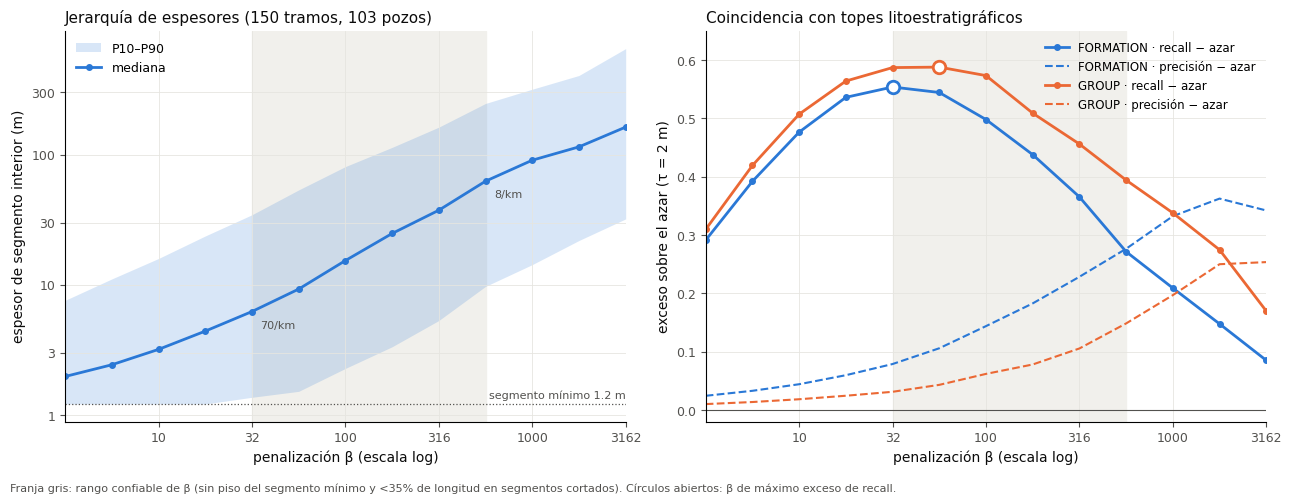

In [ ]:
from matplotlib.ticker import FixedLocator, FixedFormatter, NullLocator

blue, orange, ink, muted, grid, band = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e0", "#f1f0ec"
reliable = (31.6, 562.3)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), sharex=True)
for ax in (ax1, ax2):
    ax.axvspan(*reliable, color=band, zorder=0)
    ax.set_xscale("log")
    ax.set_xlim(pens[0], pens[-1])
    ax.xaxis.set_major_locator(FixedLocator([3.16, 10, 31.6, 100, 316, 1000, 3162]))
    ax.xaxis.set_major_formatter(FixedFormatter(["3.2", "10", "32", "100", "316", "1000", "3162"]))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.grid(color=grid, lw=0.6)
    ax.tick_params(colors=muted, labelsize=9)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlabel("penalización β (escala log)", color=ink)

h = hierarchy
ax1.fill_between(h["pen"], h["thick_p10"], h["thick_p90"], color=blue, alpha=0.18, lw=0, label="P10–P90")
ax1.plot(h["pen"], h["thick_p50"], color=blue, lw=2, marker="o", ms=4, label="mediana")
ax1.axhline(1.22, color=muted, lw=0.9, ls=":")
ax1.text(pens[-1], 1.3, "segmento mínimo 1.2 m", ha="right", va="bottom", fontsize=8, color=muted)
ax1.set_yscale("log")
ax1.yaxis.set_major_locator(FixedLocator([1, 3, 10, 30, 100, 300, 1000]))
ax1.yaxis.set_major_formatter(FixedFormatter(["1", "3", "10", "30", "100", "300", "1000"]))
ax1.yaxis.set_minor_locator(NullLocator())
ax1.set_ylabel("espesor de segmento interior (m)", color=ink)
ax1.set_title(f"Jerarquía de espesores ({len(cp_runs)} tramos, {cp_runs['well'].nunique()} pozos)",
              loc="left", fontsize=11, color=ink)
for b in reliable:
    row = h.iloc[(h["pen"] - b).abs().argmin()]
    ax1.annotate(f"{row['per_km']:.0f}/km", (row["pen"], row["thick_p50"]), xytext=(6, -12),
                 textcoords="offset points", fontsize=8, color=muted)
ax1.legend(frameon=False, loc="upper left", fontsize=9)

for col, color in [("FORMATION", blue), ("GROUP", orange)]:
    a = agreement[col]
    ax2.plot(a["pen"], a["recall_excess"], color=color, lw=2, marker="o", ms=4, label=f"{col} · recall − azar")
    ax2.plot(a["pen"], a["precision_excess"], color=color, lw=1.5, ls="--", label=f"{col} · precisión − azar")
    best = a.loc[a["recall_excess"].idxmax()]
    ax2.plot(best["pen"], best["recall_excess"], marker="o", ms=9, mfc="white", mec=color, mew=2, zorder=4)
ax2.axhline(0, color=muted, lw=0.8)
ax2.set_ylim(-0.02, 0.65)
ax2.set_ylabel("exceso sobre el azar (τ = 2 m)", color=ink)
ax2.set_title("Coincidencia con topes litoestratigráficos", loc="left", fontsize=11, color=ink)
ax2.legend(frameon=False, loc="upper right", fontsize=8.5)

fig.text(0.01, 0.005, "Franja gris: rango confiable de β (sin piso del segmento mínimo y <35% de longitud en segmentos cortados). "
         "Círculos abiertos: β de máximo exceso de recall.", fontsize=8, color=muted)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(f"{FIG_DIR}/etapa3_puntos_cambio.png", dpi=200, bbox_inches="tight")
plt.show()

## 3.3 OE3 - Derivar el tamaño de ventana W a partir de la escala de correlación observada, dejando explícito el criterio.

In [ ]:
def contact_distances(n, cuts):
    e = np.r_[0, cuts, n].astype(int)
    L = np.diff(e)
    seg = np.repeat(np.arange(len(L)), L)
    t = np.arange(n) - np.repeat(e[:-1], L)
    up = t + 1.0
    down = np.repeat(L, L) - t + 0.0
    # el borde del tramo no es contacto: ese lado queda censurado
    up_cens = seg == 0
    down_cens = seg == len(L) - 1
    lo = np.minimum(up, down)
    hi = np.minimum(np.where(up_cens, np.inf, up), np.where(down_cens, np.inf, down))
    return lo, hi, up_cens | down_cens, ((t == 0) & ~up_cens).sum()

def weighted_quantile(x, w, q):
    order = np.argsort(x, kind="stable")
    cw = np.cumsum(w[order])
    return x[order][np.searchsorted(cw, np.asarray(q) * cw[-1])]

row_well = np.repeat(cp_runs["well"].to_numpy(), cp_runs["n"].to_numpy())
w_well = 1 / cp_runs.groupby("well")["n"].sum().reindex(row_well).to_numpy()
w_row = np.ones(len(row_well))
print(len(row_well) == cp_runs["n"].sum(), np.isclose(w_well.sum(), cp_runs["well"].nunique()))

qs = [0.5, 0.75, 0.9]
rows = []
for k, b in enumerate(pens):
    parts = [contact_distances(r.n, cut_lists.get((r.start, k), [])) for r in cp_runs.itertuples()]
    lo = np.concatenate([p[0] for p in parts])
    hi = np.concatenate([p[1] for p in parts])
    cens = np.concatenate([p[2] for p in parts])
    n_first = sum(p[3] for p in parts)
    well_q90 = (pd.DataFrame({"well": row_well, "hi": hi}).groupby("well")["hi"]
                .quantile(0.9, interpolation="higher"))
    rows.append([b, n_first == hierarchy.at[k, "n_cp"], np.isclose(cens.mean(), hierarchy.at[k, "censored_len"])]
                + list(weighted_quantile(lo, w_well, qs)) + list(weighted_quantile(hi, w_well, qs))
                + list(weighted_quantile(lo, w_row, [0.9])) + list(weighted_quantile(hi, w_row, [0.9]))
                + list(well_q90.quantile([0.1, 0.5, 0.9], interpolation="higher")))

cols = ["pen", "cuts_ok", "cens_ok", "lo_50", "lo_75", "lo_90", "hi_50", "hi_75", "hi_90",
        "lo_90_s", "hi_90_s", "well90_p10", "well90_p50", "well90_p90"]
contact_dist = pd.DataFrame(rows, columns=cols)
contact_dist[cols[3:]] *= 0.152
contact_dist.insert(1, "thick_p50", hierarchy["thick_p50"].to_numpy())
contact_dist.insert(2, "censored", hierarchy["censored_len"].to_numpy())
print(contact_dist.round(2).to_string(index=False))

True True
    pen  thick_p50  censored  cuts_ok  cens_ok  lo_50  lo_75  lo_90  hi_50  hi_75  hi_90  lo_90_s  hi_90_s  well90_p10  well90_p50  well90_p90
   3.16       1.98      0.01     True     True   1.06   2.28   4.86   1.06   2.28   4.86     5.93     6.08        2.13        3.80        8.36
   5.62       2.43      0.01     True     True   1.52   3.65   7.60   1.52   3.65   7.60     9.27     9.42        3.04        6.23       12.62
  10.00       3.19      0.02     True     True   2.13   5.47  11.55   2.13   5.62  11.86    14.29    14.59        4.26       10.18       20.22
  17.78       4.41      0.03     True     True   3.34   8.21  16.72   3.34   8.36  17.48    21.13    21.74        6.54       14.74       32.22
  31.62       6.23      0.04     True     True   4.86  12.01  24.47   5.02  12.62  25.69    29.79    30.86        9.42       22.50       42.86
  56.23       9.27      0.07     True     True   7.14  17.18  33.14   7.45  18.24  35.72    39.98    42.41       14.29       32.83  

In [ ]:
ref_k = {"17.8": 3, "31.6": 4, "56.2": 5}
h_rows = {name: int(round(contact_dist.at[k, "hi_90"] / 0.152)) for name, k in ref_k.items()}

coverage = {}
for name, k in ref_k.items():
    parts = [contact_distances(r.n, cut_lists.get((r.start, k), [])) for r in cp_runs.itertuples()]
    lo = np.concatenate([p[0] for p in parts])
    hi = np.concatenate([p[1] for p in parts])
    h = h_rows[name]
    coverage[name] = pd.DataFrame({"well": row_well, "lo": lo <= h, "hi": hi <= h}).groupby("well").mean()

w_summary = pd.DataFrame({
    name: {"h_rows": h_rows[name], "W_rows": 2 * h_rows[name] + 1, "W_m": (2 * h_rows[name] + 1) * 0.152,
           "cov_mean_hi": c["hi"].mean(), "cov_mean_lo": c["lo"].mean(),
           "wells_ge_90": (c["hi"] >= 0.9).mean(), "cov_p10": c["hi"].quantile(0.1), "cov_min": c["hi"].min()}
    for name, c in coverage.items()}).T
print(w_summary.round(3).to_string())
print(coverage["31.6"].sort_values("hi").head(8).round(3).to_string())

      h_rows  W_rows     W_m  cov_mean_hi  cov_mean_lo  wells_ge_90  cov_p10  cov_min
17.8   115.0   231.0  35.112        0.901        0.907        0.592    0.758    0.576
31.6   169.0   339.0  51.528        0.901        0.909        0.553    0.773    0.630
56.2   235.0   471.0  71.592        0.900        0.914        0.553    0.753    0.653
            lo     hi
well                 
33/9-17  0.630  0.630
15/9-13  0.689  0.649
16/10-1  0.669  0.654
17/11-1  0.685  0.662
31/3-2   0.709  0.700
15/9-17  0.705  0.705
30/6-5   0.734  0.723
25/8-7   0.796  0.728


In [ ]:
seg_len = pool_sorted.groupby("depth_segment").agg(well=("WELL", "first"), n=("WELL", "size"))
print(len(seg_len), seg_len["n"].sum() == len(pool_sorted))

rows = []
for name, h in h_rows.items():
    W = 2 * h + 1
    short = seg_len["n"] < W
    lost = seg_len.loc[short, "n"].sum()
    edge = 2 * h * (~short).sum()
    wells_ok = set(seg_len.loc[~short, "well"])
    rows.append([name, W, W * 0.152, short.sum(), lost, lost / len(pool_sorted), edge / len(pool_sorted),
                 seg_len.loc[short, "well"].nunique(), seg_len["well"].nunique() - len(wells_ok)])

no_window = pd.DataFrame(rows, columns=["beta", "W_rows", "W_m", "short_segs", "short_rows", "short_share",
                                        "edge_share", "wells_affected", "wells_no_window"])
print(no_window.round(4).to_string(index=False))

W = 2 * h_rows["31.6"] + 1
well_loss = (seg_len.assign(lost=np.where(seg_len["n"] < W, seg_len["n"], 0))
             .groupby("well")[["n", "lost"]].sum())
well_loss["lost_share"] = well_loss["lost"] / well_loss["n"]
print(well_loss.sort_values("lost_share", ascending=False).head(10).round(3).to_string())

296 True
beta  W_rows    W_m  short_segs  short_rows  short_share  edge_share  wells_affected  wells_no_window
17.8     231 35.112          48        3950       0.0028      0.0399              21                0
31.6     339 51.528          54        5683       0.0040      0.0572              24                0
56.2     471 71.592          63        9245       0.0065      0.0766              28                0
               n  lost  lost_share
well                              
34/4-10 R   3880   672       0.173
32/2-1      3049   200       0.066
34/6-1 S    6479   307       0.047
31/3-2     10750   458       0.043
34/11-2 S  23310   724       0.031
34/3-1 A    2251    67       0.030
34/5-1 A   14592   369       0.025
31/3-4      5377   124       0.023
34/3-2 S   12216   260       0.021
17/4-1     17271   345       0.020


In [ ]:
status_well = build_status(pool_sorted, "WELL")
status_seg = status

interior, border = "interior_pendiente_Gmax", "borde_no_imputable"
moved = pd.DataFrame({c: {"interior_well": (status_well[c] == interior).sum(),
                          "interior_seg": (status_seg[c] == interior).sum(),
                          "to_border": ((status_well[c] == interior) & (status_seg[c] == border)).sum(),
                          "to_interior": ((status_well[c] == border) & (status_seg[c] == interior)).sum(),
                          "same_data": ((status_well[c] == "dato_real") == (status_seg[c] == "dato_real")).all()}
                      for c in curves}).T
print(moved.to_string())
print(moved[["interior_well", "interior_seg", "to_border", "to_interior"]].sum().to_dict())

seg = pool_sorted["depth_segment"].to_numpy()

def gap_lengths(col):
    g = (status_seg[col] == interior).to_numpy()
    start = g & (np.r_[True, ~g[:-1]] | np.r_[True, seg[1:] != seg[:-1]])
    return np.bincount(np.cumsum(start)[g])[1:]

bins = [1, 2, 9, 21, 101, np.inf]
names = ["1", "2-8", "9-20", "21-100", ">100"]
gap_rows = {}
for c in curves:
    L = gap_lengths(c)
    cls = pd.cut(L, bins, right=False, labels=names)
    gap_rows[c] = ({"gaps": len(L), "cells": L.sum(), "max_m": L.max() * 0.152 if len(L) else 0}
                   | {f"n_{k}": v for k, v in pd.Series(L).groupby(cls, observed=False).size().items()}
                   | {f"cells_{k}": v for k, v in pd.Series(L).groupby(cls, observed=False).sum().items()})
gaps = pd.DataFrame(gap_rows).T
gaps.loc["total"] = gaps.sum()
gaps.loc["total", "max_m"] = gaps["max_m"].max()
print(gaps.astype({k: int for k in gaps.columns if k != "max_m"}).round(2).to_string())

          interior_well interior_seg to_border to_interior same_data
CALI               5920         5920         0           0      True
BS                  318          318         0           0      True
DCAL               2012         2012         0           0      True
RHOB              14295        12897      1398           0      True
DRHO              12131        12007       124           0      True
GR                    0            0         0           0      True
SGR                3214         3214         0           0      True
NPHI              13712        13678        34           0      True
PEF               29949        22837      7112           0      True
DTC                8728         8728         0           0      True
DTS               17932        15326      2606           0      True
SP                19369        19194       175           0      True
ROP               10925        10583       342           0      True
RSHA              28639        285

In [ ]:
rng = np.random.default_rng(0)
gap_sizes = [1, 2, 4, 8, 12, 16, 20]

def interp_errors(df, col, g, runs, scale, n_draws=3000):
    x = df[col].to_numpy()
    runs = runs[(runs["n"] >= g + 2) & (runs["well"].map(scale) > 0)]
    by_well = []
    for w, r in runs.groupby("well"):
        counts = (r["n"] - g - 1).to_numpy()
        by_well.append((w, r["start"].to_numpy(), counts, np.cumsum(counts)))
    t = np.arange(1, g + 1) / (g + 1)
    errs = np.empty(n_draws)
    for j in range(n_draws):
        # cada pozo pesa igual; dentro del pozo, cada posicion valida pesa igual
        w, starts, counts, cum = by_well[rng.integers(len(by_well))]
        k = rng.integers(cum[-1])
        i = np.searchsorted(cum, k, side="right")
        a = starts[i] + k - (cum[i] - counts[i])
        b = a + g + 1
        est = x[a] + t * (x[b] - x[a])
        errs[j] = np.abs(est - x[a + 1:b]).mean() / scale[w]
    return errs

med_err, p90_err = {}, {}
for c in formation_curves:
    col = analysis_column(c)
    runs = valid_runs(pool_sorted, col)
    scale = pool_sorted.groupby("WELL")[col].agg(lambda v: 1.4826 * (v - v.median()).abs().median())
    res = {g: interp_errors(pool_sorted, col, g, runs, scale) for g in gap_sizes}
    med_err[c] = {g: np.median(e) for g, e in res.items()}
    p90_err[c] = {g: np.quantile(e, 0.9) for g, e in res.items()}

med_err = pd.DataFrame(med_err).T
p90_err = pd.DataFrame(p90_err).T
print(med_err.round(3).to_string())
print(p90_err.round(3).to_string())
print((med_err[8] > 0.5).any())

         1      2      4      8      12     16     20
GR    0.033  0.057  0.100  0.139  0.177  0.190  0.210
RDEP  0.008  0.015  0.029  0.060  0.079  0.100  0.114
RMED  0.013  0.022  0.043  0.075  0.090  0.111  0.117
RSHA  0.022  0.043  0.076  0.128  0.158  0.171  0.190
RXO   0.052  0.089  0.130  0.173  0.213  0.230  0.252
RMIC  0.038  0.066  0.108  0.163  0.193  0.222  0.245
NPHI  0.035  0.058  0.102  0.155  0.187  0.213  0.233
RHOB  0.022  0.039  0.073  0.119  0.143  0.169  0.179
DTC   0.012  0.021  0.041  0.077  0.097  0.110  0.127
DTS   0.015  0.027  0.048  0.090  0.118  0.146  0.161
PEF   0.046  0.075  0.127  0.213  0.254  0.289  0.316
SGR   0.033  0.052  0.090  0.141  0.166  0.200  0.228
         1      2      4      8      12     16     20
GR    0.135  0.200  0.294  0.408  0.483  0.522  0.606
RDEP  0.063  0.101  0.178  0.299  0.361  0.433  0.494
RMED  0.090  0.139  0.237  0.389  0.410  0.479  0.511
RSHA  0.179  0.244  0.393  0.519  0.614  0.670  0.726
RXO   0.311  0.428  0.561  0

In [ ]:
def interpolate_gaps(df, cols, g_max=8):
    out = df[cols].copy()
    seg = df["depth_segment"].to_numpy()
    masks = {}
    for c in cols:
        x = out[c].to_numpy().copy()
        na = np.isnan(x)
        start = na & (np.r_[True, ~na[:-1]] | np.r_[True, seg[1:] != seg[:-1]])
        run_id = np.cumsum(start)[na]
        _, first, length = np.unique(run_id, return_index=True, return_counts=True)
        filled = np.zeros(len(x), dtype=bool)
        for a0, L in zip(np.flatnonzero(na)[first], length):
            a, b = a0 - 1, a0 + L
            # solo huecos interiores del sub-tramo y no mas largos que g_max
            if L <= g_max and a >= 0 and b < len(x) and seg[a] == seg[a0] == seg[b]:
                x[a0:b] = x[a] + np.arange(1, L + 1) / (L + 1) * (x[b] - x[a])
                filled[a0:b] = True
        out[c] = x
        masks[c] = filled
    return out, pd.DataFrame(masks, index=df.index)

filled_base, mask_base = interpolate_gaps(pool_sorted, curves)
expected = gaps.loc[curves, "cells_1"] + gaps.loc[curves, "cells_2-8"]
print((mask_base.sum() == expected).all(), mask_base.sum().sum())
print(all((status_seg.loc[mask_base[c], c] == interior).all() for c in curves))
print(all(filled_base[c][~mask_base[c]].equals(pool_sorted[c][~mask_base[c]]) for c in curves))

model_cols = [analysis_column(c) for c in curves]
_, mask_model = interpolate_gaps(pool_sorted, model_cols)
cmp = pd.DataFrame({"base": mask_base.sum().rename(analysis_column), "model": mask_model.sum()})
print(cmp[cmp["base"] != cmp["model"]])

True 4818
True
True
           base  model
ROP_log10   414    420


In [ ]:
odd = pool_sorted["ROP"].notna() & pool_sorted["ROP_log10"].isna()
print(odd.sum(), pool_sorted.loc[odd, ["WELL", "DEPTH_MD", "ROP"]].to_string())

48               WELL     DEPTH_MD  ROP
296616     25/10-9  2085.944800  0.0
296617     25/10-9  2086.096800  0.0
359162      25/2-7   397.178001  0.0
359163      25/2-7   397.330001  0.0
359164      25/2-7   397.482001  0.0
359165      25/2-7   397.634001  0.0
359166      25/2-7   397.786001  0.0
359167      25/2-7   397.938001  0.0
359168      25/2-7   398.090001  0.0
359169      25/2-7   398.242001  0.0
359170      25/2-7   398.394001  0.0
359171      25/2-7   398.546001  0.0
359172      25/2-7   398.698001  0.0
359173      25/2-7   398.850001  0.0
704663   31/2-21 S  2174.272400  0.0
704664   31/2-21 S  2174.424400  0.0
704665   31/2-21 S  2174.576400  0.0
704666   31/2-21 S  2174.728400  0.0
704667   31/2-21 S  2174.880400  0.0
704668   31/2-21 S  2175.032400  0.0
704669   31/2-21 S  2175.184400  0.0
704670   31/2-21 S  2175.336400  0.0
704671   31/2-21 S  2175.488400  0.0
704672   31/2-21 S  2175.640400  0.0
704673   31/2-21 S  2175.792400  0.0
704674   31/2-21 S  2175.944400  0.

## 3.4 OE4 - Seleccionar un subconjunto de pozos representativos para inspección visual detallada.

In [ ]:
flags = {
    "31/3-2": "cobertura 0.70; SP aparcado; perdida sub-tramos 4.3%; sin CALI; RMIC 92% faltante",
    "17/11-1": "cobertura 0.66; SP aparcado; sub-tramos cortos",
    "25/4-5": "piloto PELT; desfase RDEP-RMED -3; racha DRHO enmascarada",
    "25/3-1": "desfase PEF-RHOB ~0.6 m; barita 9.4%",
    "36/7-3": "DRHO copia de RHOB; CALI congelado; 10/20 curvas ausentes",
    "31/4-10": "salto SP corregido; DRHO sospechosa",
    "15/9-13": "cobertura 0.65; RSHA/RXO ~91% faltante",
    "34/4-10 R": "perdida sub-tramos 17.3%",
    "34/6-1 S": "perdida sub-tramos 4.7%; 9/20 curvas ausentes",
    "33/9-17": "cobertura 0.63", "16/10-1": "cobertura 0.65", "15/9-17": "cobertura 0.71",
    "30/6-5": "cobertura 0.72", "25/8-7": "cobertura 0.73",
    "32/2-1": "perdida sub-tramos 6.6%; DTS 92% faltante", "34/11-2 S": "perdida sub-tramos 3.1%",
    "34/3-1 A": "perdida sub-tramos 3.0%", "34/5-1 A": "perdida sub-tramos 2.5%",
    "31/3-4": "perdida sub-tramos 2.3%", "34/3-2 S": "perdida sub-tramos 2.1%",
    "17/4-1": "11 saltos de profundidad", "34/2-4": "11 saltos de profundidad",
    "35/11-1": "desfase RDEP-RMED", "34/8-1": "desfase RDEP-RMED", "29/6-1": "desfase RDEP-RMED",
    "26/4-1": "desfase RDEP-RMED", "25/5-1": "desfase RDEP-RMED",
    "16/10-3": "salto SP corregido", "35/12-1": "salto SP corregido",
    "31/3-1": "salto SP corregido; piso RSHA", "31/2-19 S": "SP aparcado",
    "25/6-3": "canal SP muerto", "25/6-2": "escala ROP imposible",
    "30/3-3": "revestimiento enmascarado", "31/2-7": "revestimiento enmascarado",
    "31/2-9": "revestimiento enmascarado",
    "25/10-9": "ROP = 0", "25/2-7": "ROP = 0", "31/2-21 S": "ROP = 0", "35/3-7 S": "ROP = 0",
    "30/3-5 S": "11/20 curvas ausentes",
}
group_b = ["25/4-5", "31/3-2", "25/3-1", "34/4-10 R"]

k_ref = ref_k["31.6"]
g = pool_sorted.groupby("WELL")
desc = pd.DataFrame({"rows": g.size(), "segments": g["depth_segment"].nunique(),
                     "n_curves": g[curves].count().gt(0).sum(axis=1)})
cp_rows = cp_runs.groupby("well")["n"].sum()
cp_cuts = cuts[cuts["pen_idx"] == k_ref].groupby("well").size().reindex(cp_rows.index, fill_value=0)
desc["in_cp"] = desc.index.isin(cp_rows.index)
desc["coverage"] = coverage["31.6"]["hi"]
desc["contacts_km"] = cp_cuts / (cp_rows * 0.152 / 1000)
desc["lost_share"] = well_loss["lost_share"]
desc["flag"] = pd.Series(flags)
print(len(desc), desc["in_cp"].sum(), desc["flag"].notna().sum(), set(flags) <= set(desc.index))

def robust_z(s):
    med = s.median()
    return (s - med) / (1.4826 * (s - med).abs().median())

cols = ["log_rows", "coverage", "contacts_km"]
pop = desc[desc["in_cp"]].assign(log_rows=lambda d: np.log10(d["rows"]))
pop["suite"] = pd.qcut(pop["n_curves"], 3, labels=False, duplicates="drop")
z = pop.groupby("suite")[cols].transform(robust_z)
pop["dist"] = np.sqrt((z ** 2).sum(axis=1))

# la mediana usa toda la población del tercil; el medoide solo pozos sin señales
candidates = pop[pop["flag"].isna()]
group_a = candidates.loc[candidates.groupby("suite")["dist"].idxmin()]

print(pop.groupby("suite").agg(n_min=("n_curves", "min"), n_max=("n_curves", "max"), wells=("rows", "size"))
      .join(candidates.groupby("suite").size().rename("candidates")))
print(pop.groupby("suite")[["rows", "coverage", "contacts_km"]].median().round(3))
print(group_a[["suite", "n_curves", "rows", "segments", "coverage", "contacts_km", "lost_share", "dist"]].round(3))
print(desc.loc[group_b, ["n_curves", "rows", "segments", "in_cp", "coverage", "contacts_km", "lost_share"]].round(3))

representative = list(group_a.index) + group_b
print(representative)

118 103 41 True
       n_min  n_max  wells  candidates
suite                                 
0          8     12     36          29
1         13     14     47          27
2         15     18     20          11
          rows  coverage  contacts_km
suite                                
0      12024.0     0.946       92.116
1      11985.0     0.921       69.856
2      15169.5     0.895       61.926
          suite  n_curves   rows  segments  coverage  contacts_km  lost_share  \
WELL                                                                            
34/10-19      0        11  12644         1     0.932       92.146         0.0   
7/1-1         1        14  16241         1     0.927       76.552         0.0   
16/4-1        2        16  14082         1     0.924       56.642         0.0   

           dist  
WELL             
34/10-19  0.190  
7/1-1     0.532  
16/4-1    0.380  
           n_curves   rows  segments  in_cp  coverage  contacts_km  lost_share
WELL                    

In [ ]:
h_ref = h_rows["31.6"]
W_ref = 2 * h_ref + 1
well_pos = pool_sorted.groupby("WELL").indices

def well_view(well):
    pos = well_pos[well]
    d = pool_sorted.iloc[pos]
    runs = cp_runs[cp_runs["well"] == well]
    contacts = {name: np.concatenate([r.start + np.asarray(cut_lists.get((r.start, k), []), dtype=int)
                                      for r in runs.itertuples()] + [np.array([], dtype=int)])
                for name, k in ref_k.items()}
    # NaN fuera de los tramos conjuntos: ahi no hay contactos que evaluar
    uncovered = np.full(len(pos), np.nan)
    for r in runs.itertuples():
        _, d_hi, _, _ = contact_distances(r.n, cut_lists.get((r.start, ref_k["31.6"]), []))
        uncovered[r.start - pos[0]:r.start - pos[0] + r.n] = d_hi > h_ref
    tops = {col: label_tops(d[col].to_numpy()) + pos[0] for col in ["FORMATION", "GROUP"]}
    seg = d["depth_segment"].to_numpy()
    seg_breaks = pos[0] + np.flatnonzero(seg[1:] != seg[:-1]) + 1
    _, short_gap = interpolate_gaps(d, curves)
    state = (status_seg.iloc[pos][curves].astype(str)
             .replace({"dato_real": "dato", "borde_no_imputable": "borde",
                       "interior_pendiente_Gmax": "hueco_largo"})
             .mask(short_gap.to_numpy(), "hueco_corto"))
    if len(runs):
        r = runs.loc[runs["n"].idxmax()]
        center = r["start"] + r["n"] // 2
    else:
        sizes = d.groupby("depth_segment").size()
        center = pos[0] + np.flatnonzero(seg == sizes.idxmax())[0] + sizes.max() // 2
    zoom = (max(center - 2 * W_ref, pos[0]), min(center + 2 * W_ref, pos[-1]))
    return {"pos": pos, "contacts": contacts, "uncovered": uncovered, "tops": tops,
            "seg_breaks": seg_breaks, "state": state, "short_gap": short_gap, "zoom": zoom}

views = {w: well_view(w) for w in representative}

depth = pool_sorted["DEPTH_MD"].to_numpy()
checks = {}
for w, v in views.items():
    n_cuts = cuts[cuts["well"] == w].groupby("pen_idx").size()
    uncov = np.nanmean(v["uncovered"]) if desc.at[w, "in_cp"] else np.nan
    checks[w] = {
        "rows": len(v["pos"]),
        "cuts_ok": all(len(v["contacts"][n]) == n_cuts.get(k, 0) for n, k in ref_k.items()),
        "contacts_31.6": len(v["contacts"]["31.6"]),
        "uncovered": uncov,
        "cov_ok": np.isclose(1 - uncov, desc.at[w, "coverage"], equal_nan=True),
        "formation_tops": len(v["tops"]["FORMATION"]),
        "group_tops": len(v["tops"]["GROUP"]),
        "seg_ok": len(v["seg_breaks"]) == desc.at[w, "segments"] - 1,
        "gap_ok": (v["short_gap"].to_numpy() == mask_base.iloc[v["pos"]][curves].to_numpy()).all(),
        "short_gap": (v["state"] == "hueco_corto").sum().sum(),
        "long_gap": (v["state"] == "hueco_largo").sum().sum(),
        "zoom_top": depth[v["zoom"][0]], "zoom_base": depth[v["zoom"][1]],
    }
print(pd.DataFrame(checks).T.round(3).to_string())

            rows cuts_ok contacts_31.6 uncovered cov_ok formation_tops group_tops seg_ok gap_ok short_gap long_gap     zoom_top    zoom_base
34/10-19   12644    True           121  0.067948   True              6          5   True   True         0     5312      1746.96     1953.072
7/1-1      16241    True            51  0.072781   True              6          4   True   True         0     4547    2366.7048    2572.8168
16/4-1     14082    True           121  0.075779   True             12          7   True   True       229    12358  1561.473604  1767.585604
25/4-5     23005    True           156  0.210108   True             22          6   True   True        12    21690  2347.158805  2553.270805
31/3-2     10750    True            19  0.300415   True             14          7   True   True         2      814   705.624901   911.736901
25/3-1     21186    True           112  0.032795   True              9          7   True   True        93     2176     3347.608      3553.72
34/4-10 R   3

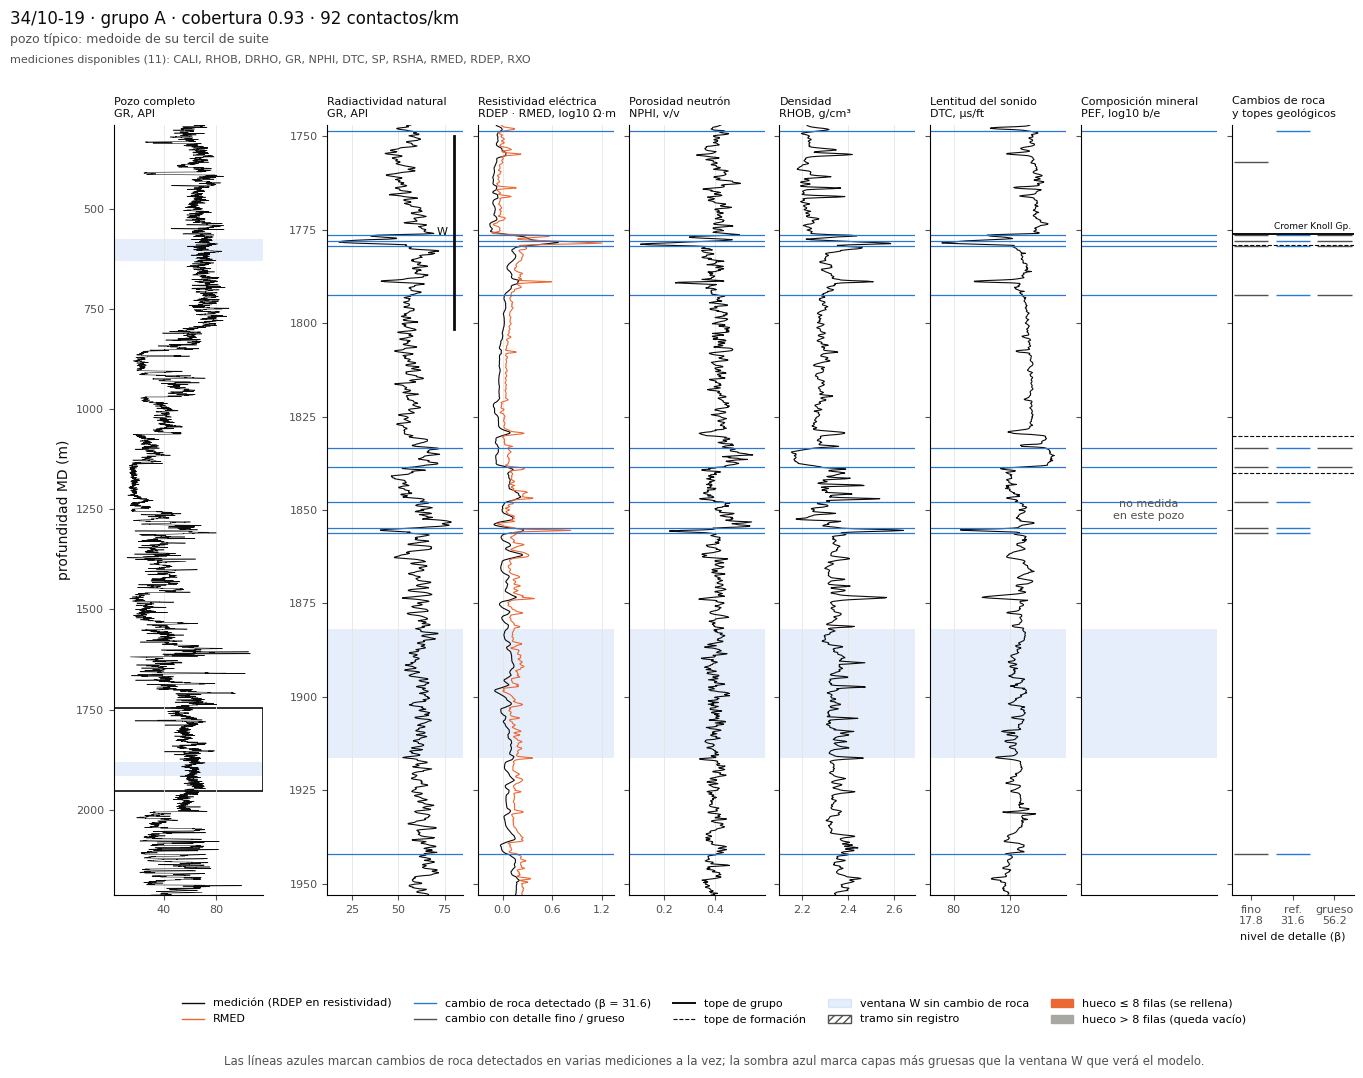

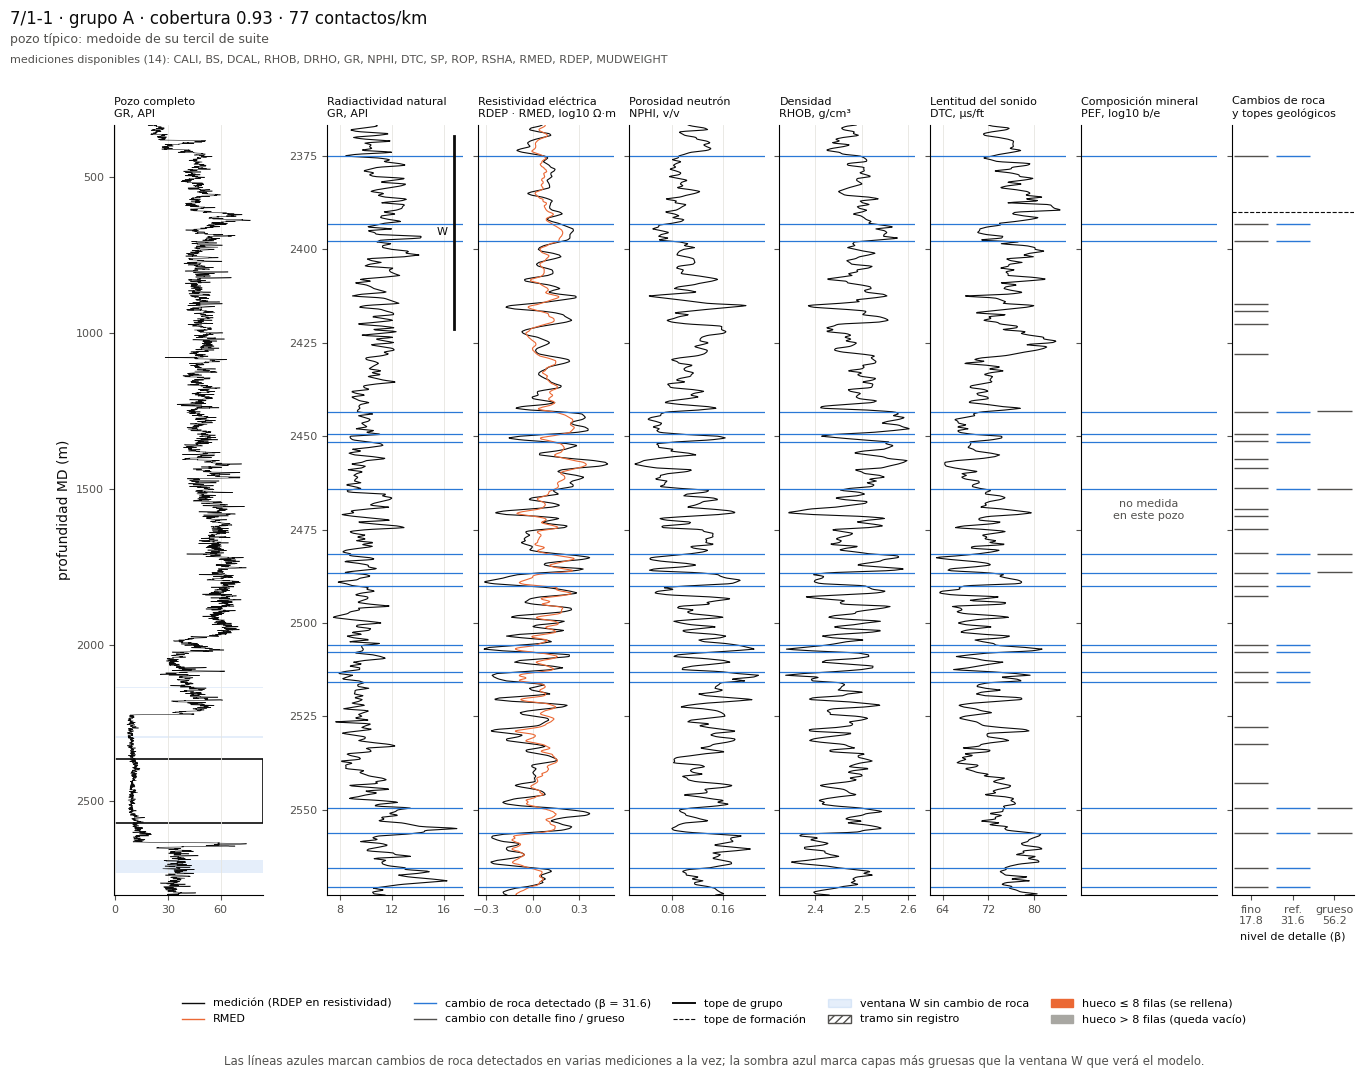

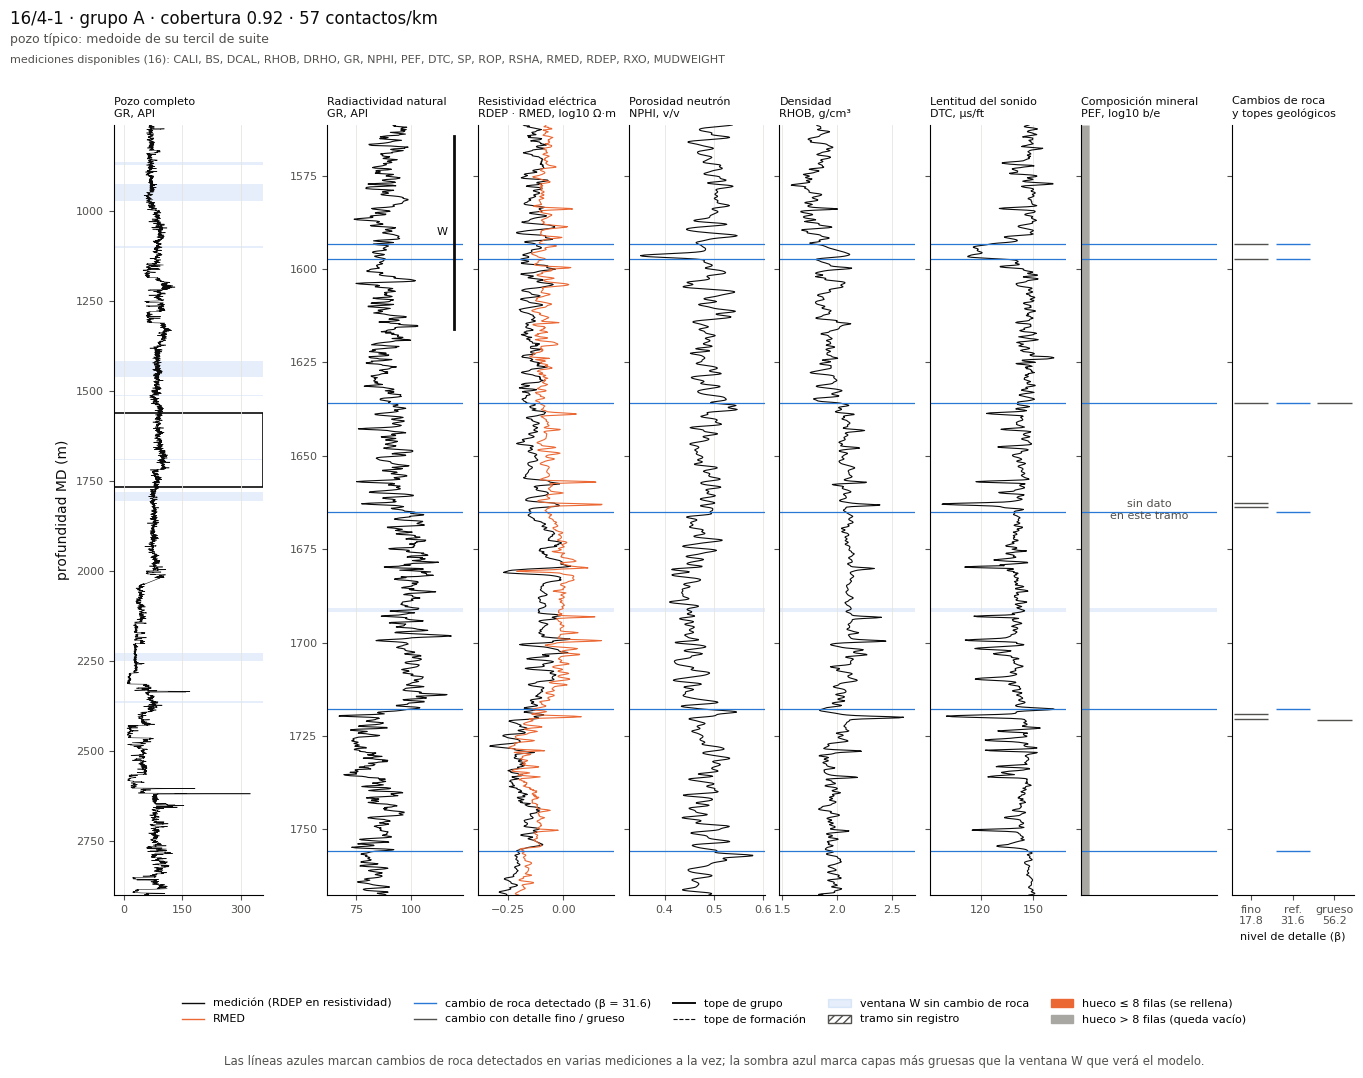

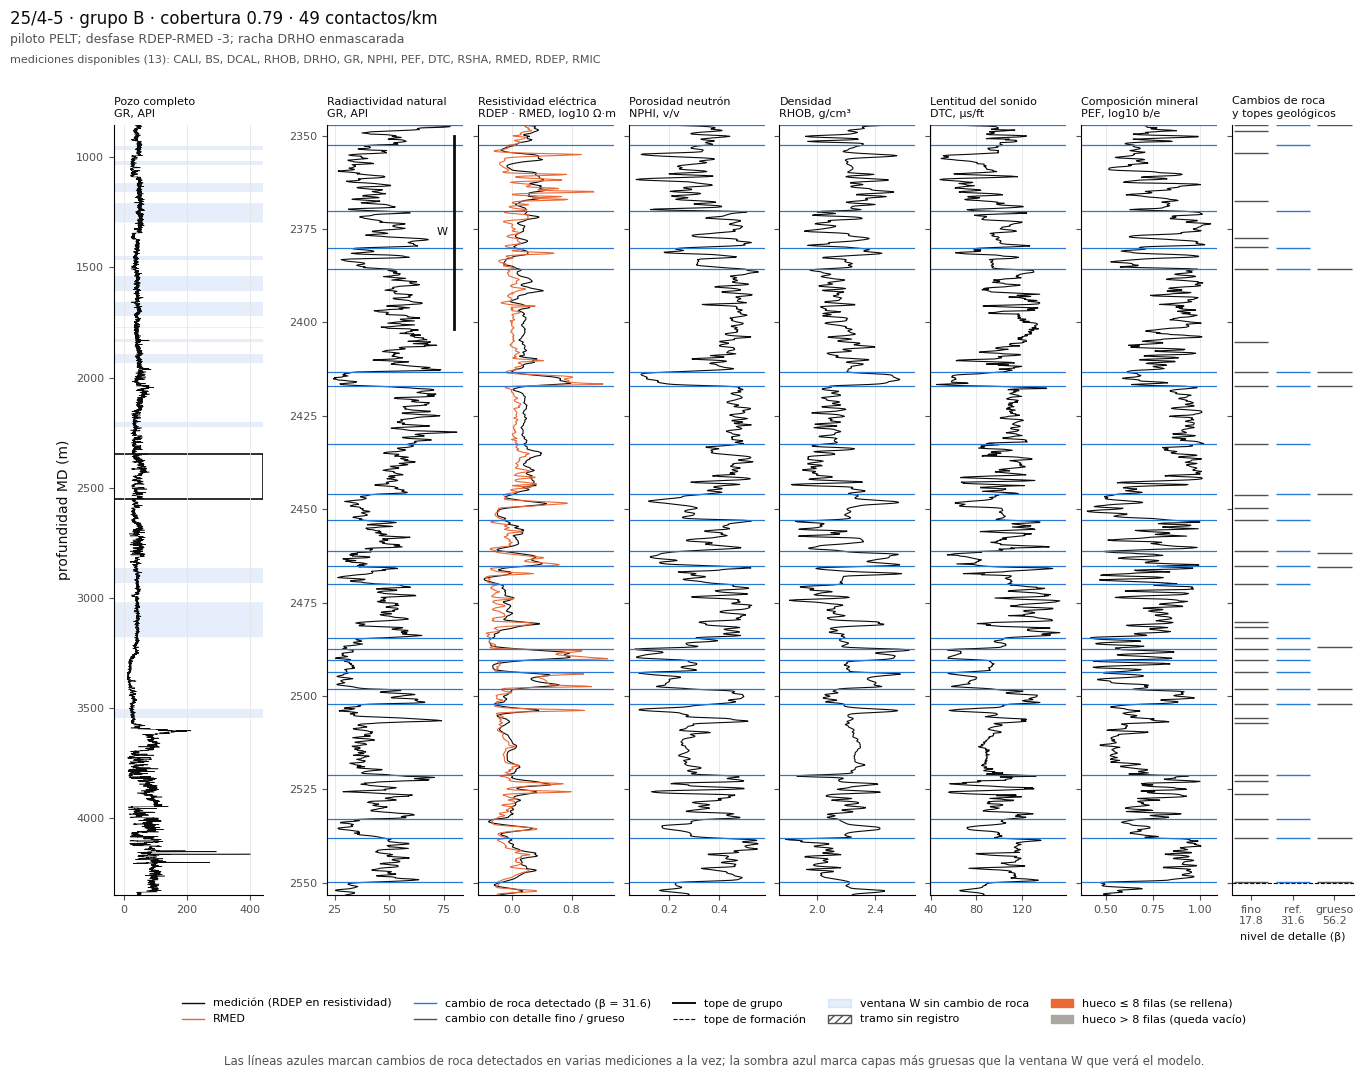

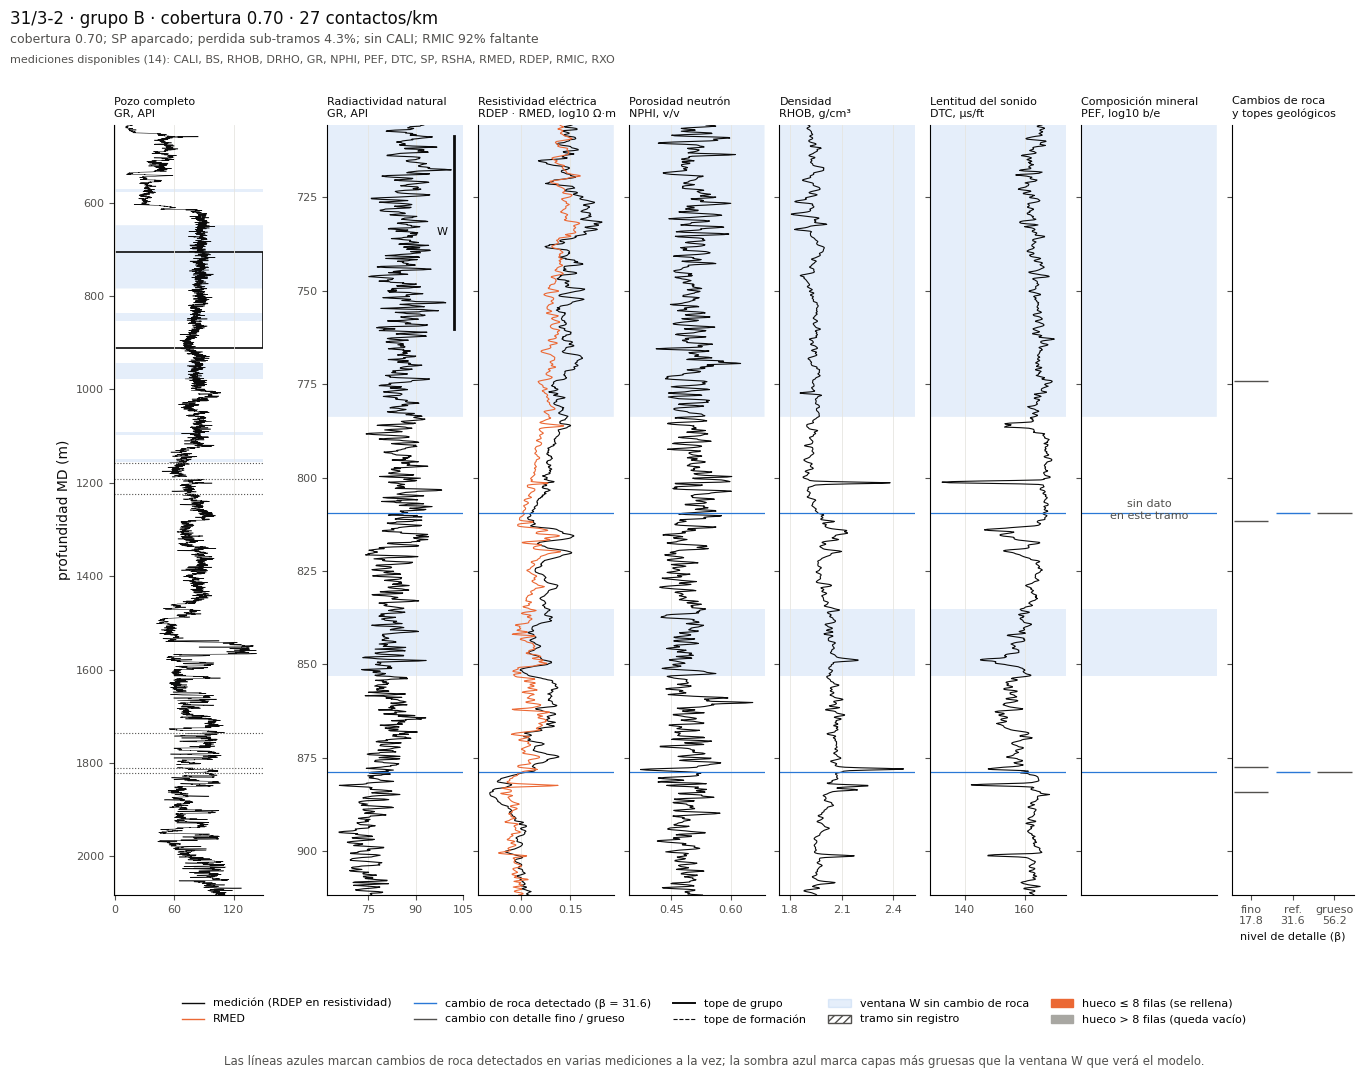

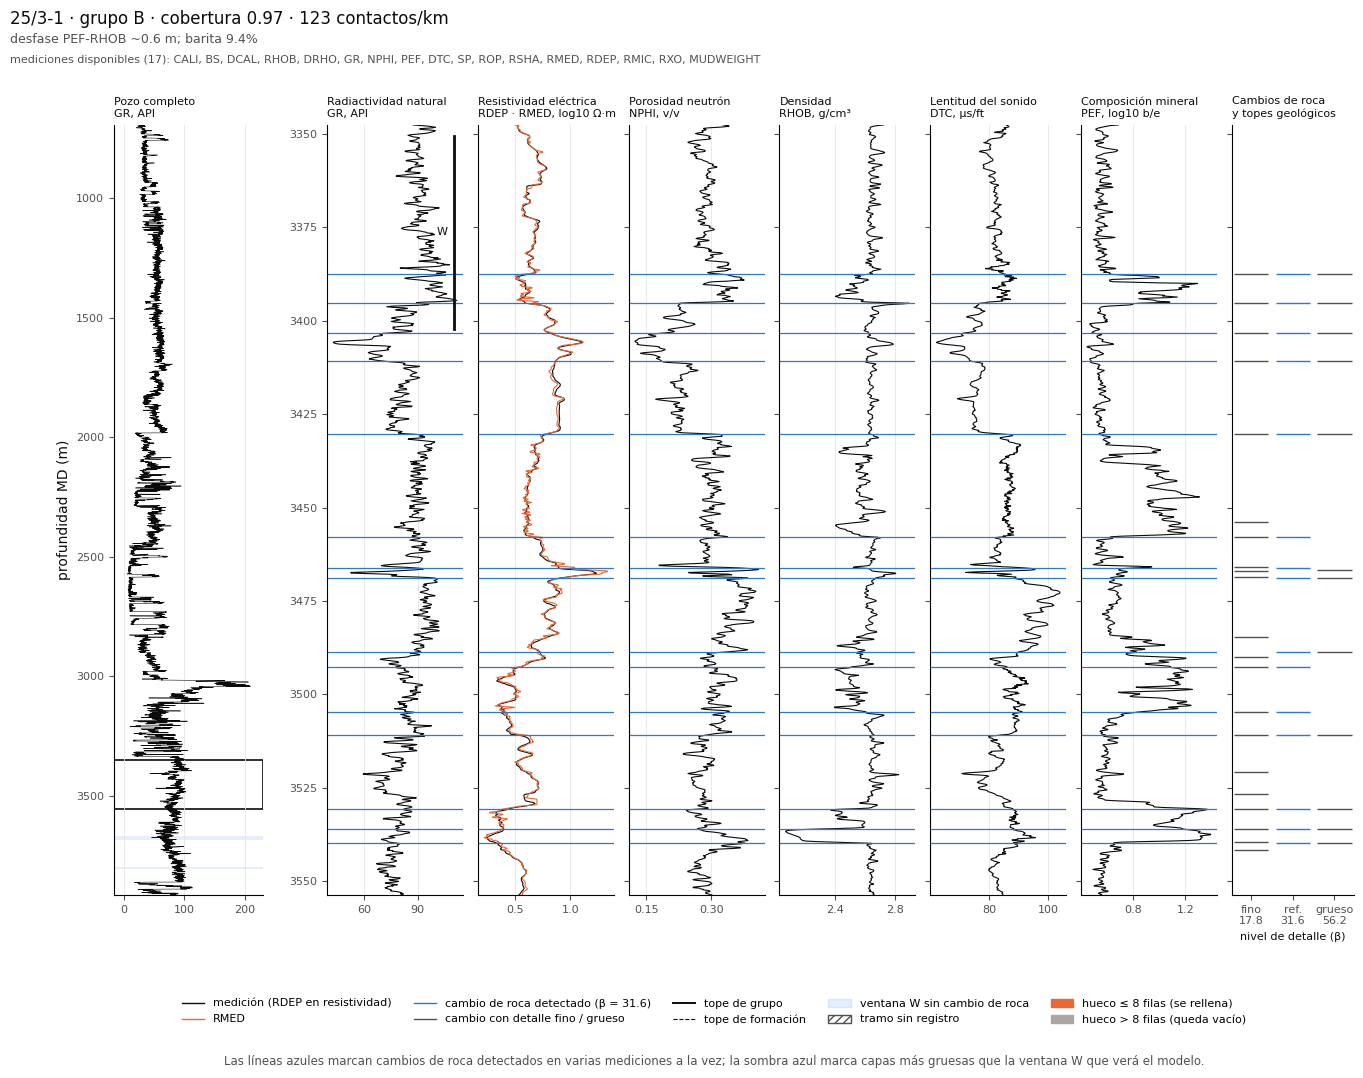

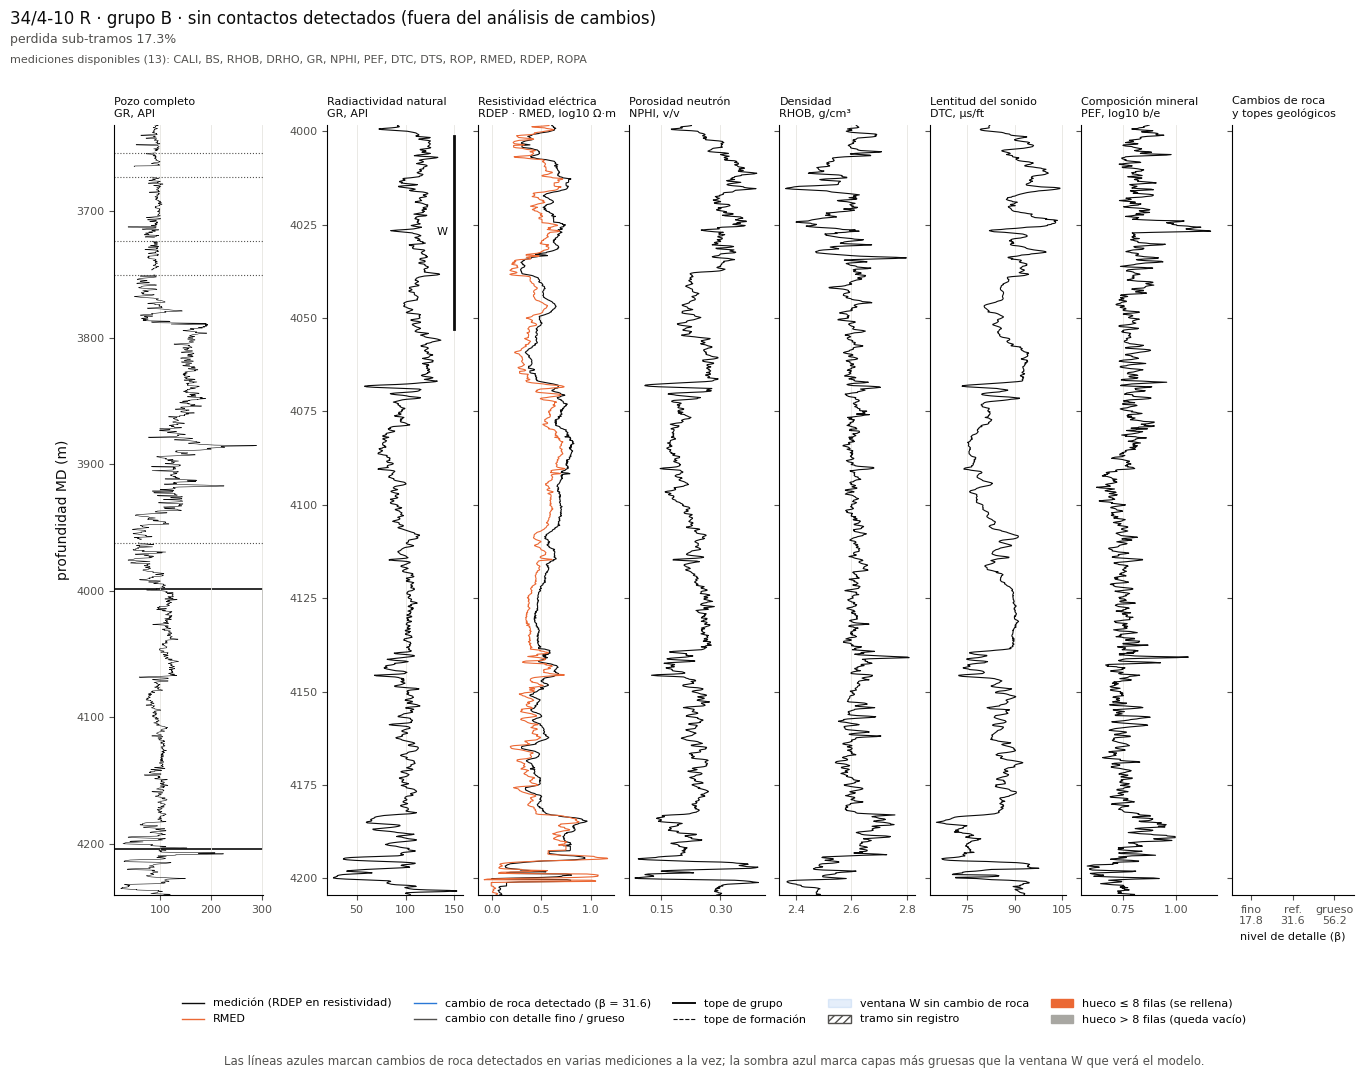

In [ ]:
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

blue, orange, ink, muted, grid = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e0"
long_gray = "#a8a7a2"
log_tracks = [("Radiactividad natural", "GR, API", ["GR"]),
              ("Resistividad eléctrica", "RDEP · RMED, log10 Ω·m", ["RDEP_log10", "RMED_log10"]),
              ("Porosidad neutrón", "NPHI, v/v", ["NPHI"]),
              ("Densidad", "RHOB, g/cm³", ["RHOB"]),
              ("Lentitud del sonido", "DTC, µs/ft", ["DTC"]),
              ("Composición mineral", "PEF, log10 b/e", ["PEF_log10"])]
beta_cols = {"17.8": (0.02, 0.30), "31.6": (0.36, 0.64), "56.2": (0.70, 0.98)}
group_of = {w: "A" for w in group_a.index} | {w: "B" for w in group_b}

def pieces(a, b, breaks):
    # tramos continuos dentro de [a, b]: las lineas no se unen a traves de un salto de profundidad
    cut = [a] + [x for x in breaks if a < x <= b] + [b + 1]
    return [slice(p, q) for p, q in zip(cut[:-1], cut[1:])]

def style(ax):
    ax.grid(axis="x", color=grid, lw=0.6)
    ax.tick_params(colors=muted, labelsize=8)
    ax.spines[["top", "right"]].set_visible(False)

def plot_well(w):
    v = views[w]
    pos, (z0, z1) = v["pos"], v["zoom"]
    unc = lambda p: v["uncovered"][p.start - pos[0]:p.stop - pos[0]]
    gr = pool_sorted["GR"].to_numpy()
    dz = depth[z0:z1 + 1]
    state_z = v["state"].iloc[z0 - pos[0]:z1 - pos[0] + 1]

    fig = plt.figure(figsize=(16, 10))
    gs = fig.add_gridspec(1, 9, width_ratios=[1.1, 0.25] + [1] * 6 + [0.9], wspace=0.12)

    ov = fig.add_subplot(gs[0])
    for p in pieces(pos[0], pos[-1], v["seg_breaks"]):
        ov.plot(gr[p], depth[p], color=ink, lw=0.4)
        ov.fill_betweenx(depth[p], 0, 1, where=unc(p) == 1, transform=ov.get_yaxis_transform(),
                         color=blue, alpha=0.12, lw=0)
    ov.axhspan(depth[z0], depth[z1], facecolor="none", edgecolor=ink, lw=1.2)
    for b in v["seg_breaks"]:
        ov.axhline(depth[b], color=muted, lw=0.8, ls=":")
    ov.set_ylim(depth[pos[-1]], depth[pos[0]])
    ov.set_ylabel("profundidad MD (m)", color=ink)
    ov.set_title("Pozo completo\nGR, API", loc="left", fontsize=8, color=ink)
    style(ov)
    ov.xaxis.set_major_locator(MaxNLocator(3))

    zp = pieces(z0, z1, v["seg_breaks"])
    axes = [fig.add_subplot(gs[i]) for i in range(2, 9)]
    for ax in axes[1:]:
        ax.sharey(axes[0])
        plt.setp(ax.get_yticklabels(), visible=False)
    axes[0].set_ylim(depth[z1], depth[z0])

    for ax in axes:
        for p, q in zip(zp[:-1], zp[1:]):
            ax.axhspan(depth[p.stop - 1], depth[q.start], facecolor="none", edgecolor=muted,
                       hatch="////", lw=0, zorder=0)

    for ax, (name, unit, cols) in zip(axes, log_tracks):
        drawn = False
        for col, color in zip(cols, [ink, orange]):
            x = pool_sorted[col].to_numpy()
            for p in zp:
                if np.isfinite(x[p]).any():
                    ax.plot(x[p], depth[p], color=color, lw=0.8)
                    drawn = True
        if not drawn:
            in_well = any(np.isfinite(pool_sorted[c].to_numpy()[pos]).any() for c in cols)
            ax.text(0.5, 0.5, "sin dato\nen este tramo" if in_well else "no medida\nen este pozo",
                    transform=ax.transAxes, ha="center", va="center", color=muted, fontsize=8)
        for p in zp:
            ax.fill_betweenx(depth[p], 0, 1, where=unc(p) == 1, transform=ax.get_yaxis_transform(),
                             color=blue, alpha=0.12, lw=0)
        for c in v["contacts"]["31.6"]:
            if z0 <= c <= z1:
                ax.axhline(depth[c], color=blue, lw=0.9)
        # huecos interiores marcados solo donde ocurren, en el borde izquierdo de la pista
        base = [c.replace("_log10", "") for c in cols]
        short = (state_z[base] == "hueco_corto").any(axis=1).to_numpy()
        long_ = (state_z[base] == "hueco_largo").any(axis=1).to_numpy()
        ax.fill_betweenx(dz, 0, 0.06, where=long_, transform=ax.get_yaxis_transform(),
                         color=long_gray, lw=0)
        ax.hlines(dz[short], 0, 0.06, transform=ax.get_yaxis_transform(), color=orange, lw=1.5)
        ax.set_title(f"{name}\n{unit}", loc="left", fontsize=8, color=ink)
        style(ax)
        if drawn:
            ax.xaxis.set_major_locator(MaxNLocator(3))
        else:
            ax.set_xticks([])

    y0 = depth[z0] + 3
    axes[0].plot([0.93, 0.93], [y0, y0 + W_ref * 0.152], transform=axes[0].get_yaxis_transform(),
                 color=ink, lw=2)
    axes[0].text(0.89, y0 + W_ref * 0.076, "W", transform=axes[0].get_yaxis_transform(),
                 ha="right", va="center", fontsize=8, color=ink)

    ct = axes[6]
    for name, (x0, x1) in beta_cols.items():
        cs = [c for c in v["contacts"][name] if z0 <= c <= z1]
        ct.hlines(depth[cs], x0, x1, transform=ct.get_yaxis_transform(),
                  color=blue if name == "31.6" else muted, lw=1)
    for col, ls, lw in [("FORMATION", "--", 0.8), ("GROUP", "-", 1.4)]:
        for t in v["tops"][col]:
            if z0 <= t <= z1:
                ct.axhline(depth[t], color=ink, ls=ls, lw=lw)
                if col == "GROUP":
                    ct.text(0.98, depth[t] - 0.8, str(pool_sorted[col].iat[t]).title(),
                            transform=ct.get_yaxis_transform(), ha="right", va="bottom",
                            fontsize=6.5, color=ink)
    ct.set_xlim(0, 1)
    ct.set_xticks([0.16, 0.5, 0.84], ["fino\n17.8", "ref.\n31.6", "grueso\n56.2"])
    ct.set_xlabel("nivel de detalle (β)", color=ink, fontsize=8)
    ct.set_title("Cambios de roca\ny topes geológicos", loc="left", fontsize=8, color=ink)
    style(ct)
    ct.grid(False)

    r = desc.loc[w]
    head = (f"cobertura {r['coverage']:.2f} · {r['contacts_km']:.0f} contactos/km" if r["in_cp"]
            else "sin contactos detectados (fuera del análisis de cambios)")
    note = r["flag"] if isinstance(r["flag"], str) else "pozo típico: medoide de su tercil de suite"
    avail = [c for c in curves if pool_sorted[c].iloc[pos].notna().any()]
    fig.suptitle(f"{w} · grupo {group_of[w]} · {head}", x=0.06, y=0.995, ha="left", fontsize=12, color=ink)
    fig.text(0.06, 0.962, note, fontsize=9, color=muted)
    fig.text(0.06, 0.942, f"mediciones disponibles ({len(avail)}): " + ", ".join(avail), fontsize=8, color=muted)

    handles = [Line2D([], [], color=ink, lw=1, label="medición (RDEP en resistividad)"),
               Line2D([], [], color=orange, lw=1, label="RMED"),
               Line2D([], [], color=blue, lw=1, label="cambio de roca detectado (β = 31.6)"),
               Line2D([], [], color=muted, lw=1, label="cambio con detalle fino / grueso"),
               Line2D([], [], color=ink, lw=1.4, label="tope de grupo"),
               Line2D([], [], color=ink, lw=0.8, ls="--", label="tope de formación"),
               Patch(color=blue, alpha=0.12, label="ventana W sin cambio de roca"),
               Patch(facecolor="none", edgecolor=muted, hatch="////", label="tramo sin registro"),
               Patch(color=orange, label="hueco ≤ 8 filas (se rellena)"),
               Patch(color=long_gray, label="hueco > 8 filas (queda vacío)")]
    fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False, fontsize=8,
               bbox_to_anchor=(0.5, -0.03))
    fig.text(0.5, -0.06, "Las líneas azules marcan cambios de roca detectados en varias mediciones a la vez; "
             "la sombra azul marca capas más gruesas que la ventana W que verá el modelo.",
             ha="center", fontsize=8.5, color=muted)

    name = w.replace("/", "_").replace(" ", "")
    fig.savefig(f"{FIG_DIR}/etapa3_pozo_{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

for w in representative:
    plot_well(w)

In [ ]:
sub = pool_sorted[pool_sorted["WELL"] == "34/4-10 R"]
print(seg_len.loc[seg_len["well"] == "34/4-10 R", "n"].tolist(), joint_runs(sub, core_cols)["n"].max())

[136, 71, 314, 151, 1376, 1832] 1762


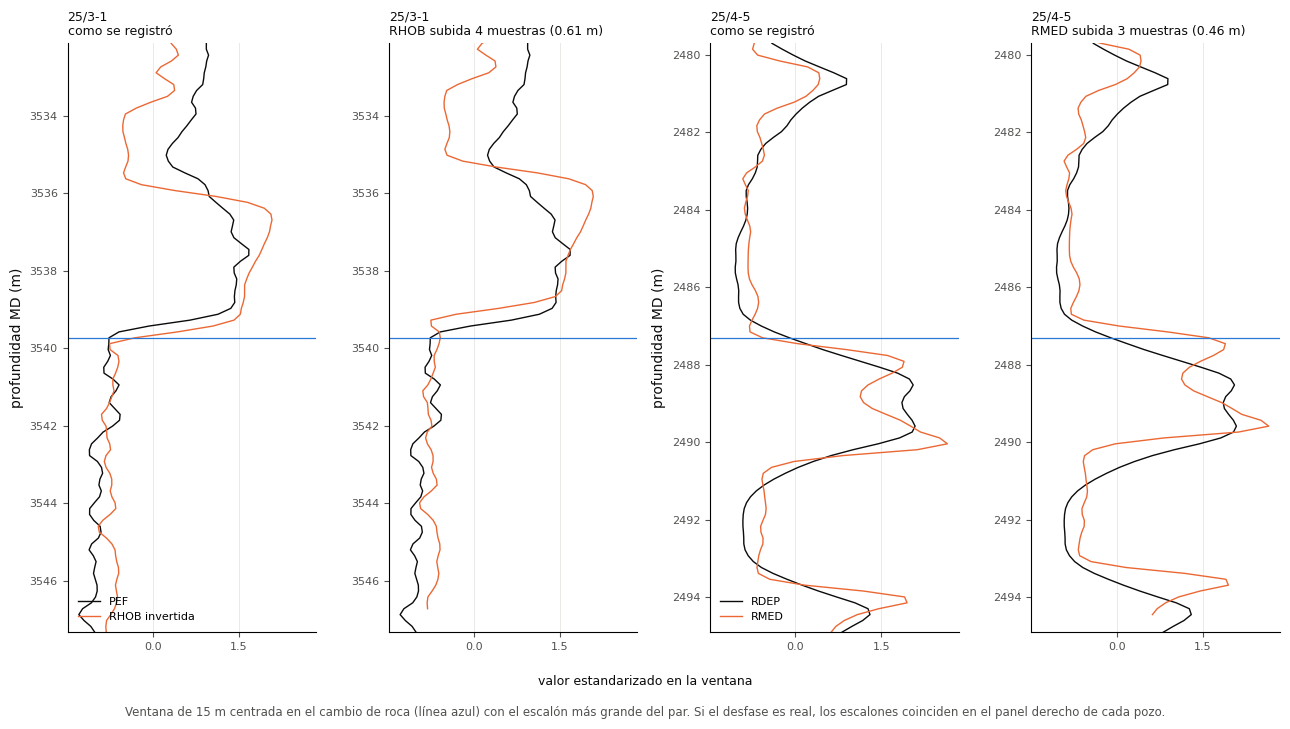

             pair     center_m      jump k_doc k_local    corr_0 corr_k_doc
25/3-1   PEF-RHOB     3539.736  5.423163     4       2 -0.385005  -0.318187
25/4-5  RDEP-RMED  2487.302805  4.831224     3      -1  0.578383   0.333752


In [ ]:
pairs_lag = {"25/3-1": ("PEF_log10", "RHOB", 4), "25/4-5": ("RDEP_log10", "RMED_log10", 3)}
half, step_w = 50, 20

def robust_scale(s):
    return 1.4826 * (s - s.median()).abs().median()

def best_contact(w, x_col, y_col):
    v = views[w]
    z0, z1 = v["zoom"]
    x, y = pool_sorted[x_col].to_numpy(), pool_sorted[y_col].to_numpy()
    sx = robust_scale(pool_sorted[x_col].iloc[v["pos"]])
    sy = robust_scale(pool_sorted[y_col].iloc[v["pos"]])
    seg = pool_sorted["depth_segment"].to_numpy()
    best, size = None, -1.0
    for c in v["contacts"]["31.6"]:
        lo, hi = c - half, c + half + 1
        if lo < z0 or hi > z1 + 1 or seg[lo] != seg[hi - 1]:
            continue
        if not (np.isfinite(x[lo:hi]).all() and np.isfinite(y[lo:hi]).all()):
            continue
        jump = (abs(x[c:c + step_w].mean() - x[c - step_w:c].mean()) / sx
                + abs(y[c:c + step_w].mean() - y[c - step_w:c].mean()) / sy)
        if jump > size:
            best, size = c, jump
    return best, size

def local_lag(x, y, max_k=6):
    dx, dy = np.diff(x), np.diff(y)
    out = {}
    for k in range(-max_k, max_k + 1):
        # k > 0: la curva y registra el evento k muestras mas abajo
        a, b = (dx[:len(dx) - k], dy[k:]) if k >= 0 else (dx[-k:], dy[:len(dy) + k])
        out[k] = np.corrcoef(a, b)[0, 1]
    return pd.Series(out)

fig, axes = plt.subplots(1, 4, figsize=(13, 7), sharex=True)
lag_rows = {}
for (w, (x_col, y_col, k_doc)), pair_axes in zip(pairs_lag.items(), [axes[:2], axes[2:]]):
    c, jump = best_contact(w, x_col, y_col)
    sl = slice(c - half, c + half + 1)
    x, y, d = pool_sorted[x_col].to_numpy()[sl], pool_sorted[y_col].to_numpy()[sl], depth[sl]
    lags = local_lag(x, y)
    sign = np.sign(lags[k_doc])
    zx = (x - x.mean()) / x.std()
    zy = sign * (y - y.mean()) / y.std()
    x_name, y_name = x_col.replace("_log10", ""), y_col.replace("_log10", "")
    y_label = f"{y_name} invertida" if sign < 0 else y_name
    lag_rows[w] = {"pair": f"{x_name}-{y_name}", "center_m": depth[c], "jump": jump, "k_doc": k_doc,
                   "k_local": lags.abs().idxmax(), "corr_0": lags[0], "corr_k_doc": lags[k_doc]}
    for ax, shift in zip(pair_axes, [0, k_doc]):
        ax.plot(zx, d, color=ink, lw=1, label=x_name)
        ax.plot(zy, d - shift * 0.152, color=orange, lw=1, label=y_label)
        ax.axhline(depth[c], color=blue, lw=0.9)
        ax.set_ylim(d[-1], d[0])
        style(ax)
        ax.xaxis.set_major_locator(MaxNLocator(3))
    pair_axes[0].set_title(f"{w}\ncomo se registró", loc="left", fontsize=9, color=ink)
    pair_axes[1].set_title(f"{w}\n{y_name} subida {k_doc} muestras ({k_doc * 0.152:.2f} m)",
                           loc="left", fontsize=9, color=ink)
    pair_axes[0].legend(frameon=False, fontsize=8, loc="lower left")
    pair_axes[0].set_ylabel("profundidad MD (m)", color=ink)

fig.supxlabel("valor estandarizado en la ventana", color=ink, fontsize=9)
fig.text(0.5, -0.03, "Ventana de 15 m centrada en el cambio de roca (línea azul) con el escalón más grande del par. "
         "Si el desfase es real, los escalones coinciden en el panel derecho de cada pozo.",
         ha="center", fontsize=8.5, color=muted)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/etapa3_desfases.png", dpi=200, bbox_inches="tight")
plt.show()

print(pd.DataFrame(lag_rows).T.to_string())

In [ ]:
selection = desc.loc[representative, ["n_curves", "rows", "segments", "in_cp", "coverage",
                                      "contacts_km", "lost_share", "flag"]].copy()
selection.insert(0, "group", [group_of[w] for w in representative])
selection.insert(1, "suite", pop["suite"].reindex(representative))
sel_path = os.path.join(os.path.dirname(FIG_DIR), "etapa3_pozos_representativos.csv")
selection.to_csv(sel_path)

expected = ({"etapa3_acf_formacion.png", "etapa3_espectro_formacion.png", "etapa3_puntos_cambio.png",
             "etapa3_desfases.png"}
            | {f"etapa3_pozo_{w.replace('/', '_').replace(' ', '')}.png" for w in representative})
found = sorted(f for f in os.listdir(FIG_DIR) if f.startswith("etapa3_"))
for f in found:
    p = os.path.join(FIG_DIR, f)
    print(f, round(os.path.getsize(p) / 1024), "KB",
          time.strftime("%Y-%m-%d %H:%M", time.localtime(os.path.getmtime(p))))
print("faltantes:", expected - set(found))
print(os.path.exists(cp_path), os.path.exists(sel_path))
print(selection.round(3).to_string())

etapa3_acf_formacion.png 336 KB 2026-10-23 23:22
etapa3_desfases.png 314 KB 2026-10-23 23:28
etapa3_espectro_formacion.png 418 KB 2026-10-23 23:23
etapa3_pozo_16_4-1.png 666 KB 2026-10-23 23:28
etapa3_pozo_25_3-1.png 660 KB 2026-10-23 23:28
etapa3_pozo_25_4-5.png 763 KB 2026-10-23 23:28
etapa3_pozo_31_3-2.png 696 KB 2026-10-23 23:28
etapa3_pozo_34_10-19.png 639 KB 2026-10-23 23:28
etapa3_pozo_34_4-10R.png 699 KB 2026-10-23 23:28
etapa3_pozo_7_1-1.png 701 KB 2026-10-23 23:28
etapa3_puntos_cambio.png 247 KB 2026-10-23 23:27
faltantes: set()
True True
          group  suite  n_curves   rows  segments  in_cp  coverage  contacts_km  lost_share                                                                               flag
WELL                                                                                                                                                                          
34/10-19      A    0.0        11  12644         1   True     0.932       92.146       0.000    

# 4. Etapa 4 - Diseño del protocolo de evaluación


## 4.1 OE1 - Construir la partición por pozos completos, con agrupamiento por pozo y estratificación por clase

In [2]:
import os, json, hashlib
import numpy as np
import pandas as pd
from google.colab import drive

# la seccion 4 arranca sola, sin depender de la celda 0
drive.mount("/content/drive")
DATA_DIR = "/content/drive/MyDrive/Proyecto_Integrador_II"
curated_path = f"{DATA_DIR}/etapa2_pool_curado.parquet"

CURVES = ["CALI", "BS", "DCAL", "RHOB", "DRHO", "GR", "SGR", "NPHI", "PEF", "DTC",
          "DTS", "SP", "ROP", "RSHA", "RMED", "RDEP", "RMIC", "RXO", "MUDWEIGHT", "ROPA"]

def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

with open(f"{DATA_DIR}/manifiesto_datos.json") as f:
    manifest = json.load(f)
expected = manifest["archivos"]["etapa2_pool_curado.parquet"]

curated_sha = file_sha256(curated_path)
assert curated_sha == expected["sha256"], "el parquet curado no coincide con el manifiesto"

curated = pd.read_parquet(curated_path)
assert curated.shape == (expected["filas"], expected["columnas"])
assert curated["WELL"].nunique() == expected["pozos"]

g = curated.groupby("WELL")
wells = pd.DataFrame({
    "rows": g.size(),
    "n_curves": g[CURVES].count().gt(0).sum(axis=1),
    "x": g["X_LOC"].median(),
    "y": g["Y_LOC"].median(),
    "source": g["source"].first(),
})
wells["quadrant"] = wells.index.str.split("/").str[0]

# misma raiz de nombre = mismo pozo de origen (sidetrack, desviado, reentrada)
root = wells.index.str.replace(r"\s+(A|B|R|S|T\d|ST\d)$", "", regex=True)
shared = pd.Series(root).duplicated(keep=False).to_numpy()
wells["family"] = np.where(shared, root, wells.index)

wells["suite"] = pd.qcut(wells["n_curves"], 3, labels=False, duplicates="drop")

print(curated_sha[:8], curated.shape, wells["rows"].sum())
print(wells["family"].nunique(), wells.loc[shared, ["family", "rows"]].to_dict("index"))
print(wells.groupby("suite")["n_curves"].agg(["min", "max", "size"]))
print(wells["source"].value_counts().to_dict(), wells["quadrant"].nunique())
print(wells[["x", "y"]].isna().sum().to_dict())

Mounted at /content/drive
82f590e8 (1429694, 47) 1429694
117 {'34/5-1 A': {'family': '34/5-1', 'rows': 14592}, '34/5-1 S': {'family': '34/5-1', 'rows': 2273}}
       min  max  size
suite                
0        8   12    41
1       13   14    54
2       15   18    23
{'train': 98, 'leaderboard_test': 10, 'hidden_test': 10} 14
{'x': 0, 'y': 0}


In [3]:
LITHOLOGY = {30000: "Sandstone", 65030: "Sandstone/Shale", 65000: "Shale", 80000: "Marl",
             74000: "Dolomite", 70000: "Limestone", 70032: "Chalk", 88000: "Halite",
             86000: "Anhydrite", 99000: "Tuff", 90000: "Coal", 93000: "Basement"}
MIN_ROWS = 8  # 1.2 m: resolucion vertical de las curvas (G_max, Etapa 3)

lith = curated["FORCE_2020_LITHOFACIES_LITHOLOGY"].map(LITHOLOGY)
assert lith.notna().all()

class_rows = (pd.crosstab(curated["WELL"], lith)
              .reindex(columns=list(LITHOLOGY.values()), fill_value=0))
presence = class_rows >= MIN_ROWS

below = (class_rows > 0) & ~presence
print(pd.DataFrame({"with_rows": (class_rows > 0).sum(), "present": presence.sum()}).T.to_string())
print(class_rows.where(below).stack().astype(int).to_string())

# la familia hereda el tercil de su pozo mas largo
longest = wells.sort_values("rows").groupby("family").tail(1)
family_suite = longest.set_index("family")["suite"]
labels = (presence.groupby(wells["family"]).any()
          .join(pd.get_dummies(family_suite, prefix="suite")))

print(labels.shape, labels.sum().to_dict())
print(labels.loc["34/5-1"].to_dict())

FORCE_2020_LITHOFACIES_LITHOLOGY  Sandstone  Sandstone/Shale  Shale  Marl  Dolomite  Limestone  Chalk  Halite  Anhydrite  Tuff  Coal  Basement
with_rows                               118              117    118    92        47        114     15       4         10    67    63         1
present                                 118              117    118    91        43        113     14       4          9    67    59         1
WELL         FORCE_2020_LITHOFACIES_LITHOLOGY
16/10-5      Chalk                               2
16/11-1 ST3  Dolomite                            6
25/10-9      Coal                                5
25/8-5 S     Dolomite                            4
25/8-7       Coal                                7
26/4-1       Marl                                3
34/10-35     Anhydrite                           5
             Coal                                7
34/2-4       Dolomite                            4
34/5-1 S     Coal                                7
35/11-11     Do

In [4]:
def iterative_stratify(labels, ratios, rng):
    Y = labels.to_numpy(dtype=bool)
    assert Y.any(axis=1).all()
    ratios = np.asarray(ratios, dtype=float)
    need_total = ratios * len(Y)
    need_label = np.outer(ratios, Y.sum(axis=0))
    subset = np.full(len(Y), -1)

    while (subset < 0).any():
        open_rows = subset < 0
        counts = Y[open_rows].sum(axis=0)
        active = np.flatnonzero(counts > 0)
        rarest = active[counts[active] == counts[active].min()]
        label = rng.choice(rarest)
        for i in rng.permutation(np.flatnonzero(open_rows & Y[:, label])):
            best = np.flatnonzero(need_label[:, label] == need_label[:, label].max())
            if len(best) > 1:
                best = best[need_total[best] == need_total[best].max()]
            s = rng.choice(best)
            subset[i] = s
            need_label[s] -= Y[i]
            need_total[s] -= 1
    return pd.Series(subset, index=labels.index)

toy = pd.DataFrame({"Halite": [1, 0, 0, 0, 0], "Chalk": [1, 1, 1, 0, 0], "Shale": [1, 1, 1, 1, 1]},
                   index=["W1", "W2", "W3", "W4", "W5"]).astype(bool)

for seed in range(4):
    out = iterative_stratify(toy, [0.2, 0.8], np.random.default_rng(seed))
    print(seed, out.to_dict())

0 {'W1': 1, 'W2': 1, 'W3': 0, 'W4': 1, 'W5': 1}
1 {'W1': 1, 'W2': 1, 'W3': 0, 'W4': 1, 'W5': 1}
2 {'W1': 1, 'W2': 1, 'W3': 0, 'W4': 1, 'W5': 1}
3 {'W1': 1, 'W2': 0, 'W3': 1, 'W4': 1, 'W5': 1}


In [5]:
import datetime

SEED = 0
TEST_RATIO = 1 / 6
K = 5

rng = np.random.default_rng(SEED)
stage1 = iterative_stratify(labels, [TEST_RATIO, 1 - TEST_RATIO], rng)
stage2 = iterative_stratify(labels[stage1 == 1], [1 / K] * K, rng)

fam_split = pd.DataFrame({"split": np.where(stage1 == 0, "test", "cv")}, index=labels.index)
fam_split["fold"] = stage2.reindex(fam_split.index).astype("Int64")

partition = (wells[["family"]].join(fam_split, on="family")
             .reset_index()[["WELL", "family", "split", "fold"]]
             .sort_values("WELL", ignore_index=True))

part_path = f"{DATA_DIR}/etapa4_particion.csv"

if os.path.exists(part_path):
    # la particion ya existe: se recalcula solo para comparar y nunca se reescribe
    part_sha = file_sha256(part_path)
    assert part_sha == manifest["etapa4_particion"]["sha256"], "la particion no coincide con el manifiesto"
    stored = pd.read_csv(part_path, dtype={"fold": "Int64"})
    print("recalculo identico a la particion guardada:",
          (stored.astype(str).to_numpy() == partition.astype(str).to_numpy()).all())
    partition = stored
else:
    partition.to_csv(part_path, index=False)
    reread = pd.read_csv(part_path, dtype={"fold": "Int64"})
    assert (reread.astype(str).to_numpy() == partition.astype(str).to_numpy()).all()

    part_sha = file_sha256(part_path)
    manifest["etapa4_particion"] = {
        "archivo": "etapa4_particion.csv",
        "fecha": datetime.date.today().isoformat(),
        "sha256": part_sha,
        "semilla": SEED,
        "algoritmo": "estratificacion iterativa multietiqueta (Sechidis et al. 2011), dos pasos",
        "proporciones": {"test": "1/6", "cv": "5/6", "pliegues": K, "validacion_fija": 0},
        "etiquetas": list(labels.columns),
        "min_filas_presencia": MIN_ROWS,
        "grupos": len(labels),
        "pozos": len(partition),
        "datos_origen_sha256": curated_sha,
    }
    with open(f"{DATA_DIR}/manifiesto_datos.json", "w") as f:
        json.dump(manifest, f, indent=2, ensure_ascii=False)

print(part_sha[:8])
print(partition.groupby("split")[["family", "WELL"]].nunique())
print(partition[partition["split"] == "cv"].groupby("fold")[["family", "WELL"]].nunique())

recalculo identico a la particion guardada: True
c55dc4d0
       family  WELL
split              
cv         95    96
test       22    22
      family  WELL
fold              
0         19    20
1         19    19
2         19    19
3         19    19
4         19    19


In [6]:
role = np.select([partition["split"].eq("test"), partition["fold"].eq(0).fillna(False)],
                 ["Prueba", "Validación (pliegue 0)"], "Entrenamiento (pliegues 1–4)")
view = partition.assign(role=role, rows=partition["WELL"].map(wells["rows"]))

order = ["Entrenamiento (pliegues 1–4)", "Validación (pliegue 0)", "Prueba"]
summary = (view.groupby("role")
           .agg(familias=("family", "nunique"), pozos=("WELL", "size"), filas=("rows", "sum"),
                lista=("WELL", lambda s: ", ".join(sorted(s))))
           .reindex(order))
summary.insert(3, "% filas", (summary["filas"] / summary["filas"].sum() * 100).round(1))

colors = {"Entrenamiento (pliegues 1–4)": "#e6e5e0", "Validación (pliegue 0)": "#d4e4f7", "Prueba": "#fbe0d5"}
display(summary.style
        .apply(lambda r: [f"background-color: {colors[r.name]}; color: #0b0b0b"] * len(r), axis=1)
        .format({"filas": "{:,}"})
        .set_properties(subset=["lista"], **{"white-space": "normal", "text-align": "left", "min-width": "500px"}))

display(view[view["split"] == "cv"].groupby("fold")
        .agg(familias=("family", "nunique"), pozos=("WELL", "size"), filas=("rows", "sum")))

,familias,pozos,filas,% filas,lista
role,,,,,
Entrenamiento (pliegues 1–4),76,76,"952,180",66.600000,"15/9-14, 15/9-17, 16/1-6 A, 16/10-2, 16/10-3, 16/10-5, 16/11-1 ST3, 16/2-16, 16/2-6, 16/2-7, 16/4-1, 16/5-3, 16/7-4, 16/7-6, 16/8-1, 17/11-1, 25/10-10, 25/10-9, 25/11-15, 25/11-19 S, 25/11-5, 25/2-13 T4, 25/2-7, 25/3-1, 25/5-1, 25/5-3, 25/6-1, 25/6-3, 25/7-2, 25/9-1, 29/3-1, 29/6-1, 30/3-5 S, 31/2-1, 31/2-19 S, 31/2-7, 31/2-8, 31/3-1, 31/3-2, 31/4-5, 31/5-4 S, 31/6-5, 31/6-8, 32/2-1, 33/5-2, 33/6-3 S, 33/9-1, 34/10-19, 34/10-21, 34/10-33, 34/10-35, 34/11-1, 34/11-2 S, 34/12-1, 34/2-4, 34/3-1 A, 34/3-3 A, 34/4-10 R, 34/6-1 S, 34/7-20, 34/8-1, 34/8-3, 35/11-1, 35/11-11, 35/11-13, 35/11-15 S, 35/11-5, 35/11-6, 35/11-7, 35/12-1, 35/4-1, 35/8-6 S, 35/9-6 S, 35/9-7, 7/1-1, 7/1-2 S"
Validación (pliegue 0),19,20,"234,596",16.400000,"15/9-13, 15/9-23, 16/10-1, 25/11-24, 25/2-14, 25/4-5, 25/6-2, 25/8-7, 30/3-3, 30/6-5, 31/2-10, 31/3-4, 33/9-17, 34/10-16 R, 34/5-1 A, 34/5-1 S, 35/3-7 S, 35/8-4, 35/9-10 S, 36/7-3"
Prueba,22,22,"242,918",17.000000,"15/9-15, 16/1-2, 16/2-11 A, 16/7-5, 17/4-1, 25/5-4, 25/8-5 S, 26/4-1, 31/2-21 S, 31/2-9, 31/3-3, 31/4-10, 34/3-2 S, 34/7-13, 34/7-21, 34/8-7 R, 35/11-10, 35/11-12, 35/6-2 S, 35/9-2, 35/9-5, 35/9-8"


,familias,pozos,filas
fold,,,
0,19,20,234596
1,19,19,233501
2,19,19,223839
3,19,19,259585
4,19,19,235255


In [7]:
part = pd.read_csv(part_path, dtype={"fold": "Int64"})
assert file_sha256(part_path) == manifest["etapa4_particion"]["sha256"]

part["set"] = np.where(part["split"] == "test", "test", "fold" + part["fold"].astype(str))
sets = part.set_index("WELL")["set"]
order = ["test"] + [f"fold{k}" for k in range(K)]

# 1 y 2
print(part["WELL"].is_unique, len(part), part.groupby("family")["set"].nunique().eq(1).all())
row_set = curated["WELL"].map(sets)
print(row_set.notna().all(), row_set.value_counts().reindex(order).to_dict())

# 3: pozos con cada clase (>= 8 filas) y % de las filas de cada clase por conjunto
wells_with = presence.groupby(sets).sum().reindex(order)
print(pd.concat([wells_with, presence.sum().to_frame("total").T]).to_string())
row_share = class_rows.groupby(sets).sum().reindex(order)
print((row_share / row_share.sum() * 100).round(1).to_string())
print({s: list(wells_with.columns[wells_with.loc[s] == 0]) for s in order})

# 4
n_wells = presence.sum()
rare = n_wells.index[n_wells >= 3]
print("Basement fuera de prueba:", wells_with.loc["test", "Basement"] == 0)
print("clases >= 3 pozos con >= 1 en prueba:", (wells_with.loc["test", rare] >= 1).all())
print("clases >= 3 pozos con >= 2 en el pool:", (wells_with.drop("test").sum()[rare] >= 2).all())

# 5
balance = pd.concat([pd.crosstab(sets, wells["suite"]).add_prefix("suite_"),
                     pd.crosstab(sets, wells["source"]),
                     wells.groupby(sets)["rows"].agg(["sum", "median"])], axis=1).reindex(order)
print(balance.to_string())
print(pd.crosstab(sets, wells["quadrant"]).reindex(order).to_string())

# 6: distancia de cada pozo al pozo mas cercano fuera de su conjunto
xy = wells[["x", "y"]].to_numpy() / 1000
D = np.sqrt(((xy[:, None] - xy[None]) ** 2).sum(-1))
s = sets.reindex(wells.index).to_numpy()
nearest = pd.Series(np.where(s[:, None] == s[None, :], np.inf, D).min(axis=1), index=wells.index)
print(nearest.groupby(sets).describe()[["min", "25%", "50%", "max"]].reindex(order).round(1).to_string())

# 7
print(sorted(part.loc[part["split"] == "test", "WELL"]))
rep = pd.read_csv(f"{DATA_DIR}/etapa3_pozos_representativos.csv", index_col=0)
print(rep.assign(set=sets.reindex(rep.index))[["group", "set"]].to_string())

True 118 True
True {'test': 242918, 'fold0': 234596, 'fold1': 233501, 'fold2': 223839, 'fold3': 259585, 'fold4': 235255}
FORCE_2020_LITHOFACIES_LITHOLOGY  Sandstone  Sandstone/Shale  Shale  Marl  Dolomite  Limestone  Chalk  Halite  Anhydrite  Tuff  Coal  Basement
test                                     22               21     22    19         7         21      2       1          1    11    10         0
fold0                                    20               20     20    14         7         19      2       1          1    12    10         0
fold1                                    19               19     19    16         7         19      2       0          2    11    10         0
fold2                                    19               19     19    13         7         18      3       1          2    11     9         0
fold3                                    19               19     19    14         7         18      3       1          1    11    10         0
fold4                

## 4.2 OE2 - Reservar el conjunto de prueba final y establecer la regla de que se toca una sola vez

In [8]:
LABEL_COLS = ["FORCE_2020_LITHOFACIES_LITHOLOGY", "FORCE_2020_LITHOFACIES_CONFIDENCE"]
TEAM_DIR = f"{DATA_DIR}/equipo"
os.makedirs(TEAM_DIR, exist_ok=True)
work_path = f"{TEAM_DIR}/etapa4_pool_trabajo.parquet"
sealed_path = f"{DATA_DIR}/etapa4_prueba_sellada.parquet"

def same_frame(a, b):
    if list(a.columns) != list(b.columns) or len(a) != len(b):
        return False
    for c in a.columns:
        x, y = a[c].reset_index(drop=True), b[c].reset_index(drop=True)
        if not x.isna().equals(y.isna()) or not x.dropna().equals(y.dropna()):
            return False
    return True

test_wells = partition.loc[partition["split"] == "test", "WELL"]
is_test = curated["WELL"].isin(test_wells).to_numpy()

sealed = curated.loc[is_test, ["WELL", "DEPTH_MD"] + LABEL_COLS].reset_index(drop=True)
work = curated.copy()
work[LABEL_COLS] = work[LABEL_COLS].astype("float64")  # el NaN obliga a pasar la etiqueta a decimal
work.loc[is_test, LABEL_COLS] = np.nan

for path, df in [(sealed_path, sealed), (work_path, work)]:
    if os.path.exists(path):
        print(os.path.basename(path), "ya existe, igual al recalculo:", same_frame(pd.read_parquet(path), df))
    else:
        df.to_parquet(path, index=False)
        assert same_frame(pd.read_parquet(path), df)

others = curated.columns.drop(LABEL_COLS)
print(is_test.sum(), work.shape == curated.shape,
      work.loc[is_test, LABEL_COLS].isna().all().all(),
      np.array_equal(work.loc[~is_test, LABEL_COLS].to_numpy(),
                     curated.loc[~is_test, LABEL_COLS].to_numpy(dtype=float), equal_nan=True),
      same_frame(work[others], curated[others]))
print(len(sealed), sealed["WELL"].nunique(), set(sealed["WELL"]) == set(test_wells))

work_sha, sealed_sha = file_sha256(work_path), file_sha256(sealed_path)
if "etapa4_prueba" in manifest:
    old = manifest["etapa4_prueba"]
    assert (old["trabajo"]["sha256"], old["sellado"]["sha256"]) == (work_sha, sealed_sha)
else:
    manifest["etapa4_prueba"] = {
        "fecha": datetime.date.today().isoformat(),
        "regla": "claude/etapa4-objetivo2-prueba.md",
        "particion_sha256": part_sha,
        "datos_origen_sha256": curated_sha,
        "trabajo": {"archivo": "equipo/etapa4_pool_trabajo.parquet", "sha256": work_sha,
                    "filas": len(work), "filas_sin_etiqueta": int(is_test.sum())},
        "sellado": {"archivo": "etapa4_prueba_sellada.parquet", "sha256": sealed_sha,
                    "filas": len(sealed), "pozos": int(sealed["WELL"].nunique())},
    }
    with open(f"{DATA_DIR}/manifiesto_datos.json", "w") as f:
        json.dump(manifest, f, indent=2, ensure_ascii=False)

print(work_sha[:8], sealed_sha[:8])

etapa4_prueba_sellada.parquet ya existe, igual al recalculo: True
etapa4_pool_trabajo.parquet ya existe, igual al recalculo: True
242918 True True True True
242918 22 True
45a0ed6f 1904defd


In [9]:
import shutil

team_part = f"{TEAM_DIR}/etapa4_particion.csv"
if not os.path.exists(team_part):
    shutil.copyfile(part_path, team_part)
assert file_sha256(team_part) == manifest["etapa4_particion"]["sha256"]

# se actualiza sin borrar claves agregadas despues (huella de la matriz de penalizacion, seccion 4.3)
team_manifest_path = f"{TEAM_DIR}/manifiesto_equipo.json"
team_manifest = {}
if os.path.exists(team_manifest_path):
    with open(team_manifest_path) as f:
        team_manifest = json.load(f)
team_manifest.update({"origen": "manifiesto_datos.json del custodio",
                      "particion_sha256": manifest["etapa4_particion"]["sha256"],
                      "trabajo_sha256": manifest["etapa4_prueba"]["trabajo"]["sha256"]})
with open(team_manifest_path, "w") as f:
    json.dump(team_manifest, f, indent=2)
print(sorted(os.listdir(TEAM_DIR)))

['acceso_datos.py', 'etapa4_particion.csv', 'etapa4_pool_trabajo.parquet', 'manifiesto_equipo.json', 'metricas.py', 'penalty_matrix.npy', 'revision_notebooks.py']


In [10]:
%%writefile /content/drive/MyDrive/Proyecto_Integrador_II/equipo/acceso_datos.py
import hashlib, json, os
import numpy as np
import pandas as pd

TEAM_DIR = os.path.dirname(os.path.abspath(__file__))
LITH = "FORCE_2020_LITHOFACIES_LITHOLOGY"
CONF = "FORCE_2020_LITHOFACIES_CONFIDENCE"


def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def load_partition():
    with open(f"{TEAM_DIR}/manifiesto_equipo.json") as f:
        expected = json.load(f)
    path = f"{TEAM_DIR}/etapa4_particion.csv"
    assert file_sha256(path) == expected["particion_sha256"], "la particion no coincide con el manifiesto"
    part = pd.read_csv(path, dtype={"fold": "Int64"})
    part["set"] = np.where(part["split"] == "test", "test", "fold" + part["fold"].astype(str))
    return part


def load_split(sets, labels=True):
    if labels and "test" in sets:
        raise ValueError("la etiqueta de prueba solo se lee en evaluate_test; use labels=False")
    with open(f"{TEAM_DIR}/manifiesto_equipo.json") as f:
        expected = json.load(f)
    path = f"{TEAM_DIR}/etapa4_pool_trabajo.parquet"
    assert file_sha256(path) == expected["trabajo_sha256"], "el archivo de trabajo no coincide con el manifiesto"

    part = load_partition()
    wells = part.loc[part["set"].isin(sets), "WELL"].tolist()
    df = pd.read_parquet(path, filters=[("WELL", "in", wells)])
    if labels:
        df[LITH] = df[LITH].astype("int64")
    else:
        df = df.drop(columns=[LITH, CONF])
    return df.reset_index(drop=True)

Overwriting /content/drive/MyDrive/Proyecto_Integrador_II/equipo/acceso_datos.py


In [11]:
import sys
sys.dont_write_bytecode = True  # evita la carpeta __pycache__ en Drive
sys.path.insert(0, TEAM_DIR)
from acceso_datos import load_split

lith_col = LABEL_COLS[0]
pool_df = load_split([f"fold{k}" for k in range(K)])
print(pool_df["WELL"].nunique(), len(pool_df), pool_df[lith_col].dtype,
      (pool_df[lith_col].to_numpy() == curated.loc[~is_test, lith_col].to_numpy()).all())

test_x = load_split(["test"], labels=False)
print(test_x["WELL"].nunique(), len(test_x), set(LABEL_COLS) & set(test_x.columns))
print(load_split([f"fold{k}" for k in range(1, K)])["WELL"].nunique())

try:
    load_split(["test"])
    print("ERROR: devolvio la etiqueta de prueba")
except ValueError as e:
    print("bloqueado:", e)

del pool_df, test_x

96 1186776 int64 True
22 242918 set()
76
bloqueado: la etiqueta de prueba solo se lee en evaluate_test; use labels=False


In [12]:
%%writefile /content/drive/MyDrive/Proyecto_Integrador_II/equipo/revision_notebooks.py
import json

SENSITIVE = ["etapa2_pool_curado", "etapa1_pool_consolidado", "etapa4_prueba_sellada",
             "curated_path", "sealed_path"]


def scan_notebook(path, after_heading=None):
    with open(path) as f:
        cells = json.load(f)["cells"]
    active = after_heading is None
    hits = []
    for i, cell in enumerate(cells):
        src = "".join(cell["source"])
        if not active:
            active = cell["cell_type"] == "markdown" and src.lstrip().startswith(after_heading)
            continue
        if cell["cell_type"] != "code" or "def evaluate_test" in src:
            continue
        hits += [(i, name) for name in SENSITIVE if name in src]
    return hits

Overwriting /content/drive/MyDrive/Proyecto_Integrador_II/equipo/revision_notebooks.py


In [13]:
from revision_notebooks import scan_notebook

# lee la copia guardada en Drive: guardar el notebook (Ctrl+S) antes de ejecutar
NB_PATH = f"{DATA_DIR}/Proyecto_Integrador_II.ipynb"
print(scan_notebook(NB_PATH, "# 5."))
print(sorted({i for i, _ in scan_notebook(NB_PATH)}))

[]
[108, 152, 159]


In [14]:
import gc

label_vars = ["curated", "lith", "class_rows", "presence", "labels",
              "row_set", "row_share", "wells_with", "work", "sealed"]
for name in label_vars:
    globals().pop(name, None)
gc.collect()
print([name for name in label_vars if name in globals()])

[]


In [15]:
%%writefile /content/drive/MyDrive/Proyecto_Integrador_II/evaluacion_prueba.py
import datetime, json, os, sys
import pandas as pd

DATA_DIR = os.path.dirname(os.path.abspath(__file__))
sys.path.insert(0, f"{DATA_DIR}/equipo")
from acceso_datos import file_sha256, load_split, LITH
from metricas import strata

KEYS = ["WELL", "DEPTH_MD"]


def evaluate_test(pred_path, metric_fn, models, author, code_version, reason,
                  dry_run=True, reentry=False, registry_dir=DATA_DIR):
    # la huella de las predicciones se fija antes de leer cualquier etiqueta
    pred_sha = file_sha256(pred_path)
    with open(f"{DATA_DIR}/manifiesto_datos.json") as f:
        manifest = json.load(f)
    sealed = manifest["etapa4_prueba"]["sellado"]

    if dry_run:
        registry = f"{registry_dir}/registro_ensayo.json"
        eval_set = ["fold0"]
        truth = load_split(eval_set)[KEYS + [LITH]]
    else:
        registry = f"{registry_dir}/registro_prueba.json"
        if os.path.exists(registry) and not reentry:
            raise RuntimeError("la prueba ya se uso; una re-evaluacion exige reentry=True y motivo")
        eval_set = ["test"]
        sealed_path = f"{DATA_DIR}/{sealed['archivo']}"
        assert file_sha256(sealed_path) == sealed["sha256"], "el archivo sellado no coincide con el manifiesto"
        truth = pd.read_parquet(sealed_path, columns=KEYS + [LITH])

    preds = pd.read_parquet(pred_path)
    assert set(preds.columns) == set(KEYS) | set(models), "columnas de prediccion distintas de los modelos declarados"
    assert not preds.duplicated(KEYS).any()
    merged = truth.merge(preds, on=KEYS, how="outer", indicator=True)
    assert (merged["_merge"] == "both").all(), "las filas de predicciones y verdad no coinciden"

    # el estrato de posicion sale de profundidad y sub-tramo, sin etiqueta
    pos = load_split(eval_set, labels=False)[KEYS + ["depth_segment"]]
    pos["stratum"] = strata(pos["WELL"], pos["DEPTH_MD"], pos["depth_segment"])
    merged = merged.drop(columns="_merge").merge(pos[KEYS + ["stratum"]], on=KEYS, how="left")
    assert merged["stratum"].notna().all()

    metrics = {m: metric_fn(merged[["WELL", "stratum"]].assign(y_true=merged[LITH], y_pred=merged[m]))
               for m in models}

    entries = []
    if os.path.exists(registry):
        with open(registry) as f:
            entries = json.load(f)
    entries.append({
        "fecha": datetime.datetime.now().isoformat(timespec="seconds"),
        "modo": "ensayo" if dry_run else "prueba",
        "autor": author,
        "version_codigo": code_version,
        "motivo": reason,
        "modelos": models,
        "huellas": {"particion": manifest["etapa4_particion"]["sha256"],
                    "trabajo": manifest["etapa4_prueba"]["trabajo"]["sha256"],
                    "sellado": sealed["sha256"],
                    "predicciones": pred_sha},
        "filas": len(merged),
        "pozos": int(merged["WELL"].nunique()),
        "metricas": metrics,
    })
    with open(registry, "w") as f:
        json.dump(entries, f, indent=2, ensure_ascii=False, allow_nan=False)
    return metrics

Overwriting /content/drive/MyDrive/Proyecto_Integrador_II/evaluacion_prueba.py


In [16]:
sys.path.insert(0, DATA_DIR)
from evaluacion_prueba import evaluate_test

TRIAL_DIR = f"{DATA_DIR}/ensayos"
os.makedirs(TRIAL_DIR, exist_ok=True)

train_mode = load_split([f"fold{k}" for k in range(1, K)])[lith_col].mode()[0]
keys = load_split(["fold0"], labels=False)[["WELL", "DEPTH_MD"]]
pred_path = f"{TRIAL_DIR}/pred_ensayo_pliegue0.parquet"
keys.assign(mayoritaria=train_mode).to_parquet(pred_path, index=False)

def provisional_accuracy(df):
    return {"exactitud_provisional": float((df["y_true"] == df["y_pred"]).mean())}

trial = evaluate_test(pred_path, provisional_accuracy, {"mayoritaria": "clase mas frecuente, pliegues 1-4"},
                      author="Juan Jose Morales", code_version="notebook sin git, 2026-10-15",
                      reason="ensayo del mecanismo, objetivo 2")
print(train_mode, trial)

65000 {'mayoritaria': {'exactitud_provisional': 0.6586301556718784}}


In [17]:
import tempfile

bad_path = f"{TRIAL_DIR}/pred_ensayo_incompleta.parquet"
pd.read_parquet(pred_path).iloc[:-1].to_parquet(bad_path, index=False)
try:
    evaluate_test(bad_path, provisional_accuracy, {"mayoritaria": "x"}, "control", "control", "fila faltante")
    print("ERROR: acepto predicciones incompletas")
except AssertionError as e:
    print("fila faltante:", e)

fake_dir = tempfile.mkdtemp()
with open(f"{fake_dir}/registro_prueba.json", "w") as f:
    json.dump([{"juguete": True}], f)
try:
    evaluate_test(pred_path, provisional_accuracy, {"mayoritaria": "x"}, "control", "control", "registro ocupado",
                  dry_run=False, registry_dir=fake_dir)
    print("ERROR: no respeto el registro ocupado")
except RuntimeError as e:
    print("registro ocupado:", e)

with open(f"{DATA_DIR}/registro_ensayo.json") as f:
    print(len(json.load(f)), os.path.exists(f"{DATA_DIR}/registro_prueba.json"))

fila faltante: las filas de predicciones y verdad no coinciden
registro ocupado: la prueba ya se uso; una re-evaluacion exige reentry=True y motivo
4 False


## 4.3 OE3 - Definir las métricas, incluyendo la matriz de penalización entre clases de roca y las métricas por clase

In [18]:
import requests

PEN_URL = ("https://raw.githubusercontent.com/bolgebrygg/Force-2020-Machine-Learning-competition/"
           "master/lithology_competition/data/penalty_matrix.npy")
PEN_BLOB = "b96178eb8d3287c36061f595f63ea454cb9ee891"  # sha1 git del archivo en el repositorio
pen_path = f"{TEAM_DIR}/penalty_matrix.npy"

def git_blob_sha1(raw):
    return hashlib.sha1(b"blob %d\0" % len(raw) + raw).hexdigest()

if not os.path.exists(pen_path):
    raw = requests.get(PEN_URL, timeout=60).content
    assert git_blob_sha1(raw) == PEN_BLOB, "la descarga no coincide con el repositorio"
    with open(pen_path, "wb") as f:
        f.write(raw)

with open(pen_path, "rb") as f:
    raw = f.read()
assert git_blob_sha1(raw) == PEN_BLOB
pen_sha = file_sha256(pen_path)

team_manifest_path = f"{TEAM_DIR}/manifiesto_equipo.json"
with open(team_manifest_path) as f:
    team_manifest = json.load(f)
team_manifest["penalizacion_sha256"] = pen_sha
with open(team_manifest_path, "w") as f:
    json.dump(team_manifest, f, indent=2)

with open(f"{DATA_DIR}/manifiesto_datos.json") as f:
    manifest = json.load(f)
in_stage1 = PEN_BLOB in json.dumps({k: v for k, v in manifest.items() if k != "etapa4_metricas"})
if "etapa4_metricas" in manifest:
    assert manifest["etapa4_metricas"]["sha256"] == pen_sha
else:
    manifest["etapa4_metricas"] = {
        "fecha": datetime.date.today().isoformat(),
        "regla": "claude/etapa4-objetivo3-metricas.md",
        "penalizacion": {"archivo": "equipo/penalty_matrix.npy", "fuente": PEN_URL,
                         "blob_git": PEN_BLOB},
    }
    manifest["etapa4_metricas"]["sha256"] = pen_sha
    with open(f"{DATA_DIR}/manifiesto_datos.json", "w") as f:
        json.dump(manifest, f, indent=2, ensure_ascii=False)

print(len(raw), pen_sha[:8], in_stage1)

1280 c312481a True


In [19]:
%%writefile /content/drive/MyDrive/Proyecto_Integrador_II/equipo/metricas.py
import json, os
import numpy as np
import pandas as pd
from acceso_datos import file_sha256

TEAM_DIR = os.path.dirname(os.path.abspath(__file__))

# orden de filas y columnas de penalty_matrix.npy (lithology_numbers del starter notebook)
CODES = [30000, 65030, 65000, 80000, 74000, 70000, 70032, 88000, 86000, 99000, 90000, 93000]
NAMES = ["Sandstone", "Sandstone/Shale", "Shale", "Marl", "Dolomite", "Limestone",
         "Chalk", "Halite", "Anhydrite", "Tuff", "Coal", "Basement"]
INDEX = {c: i for i, c in enumerate(CODES)}

MIN_ROWS = 8   # presencia de una clase en un pozo (misma definicion de la particion)
MIN_WELLS = 2  # pozos con la clase para que entre a los promedios por clase
N_BOOT = 2000


def load_penalty():
    with open(f"{TEAM_DIR}/manifiesto_equipo.json") as f:
        expected = json.load(f)["penalizacion_sha256"]
    path = f"{TEAM_DIR}/penalty_matrix.npy"
    assert file_sha256(path) == expected, "la matriz de penalizacion no coincide con el manifiesto"
    return np.load(path)


PENALTY = load_penalty()


def to_index(codes):
    idx = pd.Series(np.asarray(codes)).map(INDEX)
    assert idx.notna().all(), "codigo de litologia fuera de las 12 clases"
    return idx.to_numpy(dtype=int)


def row_penalty(y_true, y_pred):
    return PENALTY[to_index(y_true), to_index(y_pred)]


def penalty_score(y_true, y_pred):
    return -float(row_penalty(y_true, y_pred).mean())


def well_scores(wells, y_true, y_pred):
    cost = pd.Series(row_penalty(y_true, y_pred), index=np.asarray(wells))
    return -cost.groupby(level=0).mean()


def confusion(y_true, y_pred):
    cm = np.zeros((len(CODES), len(CODES)), dtype=int)
    np.add.at(cm, (to_index(y_true), to_index(y_pred)), 1)
    return cm


def well_confusions(wells, y_true, y_pred):
    wells = np.asarray(wells)
    names = np.unique(wells)
    stack = np.zeros((len(names), len(CODES), len(CODES)), dtype=int)
    np.add.at(stack, (np.searchsorted(names, wells), to_index(y_true), to_index(y_pred)), 1)
    return names, stack


def rates(cm):
    tp = np.diag(cm)
    real, predicted = cm.sum(axis=1), cm.sum(axis=0)
    # precision 0 si la clase existe y nunca se predice (zero_division=0, como en el curso)
    precision = np.divide(tp, predicted, out=np.where(real > 0, 0.0, np.nan), where=predicted > 0)
    recall = np.divide(tp, real, out=np.full(len(CODES), np.nan), where=real > 0)
    denom = precision + recall
    f1 = np.divide(2 * precision * recall, denom, out=np.where(real > 0, 0.0, np.nan), where=denom > 0)
    return precision, recall, f1


def class_metrics(wells, y_true, y_pred):
    cm = confusion(y_true, y_pred)
    precision, recall, f1 = rates(cm)
    real, predicted = cm.sum(axis=1), cm.sum(axis=0)
    rows_by_well = (pd.crosstab(np.asarray(wells), np.asarray(y_true))
                    .reindex(columns=CODES, fill_value=0))
    n_wells = (rows_by_well >= MIN_ROWS).sum().to_numpy()
    return pd.DataFrame({"precision": precision, "recall": recall, "f1": f1,
                         "filas": real, "pozos": n_wells, "predichas": predicted,
                         "falsos_positivos": predicted - np.diag(cm),
                         "evaluable": n_wells >= MIN_WELLS}, index=NAMES)


def class_summary(table, y_true, y_pred):
    ev = table[table["evaluable"]]
    return {"f1_macro": float(ev["f1"].mean()),
            "exactitud_balanceada": float(ev["recall"].mean()),
            "exactitud": float((np.asarray(y_true) == np.asarray(y_pred)).mean()),
            "clases_evaluables": list(ev.index)}


def resample_index(n_wells, n_boot=N_BOOT, seed=0):
    return np.random.default_rng(seed).integers(0, n_wells, (n_boot, n_wells))


def percentile_ci(values, level=0.95):
    lo, hi = np.nanquantile(values, [(1 - level) / 2, (1 + level) / 2])
    return [float(lo), float(hi)]


def mean_ci(per_well, n_boot=N_BOOT, seed=0):
    v = np.asarray(per_well, dtype=float)
    return percentile_ci(v[resample_index(len(v), n_boot, seed)].mean(axis=1))


def macro_f1_ci(stack, evaluable, n_boot=N_BOOT, seed=0):
    # las clases evaluables quedan fijas; si una falta en una replica, se omite en esa replica
    values = [np.nanmean(rates(stack[idx].sum(axis=0))[2][evaluable])
              for idx in resample_index(len(stack), n_boot, seed)]
    return percentile_ci(values)


def paired_difference(scores_a, scores_b, n_boot=N_BOOT, seed=0):
    assert set(scores_a.index) == set(scores_b.index), "los modelos no se evaluaron en los mismos pozos"
    d = scores_a - scores_b.reindex(scores_a.index)
    ci = mean_ci(d, n_boot, seed)
    return {"diferencia": float(d.mean()), "ic95": ci, "real": not (ci[0] <= 0 <= ci[1]),
            "gana_a": int((d > 0).sum()), "gana_b": int((d < 0).sum()), "empates": int((d == 0).sum())}


W_REF = 339  # ventana de referencia de la Etapa 3, en filas


def strata(wells, depth, segment, w=W_REF):
    h = w // 2
    d = pd.DataFrame({"well": np.asarray(wells), "seg": np.asarray(segment), "depth": np.asarray(depth)})
    d = d.sort_values(["well", "seg", "depth"])
    g = d.groupby(["well", "seg"], sort=False)
    pos, n = g.cumcount(), g["depth"].transform("size")
    label = np.where(n < w, "sin_ventana", np.where((pos < h) | (pos >= n - h), "borde", "interior"))
    return pd.Series(label, index=d.index).sort_index().to_numpy()


def json_safe(x):
    if isinstance(x, dict):
        return {str(k): json_safe(v) for k, v in x.items()}
    if isinstance(x, (list, tuple, np.ndarray)):
        return [json_safe(v) for v in x]
    if isinstance(x, (bool, np.bool_)):
        return bool(x)
    if isinstance(x, np.integer):
        return int(x)
    if isinstance(x, (float, np.floating)):
        return None if np.isnan(x) else float(x)
    return x


def evaluate(df, n_boot=N_BOOT, seed=0):
    wells, y_true, y_pred = df["WELL"], df["y_true"], df["y_pred"]
    scores = well_scores(wells, y_true, y_pred)
    table = class_metrics(wells, y_true, y_pred)
    summary = class_summary(table, y_true, y_pred)
    _, stack = well_confusions(wells, y_true, y_pred)

    by_stratum = {}
    for name, part in df.groupby("stratum"):
        s = well_scores(part["WELL"], part["y_true"], part["y_pred"])
        by_stratum[name] = {"filas": len(part), "pozos": len(s), "score_pozo": s.mean(),
                            "score_filas": penalty_score(part["y_true"], part["y_pred"]),
                            "exactitud": (part["y_true"] == part["y_pred"]).mean()}

    return json_safe({
        "filas": len(df),
        "principal": {"score_pozo": scores.mean(), "ic95": mean_ci(scores, n_boot, seed), "pozos": len(scores)},
        "complementarias": {"score_filas": penalty_score(y_true, y_pred),
                            "f1_macro_ic95": macro_f1_ci(stack, table["evaluable"].to_numpy(), n_boot, seed),
                            **summary},
        "por_clase": table.to_dict("index"),
        "confusion": stack.sum(axis=0),
        "por_pozo": scores.to_dict(),
        "por_estrato": by_stratum,
    })


def mlflow_scalars(result, prefix="val_"):
    out = {"score_pozo": result["principal"]["score_pozo"]}
    comp = result["complementarias"]
    out.update({k: comp[k] for k in ["score_filas", "f1_macro", "exactitud_balanceada", "exactitud"]})
    out.update({"f1_" + name.replace("/", "_"): row["f1"]
                for name, row in result["por_clase"].items() if row["evaluable"]})
    return {prefix + k: v for k, v in out.items()}

Overwriting /content/drive/MyDrive/Proyecto_Integrador_II/equipo/metricas.py


In [20]:
import importlib
import metricas
importlib.reload(metricas)
from metricas import penalty_score, PENALTY, CODES

off_diag = PENALTY[~np.eye(12, dtype=bool)]
print(PENALTY.shape, np.allclose(PENALTY, PENALTY.T), np.diag(PENALTY).max(), off_diag.min(), off_diag.max())

y_true = [65000, 65000, 30000, 70032, 88000]
near = [65000, 80000, 65030, 70000, 86000]
far = [65000, 88000, 93000, 86000, 90000]
print(penalty_score(y_true, near), penalty_score(y_true, far))

A = PENALTY
def score(y_true, y_pred):
    S = 0.0
    y_true = y_true.astype(int)
    y_pred = y_pred.astype(int)
    for i in range(0, y_true.shape[0]):
        S -= A[y_true[i], y_pred[i]]
    return S/y_true.shape[0]

rng = np.random.default_rng(1)
ti, pi = rng.integers(0, 12, 10000), rng.integers(0, 12, 10000)
codes = np.array(CODES)
mine = penalty_score(codes[ti], codes[pi])
print(abs(mine - score(ti, pi)) < 1e-12, abs(penalty_score(codes[pi], codes[ti]) - score(pi, ti)) < 1e-12, round(mine, 4))

try:
    penalty_score([65000], [12345])
    print("ERROR: acepto un codigo invalido")
except AssertionError as e:
    print("rechazado:", e)

(12, 12) True 0.0 1.375 4.0
-1.625 -2.95
True True -3.0971
rechazado: codigo de litologia fuera de las 12 clases


In [21]:
importlib.reload(metricas)
from metricas import penalty_score, well_scores

s = well_scores(["A"] * 4 + ["B"], [65000] * 5, [65000, 65000, 65000, 80000, 88000])
print(s.to_dict(), s.mean(), penalty_score([65000] * 5, [65000, 65000, 65000, 80000, 88000]))

rng = np.random.default_rng(2)
lengths = {"W1": 4000, "W2": 500, "W3": 50}
toy_wells = np.repeat(list(lengths), list(lengths.values()))
toy_true = rng.choice(CODES, len(toy_wells))
toy_pred = np.where(rng.random(len(toy_wells)) < 0.7, toy_true, rng.choice(CODES, len(toy_wells)))
base = well_scores(toy_wells, toy_true, toy_pred)

# prediccion perfecta
print((well_scores(toy_wells, toy_true, toy_true) == 0).all())

# modelo constante: -sum(pi_i * A[i, Shale])
prior = pd.Series(toy_true).value_counts(normalize=True)
expected = -sum(prior[c] * PENALTY[CODES.index(c), CODES.index(65000)] for c in prior.index)
print(np.isclose(penalty_score(toy_true, np.full(len(toy_true), 65000)), expected))

perm = rng.permutation(len(toy_wells))
print(np.allclose(base, well_scores(toy_wells[perm], toy_true[perm], toy_pred[perm])))

# duplicar W3: su puntaje y la media por pozo no cambian; el agrupado si
dup = toy_wells == "W3"
w2, t2, p2 = (np.concatenate([a, a[dup]]) for a in (toy_wells, toy_true, toy_pred))
print(np.allclose(base, well_scores(w2, t2, p2)),
      np.isclose(penalty_score(toy_true, toy_pred), penalty_score(t2, p2)))
print(base.round(3).to_dict(), round(base.mean(), 3), round(penalty_score(toy_true, toy_pred), 3))

{'A': -0.5, 'B': -4.0} -2.25 -1.2
True
True
True
True False
{'W1': -0.923, 'W2': -0.974, 'W3': -0.832} -0.91 -0.928


In [22]:
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, f1_score
importlib.reload(metricas)
from metricas import class_metrics, class_summary, confusion, NAMES

t = [65000, 65000, 65000, 30000, 30000]
p = [65000, 65000, 30000, 30000, 65000]
print(class_metrics(["A"] * 5, t, p).loc[["Shale", "Sandstone"], ["precision", "recall", "f1", "filas"]].round(3).to_string())
print(confusion(t, p)[[2, 0]][:, [2, 0]].tolist())

rng = np.random.default_rng(3)
toy = pd.concat([pd.DataFrame({"WELL": w, "y_true": rng.choice([65000, 30000, 65030, 80000], n, p=[.6, .2, .15, .05])})
                 for w, n in {"W1": 3000, "W2": 2000, "W3": 1500, "W4": 800}.items()], ignore_index=True)
toy.loc[toy.index[:20], "y_true"] = 88000
for w in ["W2", "W3"]:
    toy.loc[toy.index[toy["WELL"] == w][:10], "y_true"] = 90000
toy.loc[toy.index[toy["WELL"] == "W4"][:3], "y_true"] = 93000
toy["y_pred"] = np.where(rng.random(len(toy)) < 0.75, toy["y_true"], rng.choice([65000, 30000, 86000], len(toy)))
toy.loc[toy["y_pred"] == 90000, "y_pred"] = 65000

tab = class_metrics(toy["WELL"], toy["y_true"], toy["y_pred"])
print(tab.loc[tab["filas"] > 0, ["f1", "filas", "pozos", "falsos_positivos", "evaluable"]].round(3).to_string())
print(tab.loc["Anhydrite", ["filas", "falsos_positivos"]].tolist(), pd.isna(tab.loc["Anhydrite", "recall"]))

present = [c for c, r in zip(CODES, tab["filas"]) if r > 0]
P, R, F, S = precision_recall_fscore_support(toy["y_true"], toy["y_pred"], labels=present, zero_division=0)
mine = tab.loc[[NAMES[CODES.index(c)] for c in present]]
print(np.allclose(P, mine["precision"]), np.allclose(R, mine["recall"]), np.allclose(F, mine["f1"]), (S == mine["filas"]).all())

cm = confusion(toy["y_true"], toy["y_pred"])
print((cm == confusion_matrix(toy["y_true"], toy["y_pred"], labels=CODES)).all(),
      cm.sum() == len(toy), (cm.sum(axis=1) == tab["filas"]).all())

summ = class_summary(tab, toy["y_true"], toy["y_pred"])
ev_codes = [CODES[NAMES.index(n)] for n in summ["clases_evaluables"]]
print(np.isclose(summ["f1_macro"], f1_score(toy["y_true"], toy["y_pred"], labels=ev_codes, average="macro", zero_division=0)))
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in summ.items()})

           precision  recall     f1  filas
Shale          0.667   0.667  0.667      3
Sandstone      0.500   0.500  0.500      2
[[2, 1], [1, 1]]
                    f1  filas  pozos  falsos_positivos  evaluable
Sandstone        0.767   1429      4               507       True
Sandstone/Shale  0.868   1088      4                 0       True
Shale            0.875   4371      4               267       True
Marl             0.875    369      4                 0       True
Halite           0.889     20      1                 0      False
Coal             0.000     20      2                 0       True
Basement         0.800      3      0                 0      False
[np.int64(0), np.int64(578)] True
True True True True
True True True
True
{'f1_macro': 0.677, 'exactitud_balanceada': 0.6425, 'exactitud': 0.8148, 'clases_evaluables': ['Sandstone', 'Sandstone/Shale', 'Shale', 'Marl', 'Coal']}


In [23]:
importlib.reload(metricas)
from metricas import (mean_ci, paired_difference, macro_f1_ci, well_confusions,
                      class_metrics, class_summary, well_scores)

r4 = lambda v: [round(x, 4) for x in v]
a = pd.Series([-0.4, -0.6, -0.5, -1.2, -0.8], index=list("ABCDE"))
b = pd.Series([-0.5, -0.7, -0.5, -1.5, -0.9], index=list("ABCDE"))
print(round(a.mean(), 3), r4(mean_ci(a)), r4(mean_ci(b)))
res = paired_difference(a, b)
print({**res, "diferencia": round(res["diferencia"], 4), "ic95": r4(res["ic95"])})
print(paired_difference(a, a))
print(mean_ci(a) == mean_ci(a), mean_ci(a, seed=1) == mean_ci(a))

rng = np.random.default_rng(4)
n_rows = rng.integers(2000, 15000, 20)
wells_sim = np.repeat([f"W{i:02d}" for i in range(20)], n_rows)
y_sim = rng.choice([65000, 30000, 65030, 80000, 70032], len(wells_sim), p=[.6, .15, .15, .07, .03])
good = np.where(rng.random(len(wells_sim)) < 0.8, y_sim, rng.choice(CODES[:6], len(wells_sim)))
bad = np.where(rng.random(len(wells_sim)) < 0.7, y_sim, rng.choice(CODES[:6], len(wells_sim)))
sg, sb = well_scores(wells_sim, y_sim, good), well_scores(wells_sim, y_sim, bad)
print(round(sg.mean(), 4), r4(mean_ci(sg)), round(sb.mean(), 4), r4(mean_ci(sb)))
res = paired_difference(sg, sb)
print(round(res["diferencia"], 4), r4(res["ic95"]), res["real"], res["gana_a"], res["gana_b"])

names, stack = well_confusions(wells_sim, y_sim, good)
tab = class_metrics(wells_sim, y_sim, good)
print(stack.sum() == len(wells_sim), list(names) == sorted(set(wells_sim)))
f1m = class_summary(tab, y_sim, good)["f1_macro"]
ci = macro_f1_ci(stack, tab["evaluable"].to_numpy())
print(round(f1m, 4), r4(ci), ci[0] <= f1m <= ci[1])

-0.7 [-0.96, -0.48] [-1.18, -0.54]
{'diferencia': 0.12, 'ic95': [0.04, 0.22], 'real': True, 'gana_a': 4, 'gana_b': 0, 'empates': 1}
{'diferencia': 0.0, 'ic95': [0.0, 0.0], 'real': False, 'gana_a': 0, 'gana_b': 0, 'empates': 5}
True False
-0.4943 [-0.5003, -0.4882] -0.7479 [-0.7538, -0.7418]
0.2536 [0.2459, 0.2618] True 20 0
True True
0.8341 [0.8316, 0.8367] True


In [24]:
importlib.reload(metricas)
from metricas import strata, evaluate, mlflow_scalars

print(strata(["A"] * 10, [1, 2, 3, 4, 5, 6, 7, 20, 21, 22], [0] * 7 + [1] * 3, w=5).tolist())

all_x = load_split(["test"] + [f"fold{k}" for k in range(K)], labels=False)
st = strata(all_x["WELL"], all_x["DEPTH_MD"], all_x["depth_segment"])
print(len(all_x), (st == "sin_ventana").sum(), round((st == "borde").mean() * 100, 2),
      all_x.loc[st == "sin_ventana", "WELL"].nunique())
del all_x

toy = pd.DataFrame({"WELL": wells_sim, "y_true": y_sim, "y_pred": good,
                    "stratum": strata(wells_sim, np.arange(len(wells_sim)), np.zeros(len(wells_sim)))})
res = evaluate(toy)
s = well_scores(toy["WELL"], toy["y_true"], toy["y_pred"])
print(len(json.dumps(res, allow_nan=False)) > 0, np.isclose(res["principal"]["score_pozo"], s.mean()),
      res["principal"]["ic95"] == mean_ci(s))
print(res["por_clase"]["Halite"]["f1"], res["por_clase"]["Halite"]["evaluable"],
      sum(map(sum, res["confusion"])) == len(toy))
print({k: {kk: (round(vv, 4) if isinstance(vv, float) else vv) for kk, vv in v.items()}
       for k, v in res["por_estrato"].items()})
print({k: round(v, 4) for k, v in mlflow_scalars(res).items()})

['borde', 'borde', 'interior', 'interior', 'interior', 'borde', 'borde', 'sin_ventana', 'sin_ventana', 'sin_ventana']
1429694 5683 5.72 24
True True True
None False True
{'borde': {'filas': 6760, 'pozos': 20, 'score_pozo': -0.494, 'score_filas': -0.494, 'exactitud': 0.8333}, 'interior': {'filas': 192427, 'pozos': 20, 'score_pozo': -0.4947, 'score_filas': -0.4962, 'exactitud': 0.8326}}
{'val_score_pozo': -0.4943, 'val_score_filas': -0.4962, 'val_f1_macro': 0.8341, 'val_exactitud_balanceada': 0.8269, 'val_exactitud': 0.8326, 'val_f1_Sandstone': 0.8222, 'val_f1_Sandstone_Shale': 0.8246, 'val_f1_Shale': 0.8986, 'val_f1_Marl': 0.7358, 'val_f1_Chalk': 0.8893}


In [25]:
if DATA_DIR not in sys.path:
    sys.path.insert(0, DATA_DIR)
import evaluacion_prueba
importlib.reload(metricas)
importlib.reload(evaluacion_prueba)
from evaluacion_prueba import evaluate_test
from metricas import evaluate, paired_difference

TRIAL_DIR = f"{DATA_DIR}/ensayos"
prior = load_split([f"fold{k}" for k in range(1, K)])[lith_col].value_counts(normalize=True)
keys = load_split(["fold0"], labels=False)[["WELL", "DEPTH_MD"]]
rng = np.random.default_rng(0)
final_pred_path = f"{TRIAL_DIR}/pred_ensayo_metrica_final.parquet"
keys.assign(mayoritaria=int(prior.index[0]),
            aleatoria_prior=rng.choice(prior.index.to_numpy(), len(keys), p=prior.to_numpy())
            ).to_parquet(final_pred_path, index=False)

with open(f"{DATA_DIR}/registro_ensayo.json") as f:
    n_before = len(json.load(f))
final_trial = evaluate_test(final_pred_path, evaluate,
                            {"mayoritaria": "clase mas frecuente, pliegues 1-4",
                             "aleatoria_prior": "sorteo con las proporciones de clase de los pliegues 1-4, semilla 0"},
                            author="Juan Jose Morales", code_version="notebook sin git, 2026-11-03",
                            reason="ensayo con la metrica final, objetivo 3")
with open(f"{DATA_DIR}/registro_ensayo.json") as f:
    entries = json.load(f)
print(prior.index[0], len(entries) - n_before, entries[-1]["metricas"] == final_trial,
      os.path.exists(f"{DATA_DIR}/registro_prueba.json"))

for m, r in final_trial.items():
    c = r["complementarias"]
    print(m, round(r["principal"]["score_pozo"], 4), r4(r["principal"]["ic95"]), r["principal"]["pozos"],
          round(c["score_filas"], 4), round(c["f1_macro"], 4), round(c["exactitud_balanceada"], 4), round(c["exactitud"], 4))
print(final_trial["mayoritaria"]["complementarias"]["clases_evaluables"])
print({k: v["filas"] for k, v in final_trial["mayoritaria"]["por_estrato"].items()}, final_trial["mayoritaria"]["filas"])
diff = paired_difference(pd.Series(final_trial["mayoritaria"]["por_pozo"]),
                         pd.Series(final_trial["aleatoria_prior"]["por_pozo"]))
print({**diff, "diferencia": round(diff["diferencia"], 4), "ic95": r4(diff["ic95"])})

65000 1 True False
mayoritaria -1.0718 [-1.2895, -0.8879] 20 -1.0327 0.0882 0.1111 0.6586
aleatoria_prior -1.7051 [-1.8009, -1.6147] 20 -1.6957 0.1096 0.1101 0.4314
['Sandstone', 'Sandstone/Shale', 'Shale', 'Marl', 'Dolomite', 'Limestone', 'Chalk', 'Tuff', 'Coal']
{'borde': 13858, 'interior': 219838, 'sin_ventana': 900} 234596
{'diferencia': 0.6333, 'ic95': [0.5131, 0.7333], 'real': True, 'gana_a': 19, 'gana_b': 1, 'empates': 0}


## 4.4 OE4 - Documentar por qué una partición aleatoria por filas sería inválida en este problema.

In [26]:
importlib.reload(metricas)
from metricas import evaluate, paired_difference, strata
from acceso_datos import load_partition

cv_rows = load_split([f"fold{k}" for k in range(K)]).sort_values(["WELL", "DEPTH_MD"], ignore_index=True)
y = cv_rows[lith_col].to_numpy()
by_well = cv_rows.groupby("WELL").indices

rng = np.random.default_rng(0)
row_fold = rng.integers(0, 5, len(cv_rows))

copy_pred = np.empty_like(y)
const_rand = np.empty_like(y)
gap = np.empty(len(cv_rows), dtype=int)

for k in range(5):
    test = row_fold == k
    const_rand[test] = pd.Series(y[~test]).mode()[0]
    for idx in by_well.values():
        tr, te = idx[~test[idx]], idx[test[idx]]
        assert len(tr) > 0
        pos = np.searchsorted(tr, te)
        up = tr[np.clip(pos - 1, 0, len(tr) - 1)]
        down = tr[np.clip(pos, 0, len(tr) - 1)]
        d_up = np.where(pos > 0, te - up, np.inf)
        d_down = np.where(pos < len(tr), down - te, np.inf)
        # empate: gana la fila de arriba (menos profunda)
        near = np.where(d_down < d_up, down, up)
        copy_pred[te] = y[near]
        gap[te] = np.abs(near - te)

well_set = load_partition().set_index("WELL")["set"]
grp = cv_rows["WELL"].map(well_set).to_numpy()
const_grp = np.empty_like(y)
for k in range(5):
    test = grp == f"fold{k}"
    const_grp[test] = pd.Series(y[~test]).mode()[0]

base = cv_rows[["WELL"]].assign(stratum=strata(cv_rows["WELL"], cv_rows["DEPTH_MD"], cv_rows["depth_segment"]),
                                y_true=y)
demo = {"copia_vecino_filas": evaluate(base.assign(y_pred=copy_pred)),
        "constante_filas": evaluate(base.assign(y_pred=const_rand)),
        "constante_pozos": evaluate(base.assign(y_pred=const_grp))}

for m, r in demo.items():
    c = r["complementarias"]
    print(m, round(r["principal"]["score_pozo"], 4), r4(r["principal"]["ic95"]), r["principal"]["pozos"],
          round(c["score_filas"], 4), round(c["f1_macro"], 4), round(c["exactitud"], 4), len(c["clases_evaluables"]))

diff = paired_difference(pd.Series(demo["copia_vecino_filas"]["por_pozo"]),
                         pd.Series(demo["constante_filas"]["por_pozo"]))
print({**diff, "diferencia": round(diff["diferencia"], 4), "ic95": r4(diff["ic95"])})

hit = copy_pred == y
print(len(cv_rows), round((gap == 1).mean(), 4),
      {g: round(hit[sel].mean(), 4) for g, sel in [("1", gap == 1), ("2", gap == 2), (">=3", gap >= 3)]})

copia_vecino_filas -0.0834 [-0.0912, -0.0756] 96 -0.0821 0.943 0.9703 11
constante_filas -1.221 [-1.3316, -1.1124] 96 -1.1722 0.0689 0.61 11
constante_pozos -1.221 [-1.3316, -1.1124] 96 -1.1722 0.0689 0.61 11
{'diferencia': 1.1376, 'ic95': [1.0323, 1.2488], 'real': True, 'gana_a': 96, 'gana_b': 0, 'empates': 0}
1186776 0.96 {'1': np.float64(0.9715), '2': np.float64(0.9435), '>=3': np.float64(0.9134)}


In [27]:
import subprocess
importlib.reload(metricas)
from metricas import evaluate

with open(f"{DATA_DIR}/manifiesto_datos.json") as f:
    manifest = json.load(f)
with open(f"{TEAM_DIR}/manifiesto_equipo.json") as f:
    team_manifest = json.load(f)

checks = {}

# 1. particion fija y versionada
part_ref = manifest["etapa4_particion"]["sha256"]
checks["particion"] = (file_sha256(part_path) == file_sha256(f"{TEAM_DIR}/etapa4_particion.csv")
                       == part_ref == team_manifest["particion_sha256"]
                       == manifest["etapa4_prueba"]["particion_sha256"])
part = load_partition()
checks["particion_estructura"] = (part["WELL"].is_unique and len(part) == 118
                                  and part.groupby("family")["set"].nunique().eq(1).all()
                                  and part["set"].value_counts().to_dict()
                                  == {"test": 22, "fold0": 20, "fold1": 19, "fold2": 19, "fold3": 19, "fold4": 19})

# 2. archivos de trabajo y sellado, y cadena de origen
test_ref = manifest["etapa4_prueba"]
checks["trabajo"] = (file_sha256(f"{TEAM_DIR}/etapa4_pool_trabajo.parquet")
                     == test_ref["trabajo"]["sha256"] == team_manifest["trabajo_sha256"])
checks["sellado"] = file_sha256(f"{DATA_DIR}/{test_ref['sellado']['archivo']}") == test_ref["sellado"]["sha256"]
checks["origen"] = test_ref["datos_origen_sha256"] == manifest["etapa4_particion"]["datos_origen_sha256"]

# 3. matriz de penalizacion
checks["penalizacion"] = (file_sha256(f"{TEAM_DIR}/penalty_matrix.npy")
                          == manifest["etapa4_metricas"]["sha256"] == team_manifest["penalizacion_sha256"])

# 4. la carpeta del equipo no contiene etiquetas de prueba ni archivos del custodio
team_files = sorted(os.listdir(TEAM_DIR))
checks["equipo_limpio"] = not any(n in f for f in team_files
                                  for n in ["sellad", "curado", "consolidado", "__pycache__"])

# 5. reutilizable: proceso nuevo que solo ve equipo/
script = f"""
import sys
sys.dont_write_bytecode = True
sys.path.insert(0, {TEAM_DIR!r})
import pandas as pd
from acceso_datos import load_partition
from metricas import evaluate
df = pd.DataFrame({{"WELL": ["A"] * 3 + ["B"] * 2, "y_true": [65000] * 5,
                    "y_pred": [65000, 65000, 30000, 65000, 65000], "stratum": "interior"}})
print(len(load_partition()), round(evaluate(df, n_boot=10)["principal"]["score_pozo"], 4))
"""
fresh = subprocess.run([sys.executable, "-c", script], capture_output=True, text=True)
checks["reutilizable"] = fresh.stdout.split() == ["118", "-0.5833"]

# 6. evaluate reproduce el ensayo registrado del objetivo 3, sin escribir registro
with open(f"{DATA_DIR}/registro_ensayo.json") as f:
    trials = json.load(f)
last = trials[-1]
preds = pd.read_parquet(f"{DATA_DIR}/ensayos/pred_ensayo_metrica_final.parquet")
checks["huella_predicciones"] = file_sha256(f"{DATA_DIR}/ensayos/pred_ensayo_metrica_final.parquet") == last["huellas"]["predicciones"]
truth = load_split(["fold0"])[["WELL", "DEPTH_MD", lith_col, "depth_segment"]].merge(preds, on=["WELL", "DEPTH_MD"])
truth["stratum"] = strata(truth["WELL"], truth["DEPTH_MD"], truth["depth_segment"])
again = evaluate(truth[["WELL", "stratum"]].assign(y_true=truth[lith_col], y_pred=truth["mayoritaria"]))
checks["evaluate_reproduce"] = again == last["metricas"]["mayoritaria"]
del truth

# 7. la prueba no se ha usado y ningun notebook la lee
checks["prueba_sin_usar"] = (not os.path.exists(f"{DATA_DIR}/registro_prueba.json")
                             and all(e["modo"] == "ensayo" for e in trials))
checks["scan_seccion5"] = scan_notebook(NB_PATH, "# 5.") == []

print(team_files)
print(fresh.stdout.strip(), fresh.stderr.strip()[-300:])
print(len(trials), round(again["principal"]["score_pozo"], 4))
print(checks)
print("Etapa 4 verificada:", all(checks.values()))

['acceso_datos.py', 'etapa4_particion.csv', 'etapa4_pool_trabajo.parquet', 'manifiesto_equipo.json', 'metricas.py', 'penalty_matrix.npy', 'revision_notebooks.py']
118 -0.5833 yecto_Integrador_II/equipo/metricas.py:111: RuntimeWarning: Mean of empty slice
  values = [np.nanmean(rates(stack[idx].sum(axis=0))[2][evaluable])
/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1573: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(
5 -1.0718
{'particion': True, 'particion_estructura': True, 'trabajo': True, 'sellado': True, 'origen': True, 'penalizacion': True, 'equipo_limpio': True, 'reutilizable': True, 'huella_predicciones': True, 'evaluate_reproduce': True, 'prueba_sin_usar': True, 'scan_seccion5': True}
Etapa 4 verificada: True


# 5. Etapa 5 - Modelos de referencia

## 5.1 OE1 - Entrenar una regresión logística sin contexto vertical, como referencia mínima